# Synthetic Rheology Benchmark: Ten Controlled Data Sets

## Scope

This notebook creates ten independent rheology-inspired synthetic experiments with known constitutive inputs, latent structure, event times, and acquisition faults. It evaluates Fourier and wavelet features against the generating truth. The measured channels are used for feature extraction; the truth columns are used only for scoring.

The active project concerns Haemograph-style blood rheology. These simulations are engineering benchmarks, not patient data or calibrated physiological estimates. Gel, gelatin, agar, and alginate examples are outside scope.

## Study design

Ten synthetic cases cover LAOS, step-up, step-down, triangle-ramp, and multistep protocols. Each dataset contains at least 10,000 retained rows. Acquisition rates span 3–100 Hz, with additional 1 Hz sensitivity checks, and recording durations span 10–60 minutes. The set deliberately mixes low-rate long records with high-rate shorter records so that method comparisons include different temporal resolutions and data volumes.

Known challenges include noise, slow baseline drift, clipping, slip-like attenuation, impulse noise, timestamp jitter, dropped samples, a missing logged transition, incomplete cycles, a unit-label mismatch, and insufficient pre/post-event context. The 50-column sample table groups acquisition metadata, measured signals, derived observations, quality indicators, and synthetic ground truth. Ground-truth columns are for evaluation and must be excluded from model inputs.

The comparisons ask whether methods recover known LAOS harmonic distortion, rank known step transients above stable windows, identify obvious data-quality faults, and remain stable under sampling-rate, noise, window, and edge changes. Results are task-specific; no universal winning algorithm is presumed.

## Literature equations and prior-work audit

The project literature inventory covered the supplied folders, grouping duplicate papers. It records about 49 distinct scholarly works and distinguishes primary papers from briefs, manuals, supplementary files, gel-only work, and unrelated material. See [the full literature and method inventory](/Users/riamishra/Desktop/Haemograph_Project/00_Project_Admin/Foundational_Review/literature_review_and_method_inventory.md).

| Source | Equation or method informing this notebook | Boundary |
|---|---|---|
| Armstrong et al. (2021), JNNFM 290, 104503, DOI 10.1016/j.jnnfm.2021.104503, Eq. 11 | $\dot{\sigma}/G+q(\sigma,\lambda)=\dot{\gamma}$, structure-dependent yielding/flow | Reduced scalar split-step stress update; not a full tensor model |
| Armstrong et al. (2021), Eq. 13 | $\dot{\lambda}=k_\lambda[-t_{r1}|\dot{\gamma}_p|\lambda+t_{r2}|\dot{\gamma}_p|^{1/2}(1-\lambda)+(1-\lambda)]$ | Bounded Euler update; latent $\lambda$ is saved as truth |
| Armstrong et al. (2021), Eq. 16 | $\lambda_{ss}=(t_{r2}|\dot{\gamma}|^{1/2}+1)/(t_{r1}|\dot{\gamma}|+t_{r2}|\dot{\gamma}|^{1/2}+1)$ | Steady-state reference, not treated as measurement |
| Armstrong et al. (2022), Frontiers in Physics 10:889065, DOI 10.3389/fphy.2022.889065, Eq. 4 | Breakage, shear-assisted aggregation, and Brownian rebuilding | Reduced scalar t-ESSTV-inspired structure kinetics |
| Pincot et al. (2023), Physics of Fluids 35, 113104, DOI 10.1063/5.0169051 | Triangle-ramp hysteresis | One ramp case; area is an integrated descriptor |
| Pincot & Armstrong (2021), Scientific Reports 11, 22004, DOI 10.1038/s41598-021-01362-8 | Tensorial t-e-TVp across transient and oscillatory protocols | Motivates protocol diversity; no tensor stresses are claimed |
| Armstrong & Pincot (2021), AIP Advances 11, 035029, DOI 10.1063/5.0045578 | Thixotropic Giesekus model | Alternative family, not fit without tensor-valued observations |

A generalized Maxwell model supplies clean viscoelastic controls. A known third harmonic supplies controlled nonlinear LAOS distortion. These reduced synthetic models are not fitted blood parameters.

Earlier presentations also tested global/multitaper FFT, chirp-Z, Fourier-Chebyshev LAOS, Hann/Gaussian/Tukey/rectangular STFT, Morlet/Mexican Hat/Paul/Shannon/Morse wavelets, fCWT, synchrosqueezing, DWT families, Gabor, Hilbert, and PELT. This notebook compares harmonic regression, global and multitaper FFT, STFT, CWT, and DWT. OWCh, MAPS, and OrthoChirp require designed acquisitions and are not drop-in transforms for existing step/LAOS records. The previous fresh_code prototype is used as an equation reference; its model-estimated structure on real traces is not independent truth.

In [1]:
from pathlib import Path
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt
from scipy import signal
from scipy.stats import rankdata

STUDY_DIRECTORY = Path.home() / "Desktop" / "Haemograph_Project" / "02_Synthetic_Benchmark" / "02_Ten_Dataset_Ground_Truth_Study"
DATA_DIRECTORY = STUDY_DIRECTORY / "data"
OUTPUT_DIRECTORY = STUDY_DIRECTORY / "outputs"
FIGURE_DIRECTORY = STUDY_DIRECTORY / "figures"
for directory_path in [DATA_DIRECTORY, OUTPUT_DIRECTORY, FIGURE_DIRECTORY]:
    directory_path.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 90106
RANDOM_GENERATOR = np.random.default_rng(RANDOM_SEED)
plt.rcParams.update({
    "figure.figsize": (10, 5.5), "axes.grid": True, "grid.alpha": 0.25,
    "font.size": 10, "figure.dpi": 120, "savefig.dpi": 180,
})
print(f"Writing data and results under {STUDY_DIRECTORY}")

Writing data and results under /Users/riamishra/Desktop/Haemograph_Project/02_Synthetic_Benchmark/02_Ten_Dataset_Ground_Truth_Study


## The ten experiments

The last two cases are deliberately poor-quality stress tests. Their purpose is to expose limits of automated analysis, not to make every record suitable for inference.

In [2]:
scenario_configurations = [
    {"experiment_id":"SYN01","scenario_name":"stable_linear_laos","measurement_type":"LAOS","duration_s":3600,"sampling_rate_hz":3,"strain_amplitude":0.08,"oscillation_frequency_hz":0.10,"model_family":"maxwell","noise_fraction":0.015,"quality_status":"good","artifacts":[],"transition_times_s":[],"distortion_ratio":0.015,"notes":"Low-amplitude LAOS control with a small known third harmonic."},
    {"experiment_id":"SYN02","scenario_name":"nonlinear_laos_harmonic_distortion","measurement_type":"LAOS","duration_s":600,"sampling_rate_hz":50,"strain_amplitude":0.32,"oscillation_frequency_hz":0.15,"model_family":"maxwell","noise_fraction":0.035,"quality_status":"good","artifacts":[],"transition_times_s":[],"distortion_ratio":0.22,"notes":"Known third-harmonic stress distortion for recovery."},
    {"experiment_id":"SYN03","scenario_name":"structure_evolving_laos","measurement_type":"LAOS","duration_s":1200,"sampling_rate_hz":10,"strain_amplitude":0.10,"oscillation_frequency_hz":0.12,"amplitude_change_time_s":600,"strain_amplitude_after":0.36,"model_family":"armstrong_evp","noise_fraction":0.04,"quality_status":"good","artifacts":[],"transition_times_s":[600],"distortion_ratio":0.08,"notes":"Amplitude change with structure-dependent stress."},
    {"experiment_id":"SYN04","scenario_name":"clipped_slipping_incomplete_laos","measurement_type":"LAOS","duration_s":600,"sampling_rate_hz":100,"strain_amplitude":0.50,"oscillation_frequency_hz":0.17,"model_family":"esstv_scalar","noise_fraction":0.05,"quality_status":"degraded","artifacts":["clipping","slip_interval","impulse","jitter","dropout","incomplete_cycles"],"transition_times_s":[],"distortion_ratio":0.18,"notes":"Clipping, slip-like attenuation, impulse, irregular times, dropout, incomplete start."},
    {"experiment_id":"SYN05","scenario_name":"clean_step_up_maxwell","measurement_type":"step","duration_s":3600,"sampling_rate_hz":5,"initial_shear_rate_s_inv":0.10,"step_levels_s_inv":[0.10,5.0],"step_times_s":[600],"response_tau_s":24.0,"model_family":"maxwell","noise_fraction":0.025,"quality_status":"good","artifacts":[],"transition_times_s":[600],"distortion_ratio":0.0,"notes":"Single clean step-up with known event and relaxation time."},
    {"experiment_id":"SYN06","scenario_name":"thixotropic_step_down_rebuilding","measurement_type":"step","duration_s":1200,"sampling_rate_hz":25,"initial_shear_rate_s_inv":10.0,"step_levels_s_inv":[10.0,0.10],"step_times_s":[240],"response_tau_s":18.0,"model_family":"armstrong_evp","noise_fraction":0.04,"quality_status":"good","artifacts":[],"transition_times_s":[240],"distortion_ratio":0.0,"notes":"Step-down with structure kinetics and rebuilding."},
    {"experiment_id":"SYN07","scenario_name":"triangle_ramp_hysteresis","measurement_type":"triangle_ramp","duration_s":1200,"sampling_rate_hz":50,"ramp_max_shear_rate_s_inv":5.0,"model_family":"esstv_scalar","noise_fraction":0.035,"quality_status":"good","artifacts":[],"transition_times_s":[],"distortion_ratio":0.0,"notes":"Up/down triangle ramp for hysteresis-area recovery."},
    {"experiment_id":"SYN08","scenario_name":"multistep_missing_logged_transition","measurement_type":"multistep","duration_s":1800,"sampling_rate_hz":10,"initial_shear_rate_s_inv":0.10,"step_levels_s_inv":[0.10,1.0,5.0,0.50],"step_times_s":[300,600,1200],"missing_logged_transition_s":[600],"response_tau_s":12.0,"model_family":"armstrong_evp","noise_fraction":0.06,"quality_status":"degraded","artifacts":["missing_logged_transition","jitter","dropout"],"transition_times_s":[300,600,1200],"distortion_ratio":0.0,"notes":"True transition at 600 s is absent from recorded command channel."},
    {"experiment_id":"SYN09","scenario_name":"long_record_drifting_baseline","measurement_type":"step","duration_s":1800,"sampling_rate_hz":100,"initial_shear_rate_s_inv":0.10,"step_levels_s_inv":[0.10,2.0],"step_times_s":[600],"response_tau_s":45.0,"model_family":"esstv_scalar","noise_fraction":0.025,"quality_status":"degraded","artifacts":["baseline_drift"],"baseline_drift_pa_per_s":0.012,"transition_times_s":[600],"distortion_ratio":0.0,"notes":"One-hour high-resolution record with slow baseline drift."},
    {"experiment_id":"SYN10","scenario_name":"unit_mismatch_insufficient_context","measurement_type":"step","duration_s":600,"sampling_rate_hz":25,"initial_shear_rate_s_inv":0.10,"step_levels_s_inv":[0.10,10.0,0.10],"step_times_s":[0.3,590],"response_tau_s":8.0,"model_family":"maxwell","noise_fraction":0.05,"quality_status":"unusable_for_pre_step_estimation","artifacts":["unit_label_mismatch","insufficient_pre_step","insufficient_post_step"],"unit_mismatch":True,"transition_times_s":[0.3,590],"distortion_ratio":0.0,"notes":"No stable baseline before the first step and little support after the final return."},
]

## Constitutive generators and acquisition-fault injection

For generalized Maxwell controls, each mode follows $\dot{\sigma}_k+\sigma_k/\tau_k=G_k\dot{\gamma}$. The ethixo-EVP cases update $\lambda$ using Eq. 13 and use a split-step scalar form of Eq. 11 for stress. The t-ESSTV-inspired case uses the reduced breakage/aggregation/rebuilding kinetics from Eq. 4. Noise and instrument faults are applied after the clean latent signal is generated.

The numerical parameters are intentionally interpretable and stable at the selected sampling intervals. They are not published parameter estimates.

In [3]:
def generate_shear_rate(configuration, time_values):
    shear_rate_values = np.zeros(len(time_values), dtype=float)
    measurement_type = configuration["measurement_type"]
    if measurement_type == "LAOS":
        strain_amplitudes = np.full(len(time_values), configuration["strain_amplitude"])
        if "amplitude_change_time_s" in configuration:
            strain_amplitudes[time_values >= configuration["amplitude_change_time_s"]] = configuration["strain_amplitude_after"]
        angular_frequency = 2 * np.pi * configuration["oscillation_frequency_hz"]
        shear_rate_values = strain_amplitudes * angular_frequency * np.cos(angular_frequency * time_values)
    elif measurement_type in ["step", "multistep"]:
        shear_rate_values[:] = configuration["initial_shear_rate_s_inv"]
        for step_number, step_time_s in enumerate(configuration.get("step_times_s", [])):
            shear_rate_values[time_values >= step_time_s] = configuration["step_levels_s_inv"][step_number + 1]
    elif measurement_type == "triangle_ramp":
        half_duration_s = configuration["duration_s"] / 2
        maximum_shear_rate = configuration["ramp_max_shear_rate_s_inv"]
        rising_mask = time_values < half_duration_s
        shear_rate_values[rising_mask] = maximum_shear_rate * time_values[rising_mask] / half_duration_s
        falling_time_values = time_values[~rising_mask] - half_duration_s
        shear_rate_values[~rising_mask] = maximum_shear_rate * (1 - falling_time_values / half_duration_s)
    return shear_rate_values


def update_structure_value(previous_value, plastic_rate, interval_s, model_family):
    if model_family == "armstrong_evp":
        structure_rate = 0.10 * (
            -0.16 * plastic_rate * previous_value
            + 0.75 * np.sqrt(plastic_rate) * (1 - previous_value)
            + (1 - previous_value)
        )
    elif model_family == "esstv_scalar":
        structure_rate = (
            -0.65 * plastic_rate * previous_value
            + (1 - previous_value) * (abs(0.22 * plastic_rate) ** 0.55 + 1)
        ) / 14.0
    else:
        structure_rate = 0.0
    return float(np.clip(previous_value + interval_s * structure_rate, 0.0, 1.0))


def simulate_latent_rheology(configuration, time_values, shear_rate_values):
    sample_count = len(time_values)
    structure_values = np.ones(sample_count, dtype=float)
    stress_values = np.zeros(sample_count, dtype=float)
    model_family = configuration["model_family"]

    if model_family == "maxwell":
        relaxation_times_s = np.array([4.0, 24.0])
        elastic_moduli_pa = np.array([900.0, 380.0])
        initial_shear_rate = shear_rate_values[0]
        if configuration["measurement_type"] == "LAOS":
            angular_frequency = 2 * np.pi * configuration["oscillation_frequency_hz"]
            strain_amplitude = configuration["strain_amplitude"]
            frequency_relaxation_products = angular_frequency * relaxation_times_s
            mode_stresses_pa = (
                elastic_moduli_pa * strain_amplitude * frequency_relaxation_products
                / (1 + frequency_relaxation_products ** 2)
            )
        else:
            mode_stresses_pa = elastic_moduli_pa * relaxation_times_s * initial_shear_rate
        stress_values[0] = np.sum(mode_stresses_pa) + 1.8 * initial_shear_rate
        for sample_number in range(1, sample_count):
            interval_s = time_values[sample_number] - time_values[sample_number - 1]
            for mode_number in range(2):
                decay_factor = np.exp(-interval_s / relaxation_times_s[mode_number])
                mode_stresses_pa[mode_number] = (
                    mode_stresses_pa[mode_number] * decay_factor
                    + elastic_moduli_pa[mode_number] * relaxation_times_s[mode_number]
                    * (1 - decay_factor) * shear_rate_values[sample_number - 1]
                )
            stress_values[sample_number] = np.sum(mode_stresses_pa) + 1.8 * shear_rate_values[sample_number]

    elif model_family == "armstrong_evp":
        modulus_pa, yield_stress_pa = 1800.0, 42.0
        structural_viscosity_pa_s, infinite_viscosity_pa_s = 520.0, 8.0
        initial_shear_rate = shear_rate_values[0]
        initial_plastic_rate = 0.72 * abs(initial_shear_rate)
        initial_structure = (0.75 * np.sqrt(initial_plastic_rate) + 1) / (
            0.16 * initial_plastic_rate + 0.75 * np.sqrt(initial_plastic_rate) + 1
        )
        structure_values[0] = initial_structure
        stress_state_pa = np.sign(initial_shear_rate) * (
            initial_structure * yield_stress_pa
            + initial_structure * structural_viscosity_pa_s * abs(initial_shear_rate)
            + infinite_viscosity_pa_s * abs(initial_shear_rate)
        )
        stress_values[0] = stress_state_pa
        for sample_number in range(1, sample_count):
            interval_s = time_values[sample_number] - time_values[sample_number - 1]
            plastic_rate = 0.72 * abs(shear_rate_values[sample_number - 1])
            structure_values[sample_number] = update_structure_value(
                structure_values[sample_number - 1], plastic_rate, interval_s, model_family
            )
            structure_value = structure_values[sample_number]
            yield_level_pa = structure_value * yield_stress_pa
            effective_viscosity = structure_value * structural_viscosity_pa_s + infinite_viscosity_pa_s
            driven_stress_pa = stress_state_pa + modulus_pa * shear_rate_values[sample_number - 1] * interval_s
            if abs(driven_stress_pa) > yield_level_pa:
                stress_sign = np.sign(driven_stress_pa)
                decay_factor = np.exp(-modulus_pa * interval_s / effective_viscosity)
                stress_state_pa = stress_sign * yield_level_pa + (
                    driven_stress_pa - stress_sign * yield_level_pa
                ) * decay_factor
            else:
                stress_state_pa = driven_stress_pa
            stress_values[sample_number] = stress_state_pa

    elif model_family == "esstv_scalar":
        elastic_modulus_pa, base_relaxation_s = 1200.0, 14.0
        initial_shear_rate = shear_rate_values[0]
        initial_plastic_rate = 0.70 * abs(initial_shear_rate)
        rebuilding_rate = abs(0.22 * initial_plastic_rate) ** 0.55 + 1
        structure_values[0] = rebuilding_rate / (0.65 * initial_plastic_rate + rebuilding_rate)
        initial_relaxation_s = base_relaxation_s * (0.30 + 0.70 * structure_values[0])
        stress_state_pa = elastic_modulus_pa * initial_relaxation_s * initial_shear_rate
        stress_values[0] = stress_state_pa + 1.2 * initial_shear_rate
        for sample_number in range(1, sample_count):
            interval_s = time_values[sample_number] - time_values[sample_number - 1]
            plastic_rate = 0.70 * abs(shear_rate_values[sample_number - 1])
            structure_values[sample_number] = update_structure_value(
                structure_values[sample_number - 1], plastic_rate, interval_s, model_family
            )
            relaxation_s = base_relaxation_s * (0.30 + 0.70 * structure_values[sample_number])
            decay_factor = np.exp(-interval_s / relaxation_s)
            stress_state_pa = (
                stress_state_pa * decay_factor
                + elastic_modulus_pa * relaxation_s * (1 - decay_factor)
                * shear_rate_values[sample_number - 1]
            )
            stress_values[sample_number] = stress_state_pa + 1.2 * shear_rate_values[sample_number]

    distortion_ratio = configuration.get("distortion_ratio", 0)
    if configuration["measurement_type"] == "LAOS" and distortion_ratio > 0:
        angular_frequency = 2 * np.pi * configuration["oscillation_frequency_hz"]
        fundamental_amplitude_pa = max(np.std(stress_values) * np.sqrt(2), 1e-8)
        stress_values += distortion_ratio * fundamental_amplitude_pa * np.sin(
            3 * angular_frequency * time_values + 0.28
        )
    return stress_values, structure_values


def create_experiment_dataframe(configuration, random_generator):
    sample_interval_s = 1 / configuration["sampling_rate_hz"]
    sample_count = int(configuration["duration_s"] * configuration["sampling_rate_hz"])
    full_time_values = np.arange(sample_count, dtype=float) * sample_interval_s
    true_shear_rate_values = generate_shear_rate(configuration, full_time_values)
    true_stress_values, true_structure_values = simulate_latent_rheology(
        configuration, full_time_values, true_shear_rate_values
    )
    measured_stress_values = true_stress_values.copy()
    noise_scale_values_pa = np.maximum(
        np.abs(true_stress_values) * configuration["noise_fraction"], 0.35
    )
    measured_stress_values += random_generator.normal(0, noise_scale_values_pa, sample_count)

    artifact_truth_values = np.zeros(sample_count, dtype=bool)
    fault_values = np.full(sample_count, "", dtype=object)
    clipping_truth_values = np.zeros(sample_count, dtype=bool)
    slip_truth_values = np.zeros(sample_count, dtype=bool)
    impulse_truth_values = np.zeros(sample_count, dtype=bool)
    timestamp_irregular_truth_values = np.zeros(sample_count, dtype=bool)
    dropout_gap_before_truth_values = np.zeros(sample_count, dtype=bool)
    incomplete_cycle_truth_values = np.zeros(sample_count, dtype=bool)
    missing_logged_transition_truth_values = np.zeros(sample_count, dtype=bool)

    drift_rate_pa_per_s = configuration.get("baseline_drift_pa_per_s", 0.0)
    baseline_drift_truth_values_pa = drift_rate_pa_per_s * full_time_values
    if drift_rate_pa_per_s:
        measured_stress_values += baseline_drift_truth_values_pa
        artifact_truth_values[:] = True
        fault_values[:] = "slow baseline drift"

    if "clipping" in configuration["artifacts"]:
        clipping_limit_pa = max(np.quantile(np.abs(true_stress_values), 0.88), 1.0)
        clipping_truth_values = np.abs(measured_stress_values) > clipping_limit_pa
        measured_stress_values = np.clip(
            measured_stress_values, -clipping_limit_pa, clipping_limit_pa
        )
        artifact_truth_values[clipping_truth_values] = True
        fault_values[clipping_truth_values] = "stress saturation clipping"

    if "slip_interval" in configuration["artifacts"]:
        slip_truth_values = (full_time_values >= 580) & (full_time_values <= 660)
        measured_stress_values[slip_truth_values] *= 0.48
        artifact_truth_values[slip_truth_values] = True
        fault_values[slip_truth_values] = "slip-like stress attenuation"

    if "impulse" in configuration["artifacts"]:
        impulse_mask = np.abs(full_time_values - 655) <= 0.5 / configuration["sampling_rate_hz"]
        measured_stress_values[impulse_mask] += 4.5 * max(np.std(true_stress_values), 1.0)
        impulse_truth_values[impulse_mask] = True
        artifact_truth_values[impulse_mask] = True
        fault_values[impulse_mask] = "single-sample impulse"

    command_rate_values = true_shear_rate_values.copy()
    for missing_transition_s in configuration.get("missing_logged_transition_s", []):
        later_transitions = [
            value for value in configuration.get("step_times_s", [])
            if value > missing_transition_s
        ]
        stop_time_s = min(later_transitions) if later_transitions else configuration["duration_s"]
        missing_mask = (full_time_values >= missing_transition_s) & (full_time_values < stop_time_s)
        transition_index = int(round(missing_transition_s * configuration["sampling_rate_hz"]))
        command_rate_values[missing_mask] = command_rate_values[transition_index - 1]
        missing_logged_transition_truth_values[missing_mask] = True
        artifact_truth_values[missing_mask] = True
        fault_values[missing_mask] = "logged command omits a true transition"

    timestamp_values = full_time_values.copy()
    if "jitter" in configuration["artifacts"]:
        timestamp_values += random_generator.uniform(
            -0.22 * sample_interval_s, 0.22 * sample_interval_s, sample_count
        )
        timestamp_values = np.maximum.accumulate(timestamp_values)
        timestamp_irregular_truth_values[:] = True
        artifact_truth_values[:] = True
        fault_values[fault_values == ""] = "irregular timestamp jitter"

    keep_mask = np.ones(sample_count, dtype=bool)
    if "dropout" in configuration["artifacts"]:
        keep_mask[random_generator.random(sample_count) < 0.035] = False
    if "incomplete_cycles" in configuration["artifacts"]:
        incomplete_mask = full_time_values < 7.3
        keep_mask[incomplete_mask] = False
        incomplete_cycle_truth_values[incomplete_mask] = True

    selected_indices = np.flatnonzero(keep_mask)
    for selected_position in range(1, len(selected_indices)):
        if selected_indices[selected_position] - selected_indices[selected_position - 1] > 1:
            gap_row_index = selected_indices[selected_position]
            dropout_gap_before_truth_values[gap_row_index] = True
            artifact_truth_values[gap_row_index] = True
            if fault_values[gap_row_index] == "":
                fault_values[gap_row_index] = "missing sample(s) before this timestamp"
            else:
                fault_values[gap_row_index] += "; missing sample(s) before this timestamp"
    if "incomplete_cycles" in configuration["artifacts"] and len(selected_indices) > 0:
        incomplete_cycle_truth_values[selected_indices[0]] = True
        artifact_truth_values[selected_indices[0]] = True
        fault_values[selected_indices[0]] = "record begins partway through a cycle"

    selected_time_values = timestamp_values[selected_indices]
    selected_nominal_time_values = full_time_values[selected_indices]
    selected_stress_values = measured_stress_values[selected_indices]
    sample_interval_values = np.full(len(selected_indices), np.nan, dtype=float)
    if len(selected_indices) > 1:
        sample_interval_values[1:] = np.diff(selected_time_values)
    actual_sampling_rate_values = np.full(len(selected_indices), np.nan, dtype=float)
    valid_interval_mask = sample_interval_values > 0
    actual_sampling_rate_values[valid_interval_mask] = 1 / sample_interval_values[valid_interval_mask]

    accumulated_strain_values = np.zeros(sample_count, dtype=float)
    if sample_count > 1:
        strain_increments = 0.5 * (
            true_shear_rate_values[1:] + true_shear_rate_values[:-1]
        ) * np.diff(full_time_values)
        accumulated_strain_values[1:] = np.cumsum(strain_increments)
    strain_input_values = np.full(sample_count, np.nan, dtype=float)
    angular_frequency_values = np.full(sample_count, np.nan, dtype=float)
    cycle_number_values = np.full(sample_count, np.nan, dtype=float)
    cycle_phase_values = np.full(sample_count, np.nan, dtype=float)
    if configuration["measurement_type"] == "LAOS":
        strain_amplitudes = np.full(sample_count, configuration["strain_amplitude"])
        if "amplitude_change_time_s" in configuration:
            strain_amplitudes[full_time_values >= configuration["amplitude_change_time_s"]] = (
                configuration["strain_amplitude_after"]
            )
        angular_frequency = 2 * np.pi * configuration["oscillation_frequency_hz"]
        angular_frequency_values[:] = angular_frequency
        strain_input_values = strain_amplitudes * np.sin(angular_frequency * full_time_values)
        cycle_number_values = np.floor(
            full_time_values * configuration["oscillation_frequency_hz"]
        )
        cycle_phase_values = np.mod(angular_frequency * full_time_values, 2 * np.pi)

    step_event_time_values = np.full(sample_count, np.nan, dtype=float)
    step_magnitude_values = np.full(sample_count, np.nan, dtype=float)
    step_direction_values = np.full(sample_count, "not_applicable", dtype=object)
    if configuration["measurement_type"] in ["step", "multistep"]:
        step_levels = [configuration["initial_shear_rate_s_inv"]]
        step_levels.extend(configuration.get("step_levels_s_inv", []))
        for step_number, step_time_s in enumerate(configuration.get("step_times_s", [])):
            event_mask = full_time_values >= step_time_s
            if step_number + 1 < len(step_levels):
                level_change = step_levels[step_number + 1] - step_levels[step_number]
                step_magnitude_values[event_mask] = abs(level_change)
                if level_change > 0:
                    step_direction_values[event_mask] = "up"
                elif level_change < 0:
                    step_direction_values[event_mask] = "down"
                else:
                    step_direction_values[event_mask] = "unchanged"
            step_event_time_values[event_mask] = step_time_s

    measurement_phase_values = np.full(sample_count, "steady", dtype=object)
    if configuration["measurement_type"] == "LAOS":
        measurement_phase_values[:] = "oscillatory"
        if "amplitude_change_time_s" in configuration:
            measurement_phase_values[full_time_values >= configuration["amplitude_change_time_s"]] = (
                "oscillatory_after_amplitude_change"
            )
            measurement_phase_values[full_time_values < configuration["amplitude_change_time_s"]] = (
                "oscillatory_before_amplitude_change"
            )
    elif configuration["measurement_type"] == "triangle_ramp":
        measurement_phase_values[full_time_values < configuration["duration_s"] / 2] = "ramp_up"
        measurement_phase_values[full_time_values >= configuration["duration_s"] / 2] = "ramp_down"
    elif configuration["measurement_type"] in ["step", "multistep"]:
        measurement_phase_values[:] = "pre_transition"
        response_duration_s = 3 * configuration.get("response_tau_s", 14.0)
        for step_time_s in configuration.get("step_times_s", []):
            after_event_mask = full_time_values >= step_time_s
            measurement_phase_values[after_event_mask] = "stable"
            transient_mask = (
                after_event_mask
                & (full_time_values <= step_time_s + response_duration_s)
            )
            measurement_phase_values[transient_mask] = "transient"

    transition_times = np.asarray(configuration.get("transition_times_s", []), dtype=float)
    if len(transition_times) > 0:
        transition_distance_values = np.min(
            np.abs(full_time_values[:, None] - transition_times[None, :]), axis=1
        )
    else:
        transition_distance_values = np.full(sample_count, np.nan, dtype=float)
    structure_derivative_values = np.gradient(true_structure_values, full_time_values)
    stress_derivative_values = np.gradient(selected_stress_values, selected_time_values)
    rolling_window_samples = max(3, int(round(5 * configuration["sampling_rate_hz"])))
    stress_rolling_standard_deviation_values = (
        pd.Series(selected_stress_values)
        .rolling(window=rolling_window_samples, center=True, min_periods=3)
        .std()
        .bfill()
        .ffill()
        .to_numpy()
    )

    unit_mismatch_truth_values = np.full(
        sample_count, bool(configuration.get("unit_mismatch", False)), dtype=bool
    )
    baseline_drift_truth_mask = np.full(sample_count, bool(drift_rate_pa_per_s), dtype=bool)
    truth_label_masks = [
        (timestamp_irregular_truth_values, "timestamp_jitter"),
        (dropout_gap_before_truth_values, "sample_dropout_gap"),
        (incomplete_cycle_truth_values, "incomplete_start_cycle"),
        (clipping_truth_values, "stress_clipping"),
        (slip_truth_values, "slip_like_attenuation"),
        (impulse_truth_values, "impulse_noise"),
        (missing_logged_transition_truth_values, "missing_logged_transition"),
        (baseline_drift_truth_mask, "baseline_drift"),
        (unit_mismatch_truth_values, "unit_label_mismatch"),
    ]
    fault_truth_values = np.full(len(selected_indices), "", dtype=object)
    for truth_mask, truth_label in truth_label_masks:
        selected_truth_mask = truth_mask[selected_indices]
        current_truth_labels = fault_truth_values[selected_truth_mask]
        updated_truth_labels = np.where(
            current_truth_labels == "",
            truth_label,
            current_truth_labels + ";" + truth_label,
        )
        fault_truth_values[selected_truth_mask] = updated_truth_labels

    selected_artifact_truth_values = artifact_truth_values[selected_indices]
    selected_transient_truth_values = np.zeros(len(selected_indices), dtype=bool)
    for transition_time_s in configuration.get("transition_times_s", []):
        response_duration_s = 3 * configuration.get("response_tau_s", 14.0)
        event_mask = (
            (selected_time_values >= transition_time_s)
            & (selected_time_values <= transition_time_s + response_duration_s)
        )
        selected_transient_truth_values[event_mask] = True

    unit_label = "kPa" if configuration.get("unit_mismatch", False) else "Pa"
    experiment_dataframe = pd.DataFrame({
        "experiment_id": configuration["experiment_id"],
        "scenario_name": configuration["scenario_name"],
        "sample_index": selected_indices,
        "nominal_time_s": selected_nominal_time_values,
        "time_s": selected_time_values,
        "timestamp_error_truth_s": selected_time_values - selected_nominal_time_values,
        "elapsed_time_min": selected_time_values / 60,
        "nominal_duration_s": configuration["duration_s"],
        "nominal_sampling_rate_hz": configuration["sampling_rate_hz"],
        "sample_interval_s": sample_interval_values,
        "actual_sampling_rate_hz": actual_sampling_rate_values,
        "measurement_type": configuration["measurement_type"],
        "strain_amplitude": configuration.get("strain_amplitude", np.nan),
        "oscillation_frequency_hz": configuration.get("oscillation_frequency_hz", np.nan),
        "angular_frequency_rad_s": angular_frequency_values[selected_indices],
        "cycle_number": cycle_number_values[selected_indices],
        "cycle_phase_rad": cycle_phase_values[selected_indices],
        "strain_input": strain_input_values[selected_indices],
        "accumulated_strain_input": accumulated_strain_values[selected_indices],
        "step_event_time_s": step_event_time_values[selected_indices],
        "step_magnitude_s_inv": step_magnitude_values[selected_indices],
        "step_direction": step_direction_values[selected_indices],
        "shear_rate_command_s_inv": command_rate_values[selected_indices],
        "shear_rate_measured_s_inv": true_shear_rate_values[selected_indices],
        "shear_rate_command_error_s_inv": (
            command_rate_values[selected_indices] - true_shear_rate_values[selected_indices]
        ),
        "stress_measured_value": selected_stress_values,
        "stress_unit_label": unit_label,
        "stress_derivative_reported_value_per_s": stress_derivative_values,
        "stress_rolling_sd_5s_reported_value": stress_rolling_standard_deviation_values,
        "noise_sd_truth_pa": noise_scale_values_pa[selected_indices],
        "quality_status": configuration["quality_status"],
        "measurement_phase": measurement_phase_values[selected_indices],
        "fault_description": fault_values[selected_indices],
        "fault_truth_type": fault_truth_values,
        "transition_distance_truth_s": transition_distance_values[selected_indices],
        "stress_truth_pa": true_stress_values[selected_indices],
        "shear_rate_truth_s_inv": true_shear_rate_values[selected_indices],
        "structure_truth_lambda": true_structure_values[selected_indices],
        "structure_derivative_truth_per_s": structure_derivative_values[selected_indices],
        "transient_truth": selected_transient_truth_values,
        "artifact_truth": selected_artifact_truth_values,
        "dropout_gap_before_truth": dropout_gap_before_truth_values[selected_indices],
        "incomplete_cycle_truth": incomplete_cycle_truth_values[selected_indices],
        "clipping_truth": clipping_truth_values[selected_indices],
        "slip_truth": slip_truth_values[selected_indices],
        "impulse_truth": impulse_truth_values[selected_indices],
        "timestamp_irregular_truth": timestamp_irregular_truth_values[selected_indices],
        "unit_mismatch_truth": unit_mismatch_truth_values[selected_indices],
        "baseline_drift_truth_pa": baseline_drift_truth_values_pa[selected_indices],
        "missing_logged_transition_truth": missing_logged_transition_truth_values[selected_indices],
    })
    return experiment_dataframe

In [4]:
synthetic_experiment_dataframes = []
manifest_records = []
for configuration in scenario_configurations:
    experiment_dataframe = create_experiment_dataframe(configuration, RANDOM_GENERATOR)
    if len(experiment_dataframe) < 10_000:
        raise ValueError("Every synthetic dataset must retain at least 10,000 rows.")
    synthetic_experiment_dataframes.append(experiment_dataframe)
    file_name = f"{configuration['experiment_id']}_{configuration['scenario_name']}.csv"
    experiment_dataframe.to_csv(DATA_DIRECTORY / file_name, index=False)
    manifest_records.append({
        "experiment_id": configuration["experiment_id"],
        "scenario_name": configuration["scenario_name"],
        "measurement_type": configuration["measurement_type"],
        "duration_s": configuration["duration_s"],
        "nominal_sampling_rate_hz": configuration["sampling_rate_hz"],
        "nominal_sample_count": int(configuration["duration_s"] * configuration["sampling_rate_hz"]),
        "retained_sample_count": len(experiment_dataframe),
        "sample_level_column_count": len(experiment_dataframe.columns),
        "nominal_sampling_interval_s": 1 / configuration["sampling_rate_hz"],
        "strain_amplitude": configuration.get("strain_amplitude", np.nan),
        "oscillation_frequency_hz": configuration.get("oscillation_frequency_hz", np.nan),
        "step_levels_s_inv": json.dumps(configuration.get("step_levels_s_inv", [])),
        "transition_times_s": json.dumps(configuration.get("transition_times_s", [])),
        "constitutive_model": configuration["model_family"],
        "noise_fraction": configuration["noise_fraction"],
        "noise_model": "signal-proportional Gaussian with 0.35 Pa floor",
        "distortion_ratio": configuration.get("distortion_ratio", 0.0),
        "random_seed": RANDOM_SEED,
        "quality_status": configuration["quality_status"],
        "known_artifacts": json.dumps(configuration["artifacts"]),
        "scenario_notes": configuration["notes"],
        "csv_file": file_name,
    })
manifest_dataframe = pd.DataFrame(manifest_records)
manifest_dataframe.to_csv(OUTPUT_DIRECTORY / "synthetic_dataset_manifest.csv", index=False)
print(f"Created {len(synthetic_experiment_dataframes)} CSV data sets.")
print(f"Retained rows across all experiments: {sum(len(item) for item in synthetic_experiment_dataframes):,}")
print(f"Sample-level columns per dataset: {len(synthetic_experiment_dataframes[0].columns)}")
display(manifest_dataframe[[
    "experiment_id", "measurement_type", "duration_s", "nominal_sampling_rate_hz",
    "nominal_sample_count", "retained_sample_count", "quality_status", "known_artifacts"
]])

Created 10 CSV data sets.
Retained rows across all experiments: 430,335
Sample-level columns per dataset: 50


  experiment_id measurement_type  duration_s  nominal_sampling_rate_hz  nominal_sample_count  retained_sample_count                    quality_status                                                                     known_artifacts
0         SYN01             LAOS        3600                         3                 10800                  10800                              good                                                                                  []
1         SYN02             LAOS         600                        50                 30000                  30000                              good                                                                                  []
2         SYN03             LAOS        1200                        10                 12000                  12000                              good                                                                                  []
3         SYN04             LAOS         600                    

## Sampling support and sample-level schema

Uniform-sampling transforms require explicit handling when timestamps are irregular. The native CSVs retain jitter and gaps; later transform features interpolate onto a median-interval grid and report the interpolated fraction. Interpolation does not restore lost information. A missing sample is represented by a gap in `sample_index` and `time_s`; `dropout_gap_before_truth` marks the first retained row after that gap.

Each sample row contains 50 columns grouped by purpose:

- **Identification and acquisition:** `experiment_id`, `scenario_name`, `sample_index`, `nominal_time_s`, `time_s`, `elapsed_time_min`, `nominal_duration_s`, `nominal_sampling_rate_hz`, `sample_interval_s`, and `actual_sampling_rate_hz`.
- **Protocol and command:** measurement type, strain/frequency settings, angular frequency, cycle number and phase, strain input, accumulated strain, step event time/magnitude/direction, commanded shear rate, and command error.
- **Measured or derived observations:** measured stress, unit label, stress derivative, five-second rolling stress variability, measurement phase, quality status, and descriptive fault text.
- **Evaluation-only ground truth:** latent stress, shear rate and structure state; transient and artifact labels; fault-type labels; known noise level; distance to a true transition; timestamp error; and specific flags or magnitudes for clipping, slip, impulse noise, dropout, incomplete cycle, baseline drift, unit mismatch, and a missing logged transition.

Columns ending in `_truth` or explicitly named `fault_truth_type`, `noise_sd_truth_pa`, `transition_distance_truth_s`, or `timestamp_error_truth_s` describe the generator's hidden truth. Exclude them from feature construction and model fitting; use them only for scoring and diagnostic plots. The measured stress in the unit-mismatch case remains numerically generated in Pa while its recorded label says kPa, so the mismatch can be detected rather than silently repaired.

  experiment_id measurement_type  nominal_sampling_rate_hz  median_observed_interval_s  interval_mad_ratio  samples_per_laos_cycle  retained_samples                    quality_status
0         SYN01             LAOS                         3                       0.333               0.000                  30.000             10800                              good
1         SYN02             LAOS                        50                       0.020               0.000                 333.333             30000                              good
2         SYN03             LAOS                        10                       0.100               0.000                  83.333             12000                              good
3         SYN04             LAOS                       100                       0.010               0.133                 588.235             57170                          degraded
4         SYN05             step                         5                       0.20

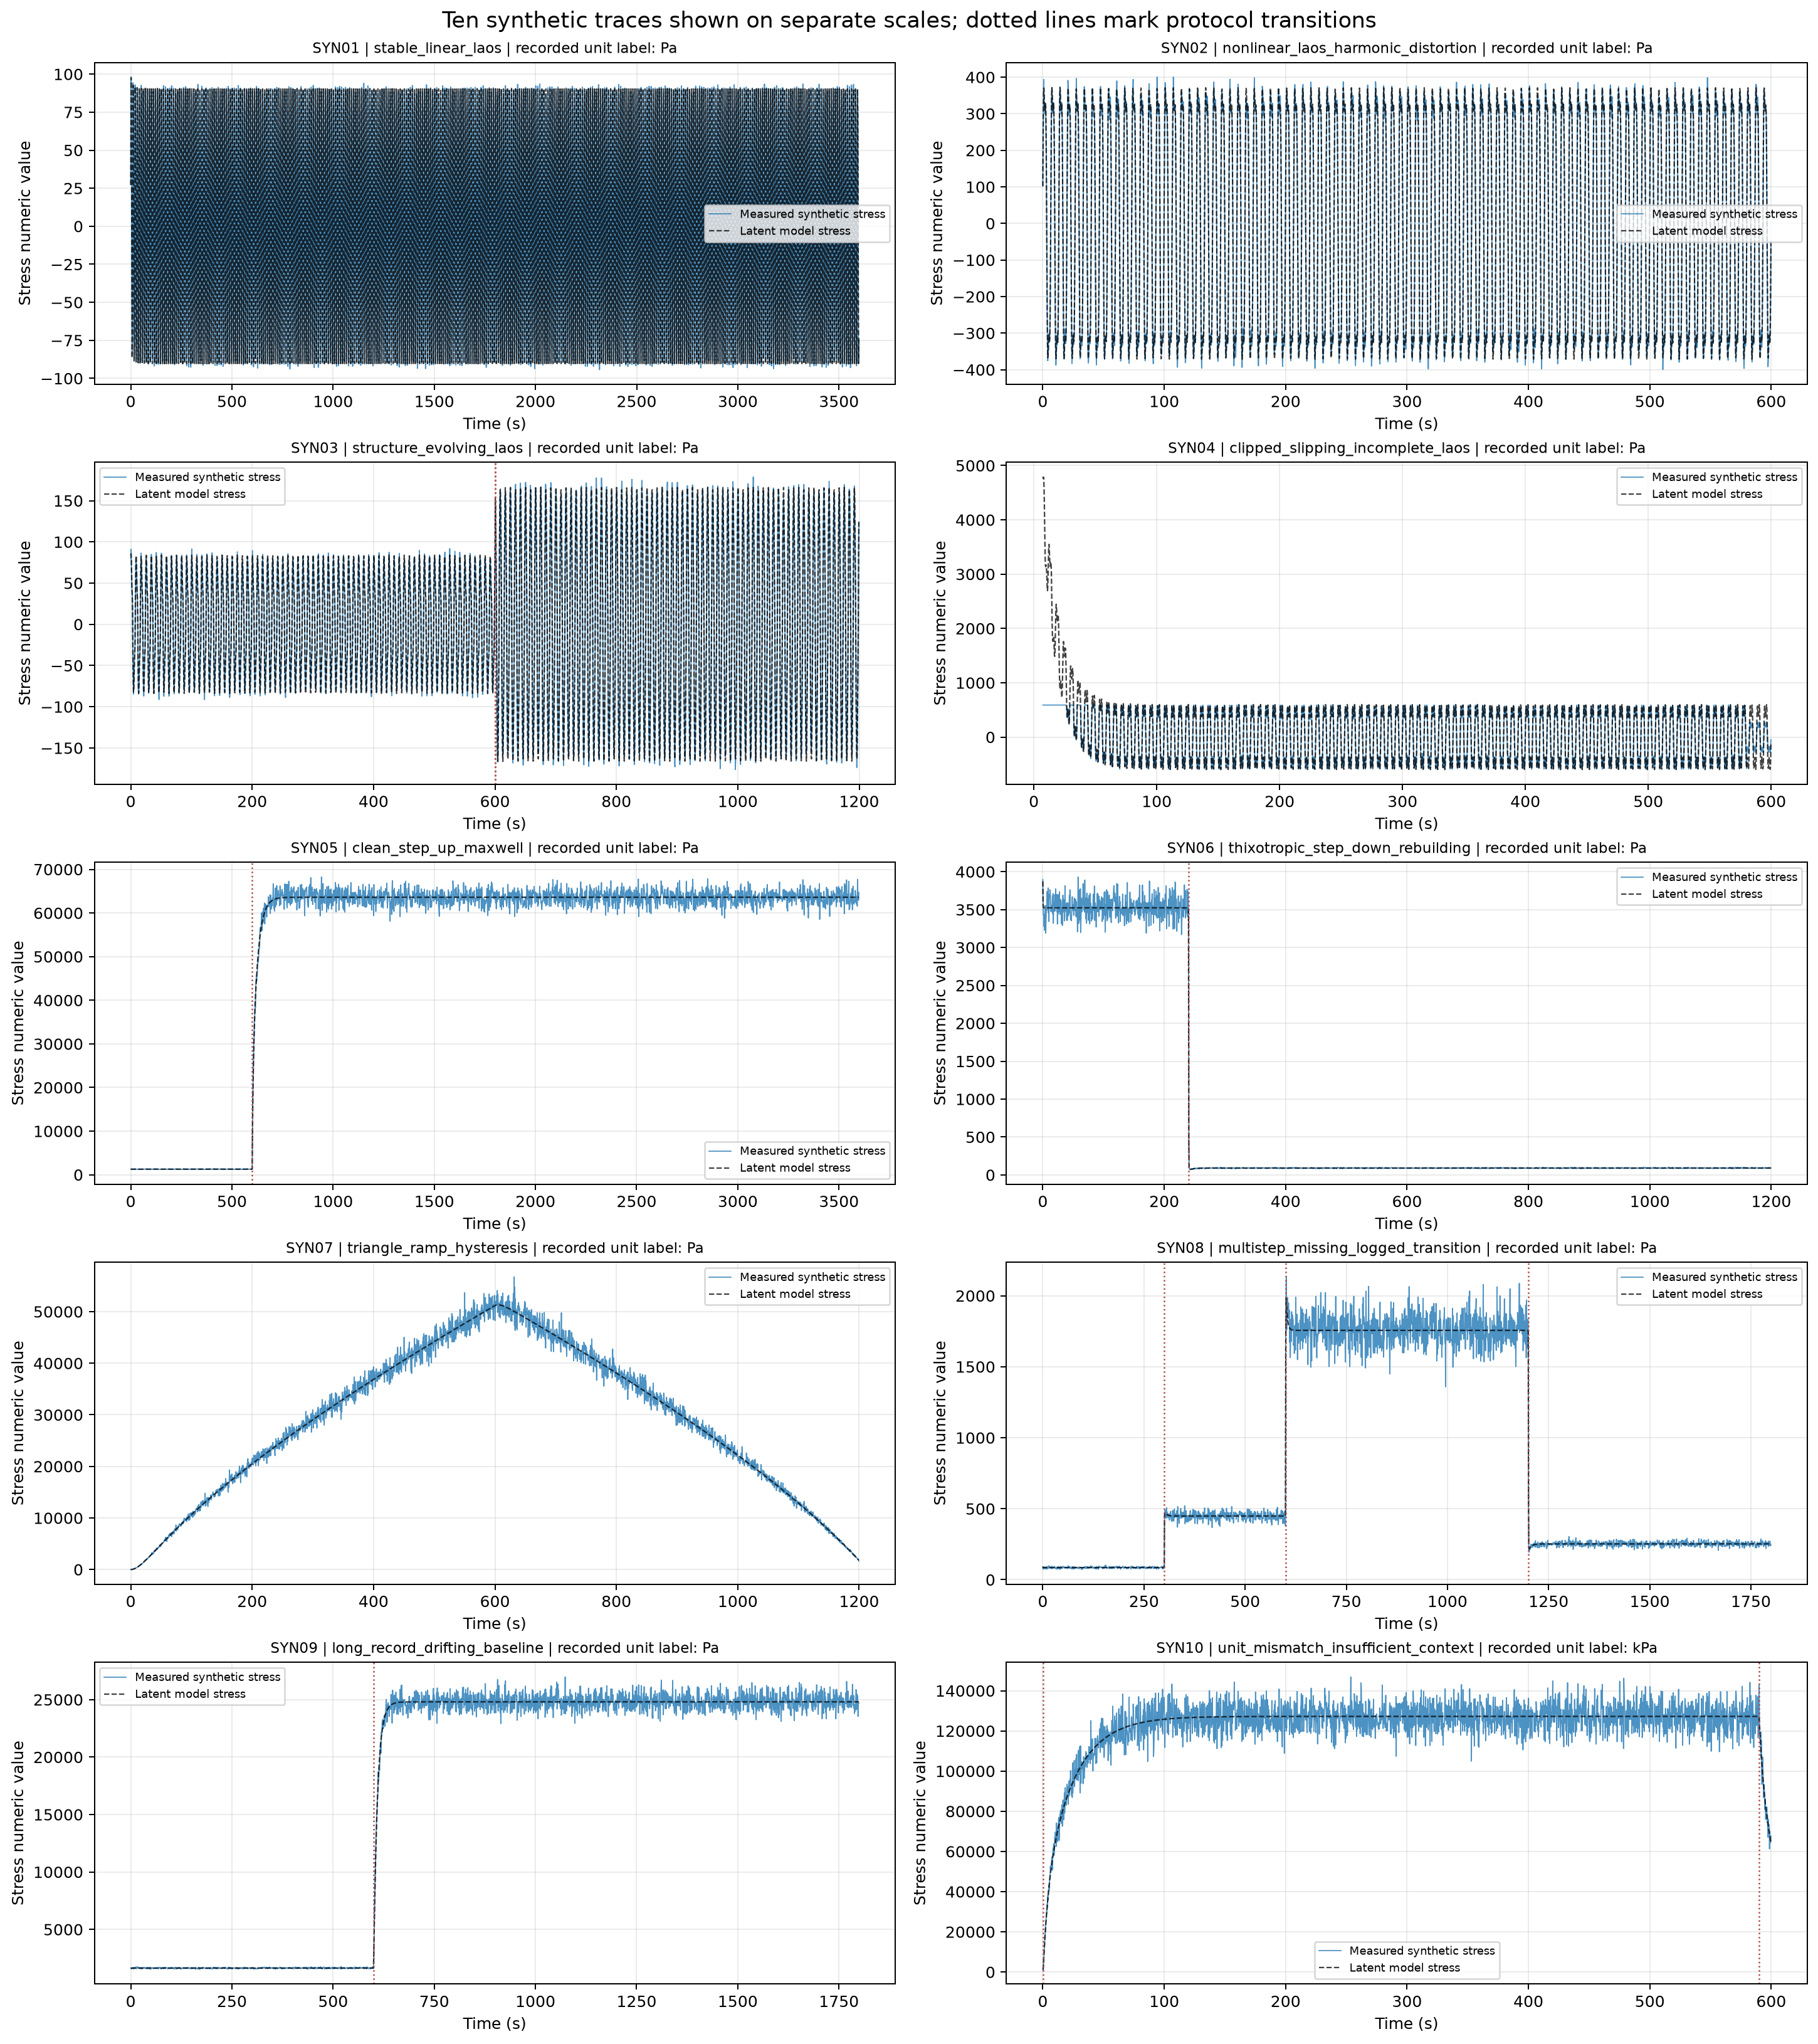

In [5]:
support_records = []
for configuration, experiment_dataframe in zip(scenario_configurations, synthetic_experiment_dataframes):
    time_intervals_s = np.diff(experiment_dataframe["time_s"].to_numpy())
    median_interval_s = float(np.median(time_intervals_s))
    interval_mad_ratio = float(np.median(np.abs(time_intervals_s - median_interval_s)) / median_interval_s)
    samples_per_cycle = (
        configuration["sampling_rate_hz"] / configuration["oscillation_frequency_hz"]
        if configuration["measurement_type"] == "LAOS" else np.nan
    )
    support_records.append({
        "experiment_id": configuration["experiment_id"],
        "measurement_type": configuration["measurement_type"],
        "nominal_sampling_rate_hz": configuration["sampling_rate_hz"],
        "median_observed_interval_s": median_interval_s,
        "interval_mad_ratio": interval_mad_ratio,
        "samples_per_laos_cycle": samples_per_cycle,
        "retained_samples": len(experiment_dataframe),
        "quality_status": configuration["quality_status"],
    })
support_dataframe = pd.DataFrame(support_records)
support_dataframe.to_csv(OUTPUT_DIRECTORY / "sampling_support_audit.csv", index=False)
display(support_dataframe.round(3))

figure, axes = plt.subplots(5, 2, figsize=(16, 18), constrained_layout=True)
for configuration, current_dataframe, axis in zip(
    scenario_configurations, synthetic_experiment_dataframes, axes.flat
):
    plot_stride = max(1, int(np.ceil(len(current_dataframe) / 2500)))
    plotted_dataframe = current_dataframe.iloc[::plot_stride]
    axis.plot(
        plotted_dataframe["time_s"], plotted_dataframe["stress_measured_value"],
        linewidth=0.7, alpha=0.8, label="Measured synthetic stress"
    )
    axis.plot(
        plotted_dataframe["time_s"], plotted_dataframe["stress_truth_pa"],
        color="black", linewidth=0.9, alpha=0.75, linestyle="--", label="Latent model stress"
    )
    for transition_time_s in configuration.get("transition_times_s", []):
        axis.axvline(transition_time_s, color="#b04a4a", linestyle=":", linewidth=1.0)
    if "amplitude_change_time_s" in configuration:
        axis.axvline(
            configuration["amplitude_change_time_s"],
            color="#b04a4a", linestyle=":", linewidth=1.0
        )
    stress_unit_label = current_dataframe["stress_unit_label"].iloc[0]
    axis.set_title(
        configuration["experiment_id"] + " | " + configuration["scenario_name"]
        + " | recorded unit label: " + stress_unit_label,
        fontsize=9
    )
    axis.set_xlabel("Time (s)")
    axis.set_ylabel("Stress numeric value")
    axis.legend(fontsize=7, loc="best")
figure.suptitle(
    "Ten synthetic traces shown on separate scales; dotted lines mark protocol transitions",
    fontsize=14
)
figure.savefig(FIGURE_DIRECTORY / "01_observed_trace_gallery.png", bbox_inches="tight")
plt.show()

## LAOS harmonic methods

Every LAOS method uses the same final ten-cycle time window and a linear detrend. The primary target is the latent third-to-first harmonic amplitude ratio $I_3/I_1$. Fourier regression and global FFT estimate narrowband amplitudes. Multitaper FFT averages three DPSS taper spectra. STFT and complex-Morlet CWT estimate average power near the fundamental and third harmonic and convert the power ratio to an amplitude ratio. DWT uses broad dyadic detail bands, so it has coarser frequency specificity.

The known latent reference is estimated from the noise-free generated waveform with the same harmonic-regression basis. Poor-quality/incomplete traces remain in the results as sensitivity cases and are not treated as clean validation.

In [6]:
def create_uniform_signal_view(experiment_dataframe):
    observed_times = experiment_dataframe["time_s"].to_numpy(dtype=float)
    observed_stress = experiment_dataframe["stress_measured_value"].to_numpy(dtype=float)
    interval_values = np.diff(observed_times)
    median_interval = float(np.median(interval_values[interval_values > 0]))
    uniform_times = np.arange(observed_times[0], observed_times[-1], median_interval)
    uniform_stress = np.interp(uniform_times, observed_times, observed_stress)
    insertion_indices = np.searchsorted(observed_times, uniform_times).clip(0, len(observed_times) - 1)
    previous_indices = np.maximum(insertion_indices - 1, 0)
    distance_after = np.abs(observed_times[insertion_indices] - uniform_times)
    distance_before = np.abs(observed_times[previous_indices] - uniform_times)
    nearest_distances = np.minimum(distance_after, distance_before)
    interpolated_fraction = float(np.mean(nearest_distances > 0.05 * median_interval))
    return uniform_times, uniform_stress, median_interval, interpolated_fraction


def fit_harmonic_amplitudes(time_values, stress_values, fundamental_hz, maximum_harmonic=5):
    centered_times = time_values - np.mean(time_values)
    centered_stress = stress_values - np.mean(stress_values)
    design_columns = [np.ones(len(time_values)), centered_times]
    for harmonic_number in range(1, maximum_harmonic + 1, 2):
        angular_frequency = 2 * np.pi * fundamental_hz * harmonic_number
        design_columns.extend([
            np.sin(angular_frequency * centered_times),
            np.cos(angular_frequency * centered_times),
        ])
    coefficient_values = np.linalg.lstsq(np.column_stack(design_columns), centered_stress, rcond=None)[0]
    amplitude_values = {}
    coefficient_position = 2
    for harmonic_number in range(1, maximum_harmonic + 1, 2):
        amplitude_values[harmonic_number] = float(np.hypot(
            coefficient_values[coefficient_position], coefficient_values[coefficient_position + 1]
        ))
        coefficient_position += 2
    return amplitude_values


def nearest_spectral_amplitude(frequency_values, amplitude_values, target_hz):
    nearest_index = int(np.argmin(np.abs(frequency_values - target_hz)))
    return float(np.max(amplitude_values[max(0, nearest_index - 1):nearest_index + 2]))


def dwt_harmonic_ratio(stress_values, sampling_hz, fundamental_hz, wavelet_name):
    maximum_level = pywt.dwt_max_level(len(stress_values), pywt.Wavelet(wavelet_name).dec_len)
    if maximum_level < 2:
        return np.nan
    detail_arrays = pywt.wavedec(stress_values, wavelet_name, mode="symmetric", level=maximum_level)
    def band_energy(target_hz):
        if target_hz <= 0 or target_hz >= sampling_hz / 2:
            return np.nan
        level_number = int(np.floor(np.log2(sampling_hz / target_hz)))
        level_number = max(1, min(level_number, maximum_level))
        return float(np.mean(detail_arrays[-level_number] ** 2))
    first_energy = band_energy(fundamental_hz)
    third_energy = band_energy(3 * fundamental_hz)
    return float(np.sqrt(third_energy / max(first_energy, 1e-18))) if np.isfinite(third_energy) else np.nan


def compare_laos_methods(experiment_dataframe, configuration):
    uniform_times, uniform_stress, sample_interval, interpolated_fraction = create_uniform_signal_view(experiment_dataframe)
    frequency_hz = configuration["oscillation_frequency_hz"]
    start_time = uniform_times[-1] - 10 / frequency_hz
    common_mask = uniform_times >= start_time
    window_times = uniform_times[common_mask]
    window_stress = signal.detrend(uniform_stress[common_mask], type="linear")
    sampling_hz = 1 / sample_interval
    if len(window_times) < 20:
        return []

    truth_mask = experiment_dataframe["time_s"] >= start_time
    truth_dataframe = experiment_dataframe.loc[truth_mask]
    truth_amplitudes = fit_harmonic_amplitudes(
        truth_dataframe["time_s"].to_numpy(),
        truth_dataframe["stress_truth_pa"].to_numpy(), frequency_hz
    )
    truth_ratio = truth_amplitudes.get(3, np.nan) / max(truth_amplitudes.get(1, np.nan), 1e-12)

    regression_amplitudes = fit_harmonic_amplitudes(window_times, window_stress, frequency_hz)
    regression_ratio = regression_amplitudes[3] / max(regression_amplitudes[1], 1e-12)

    hann_values = signal.windows.hann(len(window_stress), sym=False)
    fft_values = np.fft.rfft(window_stress * hann_values)
    fft_frequencies = np.fft.rfftfreq(len(window_stress), d=sample_interval)
    fft_amplitudes = 2 * np.abs(fft_values) / max(np.sum(hann_values), 1e-12)
    fft_ratio = nearest_spectral_amplitude(fft_frequencies, fft_amplitudes, 3 * frequency_hz) / max(
        nearest_spectral_amplitude(fft_frequencies, fft_amplitudes, frequency_hz), 1e-12
    )

    dpss_values = signal.windows.dpss(len(window_stress), NW=2.5, Kmax=3, sym=False)
    taper_power_arrays = []
    for taper_number in range(3):
        taper_spectrum = np.fft.rfft(window_stress * dpss_values[taper_number])
        taper_power_arrays.append(np.abs(taper_spectrum) ** 2)
    mean_power = np.mean(taper_power_arrays, axis=0)
    multitaper_amplitude = np.sqrt(mean_power)
    multitaper_ratio = nearest_spectral_amplitude(
        fft_frequencies, multitaper_amplitude, 3 * frequency_hz
    ) / max(nearest_spectral_amplitude(fft_frequencies, multitaper_amplitude, frequency_hz), 1e-12)

    stft_window_samples = min(len(window_stress), max(16, int(round(5 / frequency_hz / sample_interval))))
    stft_frequencies, _, stft_coefficients = signal.stft(
        window_stress, fs=sampling_hz, window="hann", nperseg=stft_window_samples,
        noverlap=stft_window_samples // 2, boundary=None, padded=False, detrend="linear"
    )
    stft_power = np.abs(stft_coefficients) ** 2
    frequency_resolution = sampling_hz / stft_window_samples
    first_mask = np.abs(stft_frequencies - frequency_hz) <= frequency_resolution
    third_mask = np.abs(stft_frequencies - 3 * frequency_hz) <= frequency_resolution
    stft_ratio = np.sqrt(np.mean(stft_power[third_mask]) / max(np.mean(stft_power[first_mask]), 1e-18))

    cwt_scales = pywt.frequency2scale(
        "cmor1.5-1.0", np.array([frequency_hz, 3 * frequency_hz]) * sample_interval
    )
    cwt_coefficients, _ = pywt.cwt(
        window_stress, cwt_scales, "cmor1.5-1.0", sampling_period=sample_interval
    )
    cwt_power = np.mean(np.abs(cwt_coefficients) ** 2, axis=1)
    cwt_ratio = np.sqrt(cwt_power[1] / max(cwt_power[0], 1e-18))
    dwt_ratio = dwt_harmonic_ratio(window_stress, sampling_hz, frequency_hz, "db4")

    estimates = {
        "Fourier harmonic regression": regression_ratio,
        "Global FFT, Hann taper": fft_ratio,
        "Multitaper FFT, 3 DPSS tapers": multitaper_ratio,
        "STFT harmonic-band power": stft_ratio,
        "CWT complex-Morlet ridge power": cwt_ratio,
        "DWT db4 detail-band energy": dwt_ratio,
    }
    records = []
    for method_name, estimate in estimates.items():
        records.append({
            "experiment_id": configuration["experiment_id"],
            "scenario_name": configuration["scenario_name"],
            "method": method_name,
            "estimated_i3_i1": estimate,
            "latent_truth_i3_i1": truth_ratio,
            "absolute_error": abs(estimate - truth_ratio) if np.isfinite(estimate) else np.nan,
            "interpolated_fraction": interpolated_fraction,
            "quality_status": configuration["quality_status"],
            "common_window_samples": len(window_times),
        })
    return records


laos_records = []
for configuration, experiment_dataframe in zip(scenario_configurations, synthetic_experiment_dataframes):
    if configuration["measurement_type"] == "LAOS":
        laos_records.extend(compare_laos_methods(experiment_dataframe, configuration))
laos_comparison_dataframe = pd.DataFrame(laos_records)
laos_comparison_dataframe.to_csv(OUTPUT_DIRECTORY / "laos_harmonic_method_comparison.csv", index=False)
display(laos_comparison_dataframe.round(4))

   experiment_id                       scenario_name                          method  estimated_i3_i1  latent_truth_i3_i1  absolute_error  interpolated_fraction quality_status  common_window_samples
0          SYN01                  stable_linear_laos     Fourier harmonic regression           0.0149              0.0150          0.0001                 0.0000           good                    300
1          SYN01                  stable_linear_laos          Global FFT, Hann taper           0.0137              0.0150          0.0013                 0.0000           good                    300
2          SYN01                  stable_linear_laos   Multitaper FFT, 3 DPSS tapers           0.0140              0.0150          0.0010                 0.0000           good                    300
3          SYN01                  stable_linear_laos        STFT harmonic-band power           0.0140              0.0150          0.0010                 0.0000           good                    300
4    

                           method  median_absolute_error  mean_absolute_error  evaluable_runs  median_interpolated_fraction
2     Fourier harmonic regression                 0.0004               0.0009               4                           0.0
5        STFT harmonic-band power                 0.0008               0.0009               4                           0.0
4   Multitaper FFT, 3 DPSS tapers                 0.0009               0.0012               4                           0.0
3          Global FFT, Hann taper                 0.0010               0.0019               4                           0.0
0  CWT complex-Morlet ridge power                 0.0489               0.0632               4                           0.0
1      DWT db4 detail-band energy                 0.1156               0.0989               4                           0.0

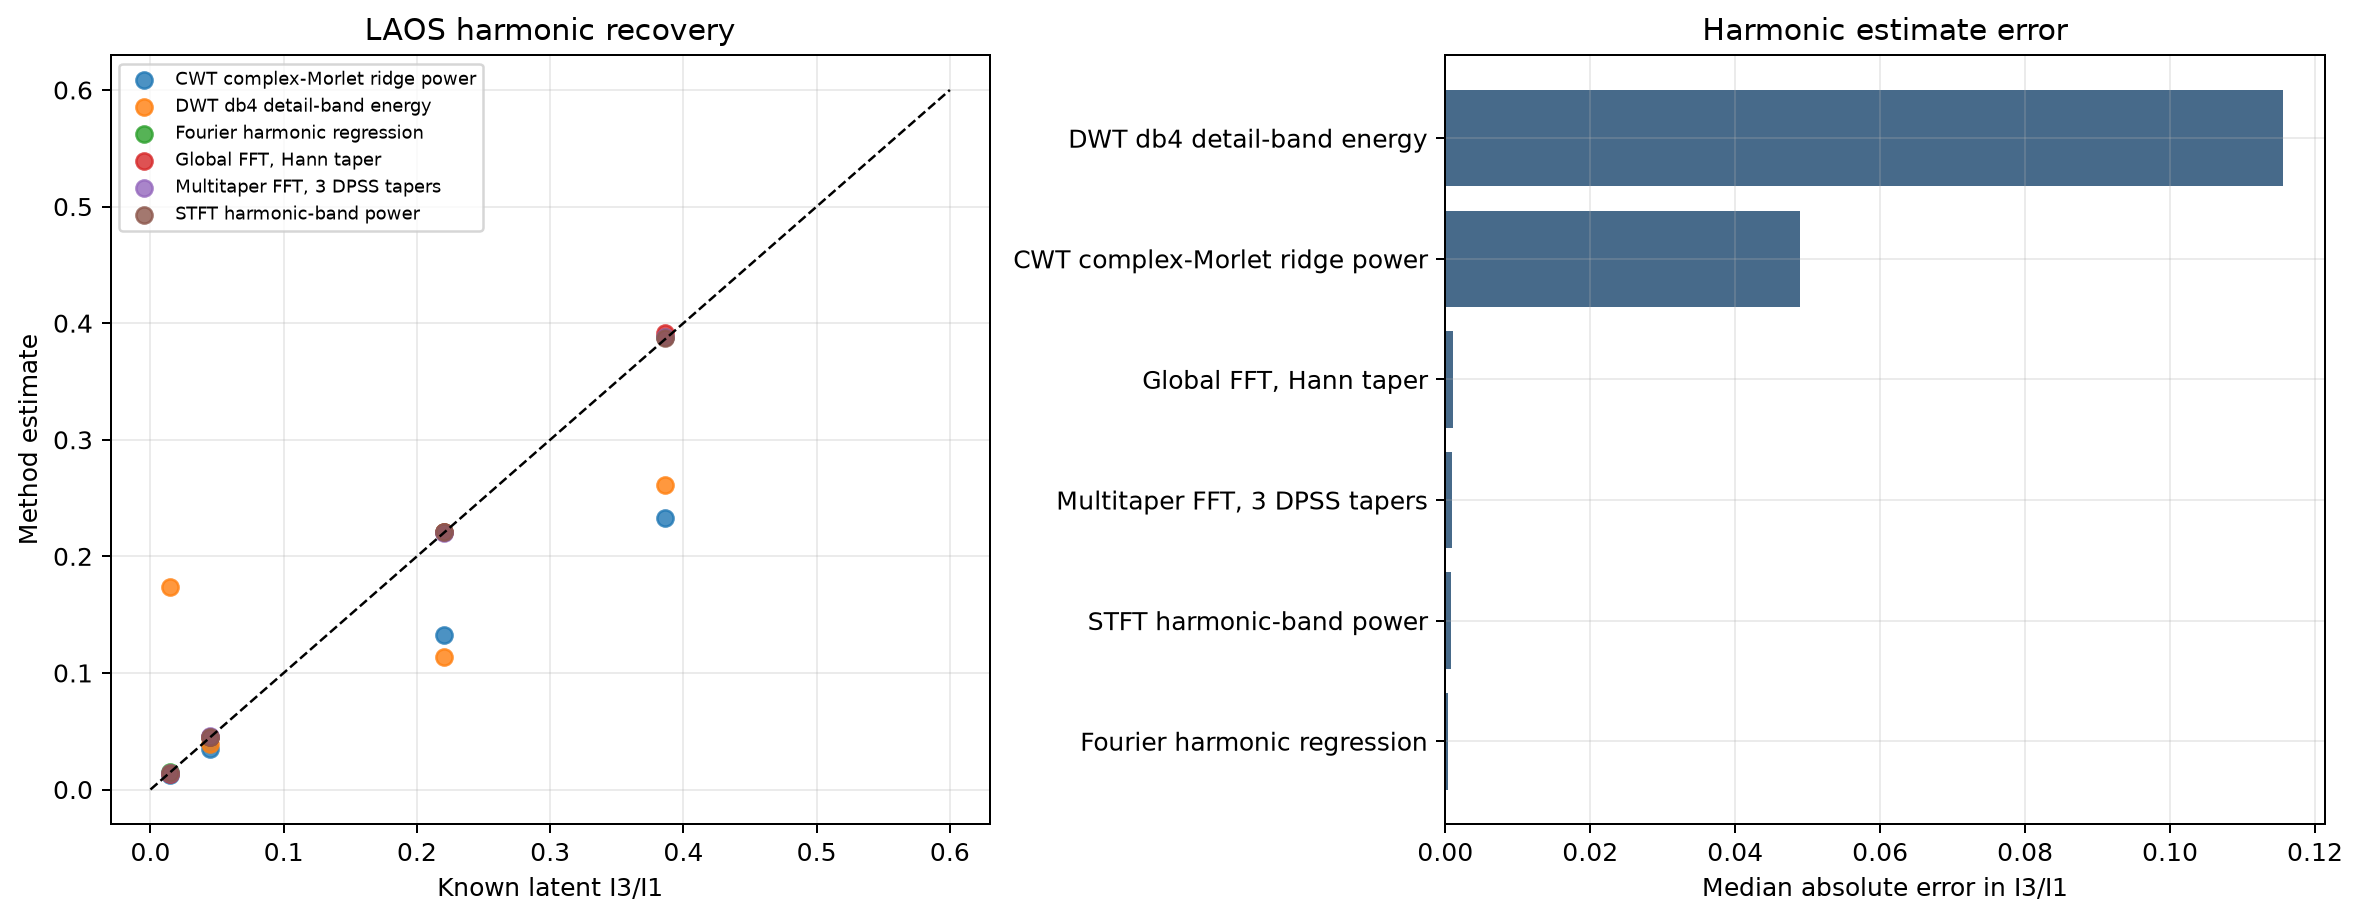

In [7]:
laos_error_summary = (
    laos_comparison_dataframe.groupby("method", as_index=False)
    .agg(
        median_absolute_error=("absolute_error", "median"),
        mean_absolute_error=("absolute_error", "mean"),
        evaluable_runs=("absolute_error", "count"),
        median_interpolated_fraction=("interpolated_fraction", "median"),
    )
    .sort_values("median_absolute_error")
)
laos_comparison_dataframe[[
    "experiment_id", "method", "estimated_i3_i1", "latent_truth_i3_i1", "absolute_error"
]].to_csv(OUTPUT_DIRECTORY / "laos_harmonic_feature_table.csv", index=False)
display(laos_error_summary.round(4))

figure, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for method_name, method_dataframe in laos_comparison_dataframe.groupby("method"):
    axes[0].scatter(
        method_dataframe["latent_truth_i3_i1"], method_dataframe["estimated_i3_i1"],
        label=method_name, s=42, alpha=0.8
    )
axes[0].plot([0, 0.6], [0, 0.6], color="black", linestyle="--", linewidth=1)
axes[0].set_xlabel("Known latent I3/I1")
axes[0].set_ylabel("Method estimate")
axes[0].set_title("LAOS harmonic recovery")
axes[0].legend(fontsize=7)

axes[1].barh(laos_error_summary["method"], laos_error_summary["median_absolute_error"], color="#476a8a")
axes[1].set_xlabel("Median absolute error in I3/I1")
axes[1].set_title("Harmonic estimate error")
figure.savefig(FIGURE_DIRECTORY / "02_laos_harmonic_recovery.png", bbox_inches="tight")
plt.show()

## Step-transient transform comparison

Every local method receives a common 16-second window on the same uniform view. Transient truth is labelled for three configured characteristic times after each known event; this is an explicit operational benchmark window, not a threshold estimated from the measured signal. We compare a time-domain derivative baseline, sliding-window rectangular FFT, Hann STFT, Mexican-hat CWT, and db4/sym4 DWT detail energy. The known label marks the three configured characteristic times following each true step. Per-run AUC measures ranking of transient windows above stable windows. Adjacent windows are correlated, so results are descriptive rather than independent-sample significance tests.

In [8]:
def calculate_auc(binary_labels, feature_scores):
    binary_labels = np.asarray(binary_labels, dtype=bool)
    feature_scores = np.asarray(feature_scores, dtype=float)
    valid_mask = np.isfinite(feature_scores)
    binary_labels = binary_labels[valid_mask]
    feature_scores = feature_scores[valid_mask]
    positive_count = int(np.sum(binary_labels))
    negative_count = len(binary_labels) - positive_count
    if positive_count == 0 or negative_count == 0:
        return np.nan
    rank_values = rankdata(feature_scores)
    return float(
        (np.sum(rank_values[binary_labels]) - positive_count * (positive_count + 1) / 2)
        / (positive_count * negative_count)
    )


def calculate_step_local_features(experiment_dataframe, configuration):
    uniform_times, uniform_stress, sample_interval, interpolated_fraction = create_uniform_signal_view(experiment_dataframe)
    sampling_hz = 1 / sample_interval
    window_samples = min(max(16, int(round(16 * sampling_hz))), max(16, len(uniform_stress) // 3))
    hop_samples = max(1, window_samples // 2)
    centers = np.arange(window_samples // 2, len(uniform_stress) - window_samples // 2, hop_samples)
    records = []
    for center_index in centers:
        start_index = center_index - window_samples // 2
        stop_index = start_index + window_samples
        local_times = uniform_times[start_index:stop_index]
        local_stress = signal.detrend(uniform_stress[start_index:stop_index], type="linear")
        source_index = int(np.clip(
            np.searchsorted(experiment_dataframe["time_s"].to_numpy(), uniform_times[center_index]),
            0, len(experiment_dataframe) - 1
        ))
        truth_label = bool(experiment_dataframe["transient_truth"].iloc[source_index])

        derivative_values = np.diff(local_stress) / sample_interval
        time_score = float(np.sqrt(np.mean(derivative_values ** 2)))
        fft_values = np.fft.rfft(local_stress)
        frequencies = np.fft.rfftfreq(len(local_stress), d=sample_interval)
        power = np.abs(fft_values) ** 2
        high_band = (frequencies >= 0.10 * sampling_hz) & (frequencies <= 0.45 * sampling_hz)
        low_band = (frequencies > 0) & (frequencies < 0.10 * sampling_hz)
        fft_high_energy = float(np.sum(power[high_band]))
        fft_score = fft_high_energy / max(fft_high_energy + float(np.sum(power[low_band])), 1e-18)

        stft_frequencies, _, stft_coefficients = signal.stft(
            local_stress, fs=sampling_hz, window="hann", nperseg=len(local_stress),
            noverlap=0, boundary=None, padded=False
        )
        stft_power = np.abs(stft_coefficients[:, 0]) ** 2
        stft_high = (stft_frequencies >= 0.10 * sampling_hz) & (stft_frequencies <= 0.45 * sampling_hz)
        stft_low = (stft_frequencies > 0) & (stft_frequencies < 0.10 * sampling_hz)
        stft_high_energy = float(np.sum(stft_power[stft_high]))
        stft_score = stft_high_energy / max(stft_high_energy + float(np.sum(stft_power[stft_low])), 1e-18)

        cwt_scales = np.arange(1, min(17, max(2, len(local_stress) // 3)))
        cwt_coefficients, cwt_frequencies = pywt.cwt(
            local_stress, cwt_scales, "mexh", sampling_period=sample_interval
        )
        cwt_high = (cwt_frequencies >= 0.10 * sampling_hz) & (cwt_frequencies <= 0.45 * sampling_hz)
        cwt_high_energy = float(np.sum(np.abs(cwt_coefficients[cwt_high]) ** 2))
        cwt_score = cwt_high_energy / max(float(np.sum(np.abs(cwt_coefficients) ** 2)), 1e-18)

        dwt_scores = {}
        dwt_absolute_energies = {}
        for wavelet_name in ["db4", "sym4"]:
            maximum_level = pywt.dwt_max_level(
                len(local_stress), pywt.Wavelet(wavelet_name).dec_len
            )
            coefficient_arrays = pywt.wavedec(
                local_stress, wavelet_name, mode="symmetric", level=maximum_level
            )
            high_energy = sum(
                float(np.sum(values ** 2))
                for values in coefficient_arrays[-min(2, maximum_level):]
            )
            total_energy = sum(float(np.sum(values ** 2)) for values in coefficient_arrays)
            dwt_scores[wavelet_name] = high_energy / max(total_energy, 1e-18)
            dwt_absolute_energies[wavelet_name] = high_energy

        edge_guard_s = max(1.0, 2 * sample_interval)
        edge_window = bool(
            local_times[0] - uniform_times[0] < edge_guard_s
            or uniform_times[-1] - local_times[-1] < edge_guard_s
        )
        method_scores = {
            "Time-domain derivative RMS": time_score,
            "Sliding-window FFT high-frequency fraction": fft_score,
            "Sliding-window FFT high-frequency energy": fft_high_energy,
            "STFT high-frequency fraction": stft_score,
            "STFT high-frequency energy": stft_high_energy,
            "CWT Mexican-hat high-frequency fraction": cwt_score,
            "CWT Mexican-hat high-frequency energy": cwt_high_energy,
            "DWT db4 relative high-detail energy": dwt_scores["db4"],
            "DWT db4 absolute high-detail energy": dwt_absolute_energies["db4"],
            "DWT sym4 relative high-detail energy": dwt_scores["sym4"],
            "DWT sym4 absolute high-detail energy": dwt_absolute_energies["sym4"],
        }
        for method_name, feature_score in method_scores.items():
            records.append({
                "experiment_id": configuration["experiment_id"],
                "scenario_name": configuration["scenario_name"],
                "method": method_name,
                "window_center_time_s": float(uniform_times[center_index]),
                "feature_score": feature_score,
                "transient_truth": truth_label,
                "edge_window": edge_window,
                "interpolated_fraction": interpolated_fraction,
                "window_samples": window_samples,
                "window_duration_s": float(local_times[-1] - local_times[0]),
            })
    return records


step_evaluation_ids = ["SYN05", "SYN06", "SYN08", "SYN09", "SYN10"]
step_feature_records = []
for configuration, experiment_dataframe in zip(scenario_configurations, synthetic_experiment_dataframes):
    if configuration["experiment_id"] in step_evaluation_ids:
        step_feature_records.extend(calculate_step_local_features(experiment_dataframe, configuration))
step_features_dataframe = pd.DataFrame(step_feature_records)
step_features_dataframe.to_csv(OUTPUT_DIRECTORY / "step_local_transform_features.csv", index=False)
print(f"Computed {len(step_features_dataframe):,} method-window features.")

Computed 12,287 method-window features.


   experiment_id                                      method  transient_window_auc  evaluable_windows  transient_windows  stable_windows  interpolated_fraction  pre_post_context_valid
0          SYN05       CWT Mexican-hat high-frequency energy                 0.300                447                  9             438                    0.0                    True
1          SYN05     CWT Mexican-hat high-frequency fraction                 0.469                447                  9             438                    0.0                    True
2          SYN05         DWT db4 absolute high-detail energy                 0.249                447                  9             438                    0.0                    True
3          SYN05         DWT db4 relative high-detail energy                 0.255                447                  9             438                    0.0                    True
4          SYN05        DWT sym4 absolute high-detail energy                 0.2

                                        method  median_auc  mean_auc  evaluated_experiments  median_evaluable_windows
0        CWT Mexican-hat high-frequency energy       0.564     0.514                      4                     222.5
8     Sliding-window FFT high-frequency energy       0.502     0.474                      4                     222.5
6                   STFT high-frequency energy       0.464     0.467                      4                     222.5
10                  Time-domain derivative RMS       0.459     0.445                      4                     222.5
4         DWT sym4 absolute high-detail energy       0.455     0.444                      4                     222.5
2          DWT db4 absolute high-detail energy       0.450     0.436                      4                     222.5
7                 STFT high-frequency fraction       0.370     0.348                      4                     222.5
1      CWT Mexican-hat high-frequency fraction       0.3

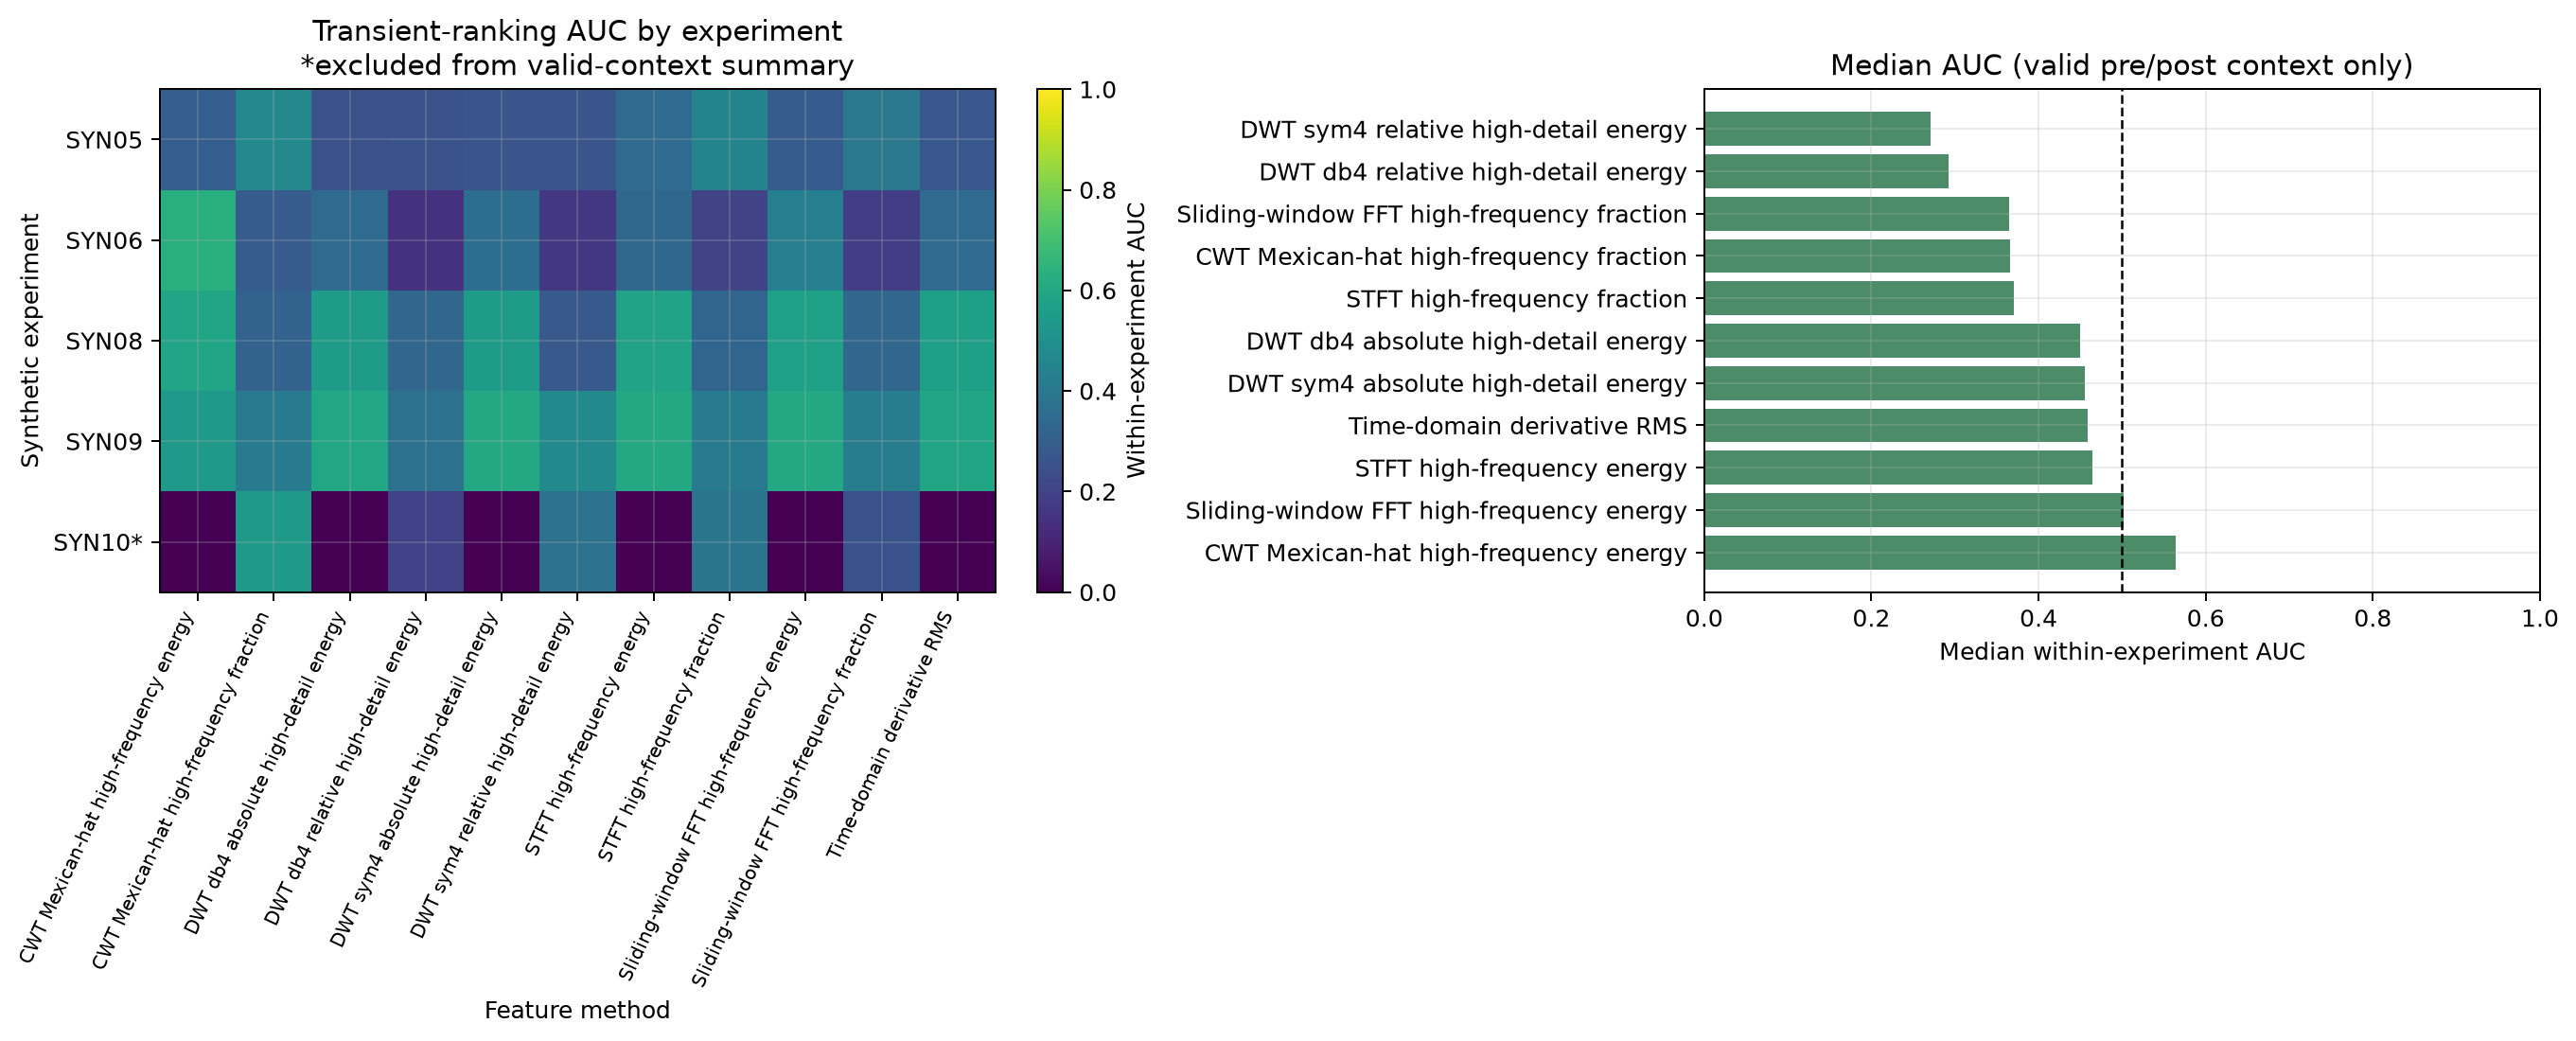

In [9]:
step_score_records = []
for experiment_id, experiment_data in step_features_dataframe.groupby("experiment_id"):
    for method_name, method_data in experiment_data.groupby("method"):
        valid_windows = method_data.loc[~method_data["edge_window"]]
        step_score_records.append({
            "experiment_id": experiment_id,
            "method": method_name,
            "transient_window_auc": calculate_auc(valid_windows["transient_truth"], valid_windows["feature_score"]),
            "evaluable_windows": len(valid_windows),
            "transient_windows": int(valid_windows["transient_truth"].sum()),
            "stable_windows": int((~valid_windows["transient_truth"]).sum()),
            "interpolated_fraction": float(method_data["interpolated_fraction"].median()),
        })
step_comparison_dataframe = pd.DataFrame(step_score_records)
step_comparison_dataframe["pre_post_context_valid"] = step_comparison_dataframe["experiment_id"] != "SYN10"
step_comparison_dataframe.to_csv(OUTPUT_DIRECTORY / "step_transient_method_comparison_by_experiment.csv", index=False)
step_summary_dataframe = (
    step_comparison_dataframe.loc[step_comparison_dataframe["pre_post_context_valid"]].groupby("method", as_index=False)
    .agg(
        median_auc=("transient_window_auc", "median"),
        mean_auc=("transient_window_auc", "mean"),
        evaluated_experiments=("transient_window_auc", "count"),
        median_evaluable_windows=("evaluable_windows", "median"),
    )
    .sort_values("median_auc", ascending=False)
)
display(step_comparison_dataframe.round(3))
display(step_summary_dataframe.round(3))

figure, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
step_auc_pivot = step_comparison_dataframe.pivot(
    index="experiment_id", columns="method", values="transient_window_auc"
)
heatmap_image = axes[0].imshow(
    step_auc_pivot.to_numpy(), aspect="auto", vmin=0, vmax=1, cmap="viridis"
)
axes[0].set_xticks(np.arange(len(step_auc_pivot.columns)))
axes[0].set_xticklabels(step_auc_pivot.columns, rotation=65, ha="right", fontsize=8)
axes[0].set_yticks(np.arange(len(step_auc_pivot.index)))
heatmap_experiment_labels = []
for experiment_id in step_auc_pivot.index:
    experiment_context_valid = bool(
        step_comparison_dataframe.loc[
            step_comparison_dataframe["experiment_id"] == experiment_id,
            "pre_post_context_valid"
        ].iloc[0]
    )
    if experiment_context_valid:
        heatmap_experiment_labels.append(experiment_id)
    else:
        heatmap_experiment_labels.append(experiment_id + "*")
axes[0].set_yticklabels(heatmap_experiment_labels)
axes[0].set_title("Transient-ranking AUC by experiment\n*excluded from valid-context summary")
axes[0].set_xlabel("Feature method")
axes[0].set_ylabel("Synthetic experiment")
figure.colorbar(heatmap_image, ax=axes[0], label="Within-experiment AUC")

axes[1].barh(
    step_summary_dataframe["method"],
    step_summary_dataframe["median_auc"],
    color="#4d8c69"
)
axes[1].axvline(0.5, color="black", linestyle="--", linewidth=1)
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("Median within-experiment AUC")
axes[1].set_title("Median AUC (valid pre/post context only)")
figure.savefig(FIGURE_DIRECTORY / "03_step_transient_method_comparison.png", bbox_inches="tight")
plt.show()

## Fault checks and triangle-ramp hysteresis

The quality checks are transparent triage rules, not a validated classifier. The triangle-ramp area is integrated using measured and latent stress-rate pairs with the same numerical rule. Area is an aggregate loop descriptor, not a direct measure of a specific microstructure.

  experiment_id                                                          known_faults  timestamp_irregularity_flag  possible_clipping_flag  unit_label_mismatch_flag  command_channel_disagreement_flag  short_pre_event_context_flag  short_post_event_context_flag  pre_event_linear_trend_pa_s  large_pre_event_trend_flag           assigned_quality_status  retained_samples
0         SYN01                                                                  none                        False                   False                     False                              False                         False                          False                          NaN                       False                              good             10800
1         SYN02                                                                  none                        False                   False                     False                              False                         False                          False

  experiment_id  latent_signed_loop_area_pa_per_s  measured_signed_loop_area_pa_per_s  absolute_area_error  relative_absolute_area_error
0         SYN07                        -7938.7299                          -7890.7231              48.0068                         0.006

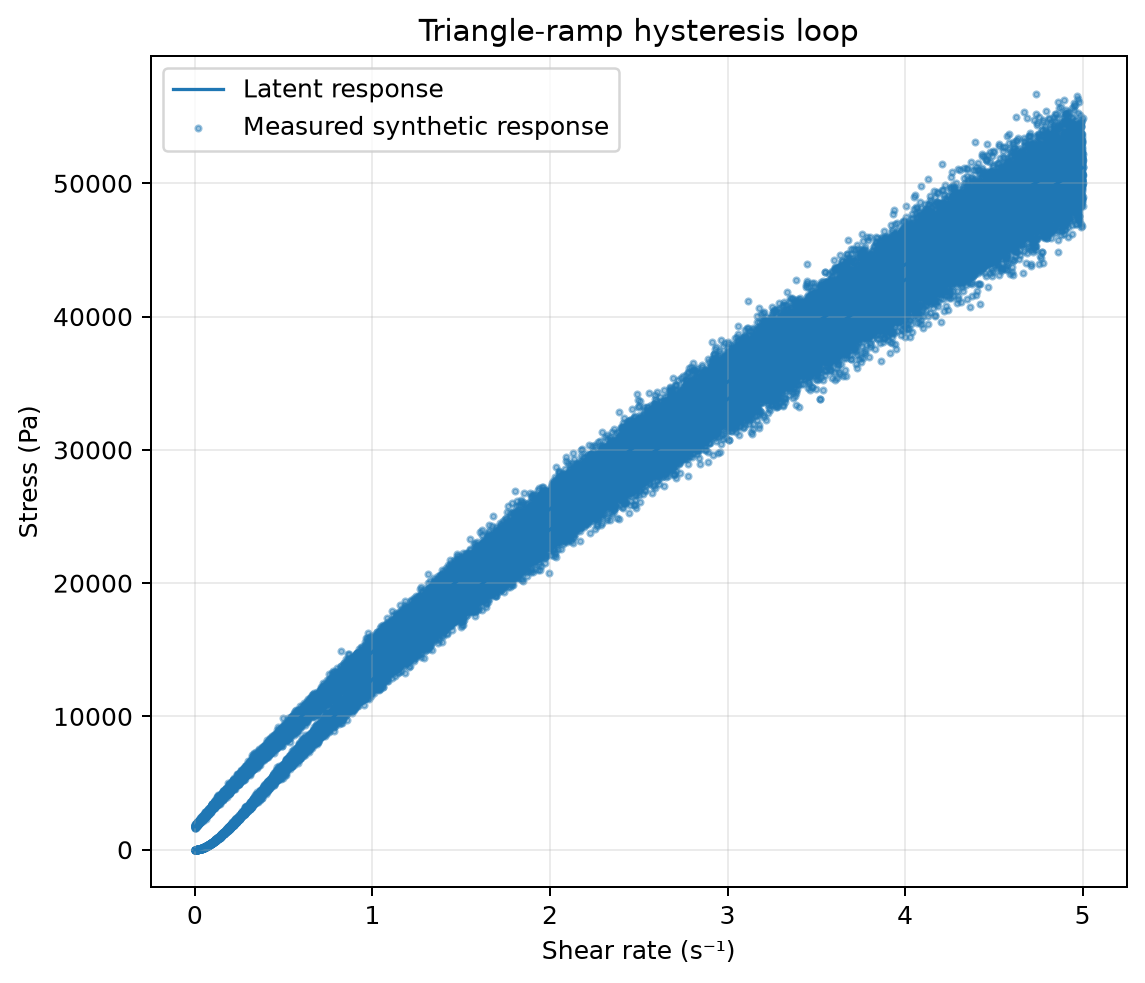

In [10]:
quality_records = []
for configuration, experiment_dataframe in zip(scenario_configurations, synthetic_experiment_dataframes):
    time_values = experiment_dataframe["time_s"].to_numpy()
    stress_values = experiment_dataframe["stress_measured_value"].to_numpy()
    intervals = np.diff(time_values)
    nominal_interval = 1 / configuration["sampling_rate_hz"]
    interval_ratios = intervals / nominal_interval
    timestamp_flag = bool(np.std(interval_ratios) > 0.08 or np.any(interval_ratios > 1.8))
    rounded_absolute_stress = np.round(np.abs(stress_values), 6)
    plateau_counts = np.unique(rounded_absolute_stress, return_counts=True)[1]
    clipping_flag = bool(np.max(plateau_counts) > 0.01 * len(stress_values))
    unit_flag = bool(
        experiment_dataframe["stress_unit_label"].iloc[0] == "kPa"
        and np.nanpercentile(np.abs(stress_values), 95) > 100
    )
    command_disagreement_flag = bool(np.max(np.abs(
        experiment_dataframe["shear_rate_measured_s_inv"].to_numpy()
        - experiment_dataframe["shear_rate_command_s_inv"].to_numpy()
    )) > 0.25)
    early_transition_flag = any(
        event_time < 30 for event_time in configuration.get("transition_times_s", [])
    )
    late_transition_flag = any(
        configuration["duration_s"] - event_time < 30
        for event_time in configuration.get("transition_times_s", [])
    )
    configured_transitions = configuration.get("transition_times_s", [])
    first_transition_s = min(configured_transitions) if configured_transitions else configuration["duration_s"]
    steady_pre_event_protocol = configuration["measurement_type"] in ["step", "multistep"] and first_transition_s >= 90
    baseline_window_mask = steady_pre_event_protocol & (time_values >= 60) & (time_values < min(first_transition_s, 500))
    if np.sum(baseline_window_mask) >= 20:
        pre_event_trend_pa_s = float(np.polyfit(time_values[baseline_window_mask], stress_values[baseline_window_mask], 1)[0])
    else:
        pre_event_trend_pa_s = np.nan
    large_pre_event_trend_flag = bool(
        configuration["duration_s"] >= 1800
        and np.isfinite(pre_event_trend_pa_s)
        and abs(pre_event_trend_pa_s) > 0.008
    )
    quality_records.append({
        "experiment_id": configuration["experiment_id"],
        "known_faults": ", ".join(configuration["artifacts"]) if configuration["artifacts"] else "none",
        "timestamp_irregularity_flag": timestamp_flag,
        "possible_clipping_flag": clipping_flag,
        "unit_label_mismatch_flag": unit_flag,
        "command_channel_disagreement_flag": command_disagreement_flag,
        "short_pre_event_context_flag": early_transition_flag,
        "short_post_event_context_flag": late_transition_flag,
        "pre_event_linear_trend_pa_s": pre_event_trend_pa_s,
        "large_pre_event_trend_flag": large_pre_event_trend_flag,
        "assigned_quality_status": configuration["quality_status"],
        "retained_samples": len(experiment_dataframe),
    })
quality_dataframe = pd.DataFrame(quality_records)
quality_dataframe.to_csv(OUTPUT_DIRECTORY / "quality_check_summary.csv", index=False)
display(quality_dataframe)

triangle_dataframe = synthetic_experiment_dataframes[6]
measured_loop_area = float(np.trapezoid(
    triangle_dataframe["stress_measured_value"], triangle_dataframe["shear_rate_measured_s_inv"]
))
latent_loop_area = float(np.trapezoid(
    triangle_dataframe["stress_truth_pa"], triangle_dataframe["shear_rate_truth_s_inv"]
))
triangle_area_dataframe = pd.DataFrame([{
    "experiment_id": "SYN07",
    "latent_signed_loop_area_pa_per_s": latent_loop_area,
    "measured_signed_loop_area_pa_per_s": measured_loop_area,
    "absolute_area_error": abs(measured_loop_area - latent_loop_area),
    "relative_absolute_area_error": abs(measured_loop_area - latent_loop_area) / max(abs(latent_loop_area), 1e-12),
}])
triangle_area_dataframe.to_csv(OUTPUT_DIRECTORY / "triangle_ramp_hysteresis_area.csv", index=False)
display(triangle_area_dataframe.round(4))

figure, axis = plt.subplots(figsize=(7, 6))
axis.plot(triangle_dataframe["shear_rate_truth_s_inv"], triangle_dataframe["stress_truth_pa"], label="Latent response", linewidth=1.3)
axis.scatter(triangle_dataframe["shear_rate_measured_s_inv"], triangle_dataframe["stress_measured_value"], label="Measured synthetic response", s=5, alpha=0.45)
axis.set_xlabel("Shear rate (s⁻¹)")
axis.set_ylabel("Stress (Pa)")
axis.set_title("Triangle-ramp hysteresis loop")
axis.legend()
figure.savefig(FIGURE_DIRECTORY / "04_triangle_ramp_hysteresis.png", bbox_inches="tight")
plt.show()

## Sensitivity: sampling rate, noise, analysis window, and CWT edges

A controlled nonlinear-LAOS sweep regenerates the same case at 1, 3, 10, 50, and 100 Hz; adds 1%, 5%, and 15% noise; and compares 3-, 5-, and 8-cycle windows. Fourier regression and multitaper FFT are compared. The 1 Hz case puts the third harmonic close to Nyquist, intentionally testing the acquisition limit. A separate CWT check reports the effect of removing scale-dependent edge regions.

    sampling_rate_hz  noise_fraction  window_cycles                       method  median_absolute_error
0                  1            0.01              3  Fourier harmonic regression                 0.0018
1                  1            0.01              3               Multitaper FFT                 0.0772
2                  1            0.01              5  Fourier harmonic regression                 0.0020
3                  1            0.01              5               Multitaper FFT                 0.0075
4                  1            0.01              8  Fourier harmonic regression                 0.0026
5                  1            0.01              8               Multitaper FFT                 0.0074
6                  1            0.05              3  Fourier harmonic regression                 0.0053
7                  1            0.05              3               Multitaper FFT                 0.0786
8                  1            0.05              5  Fourier har

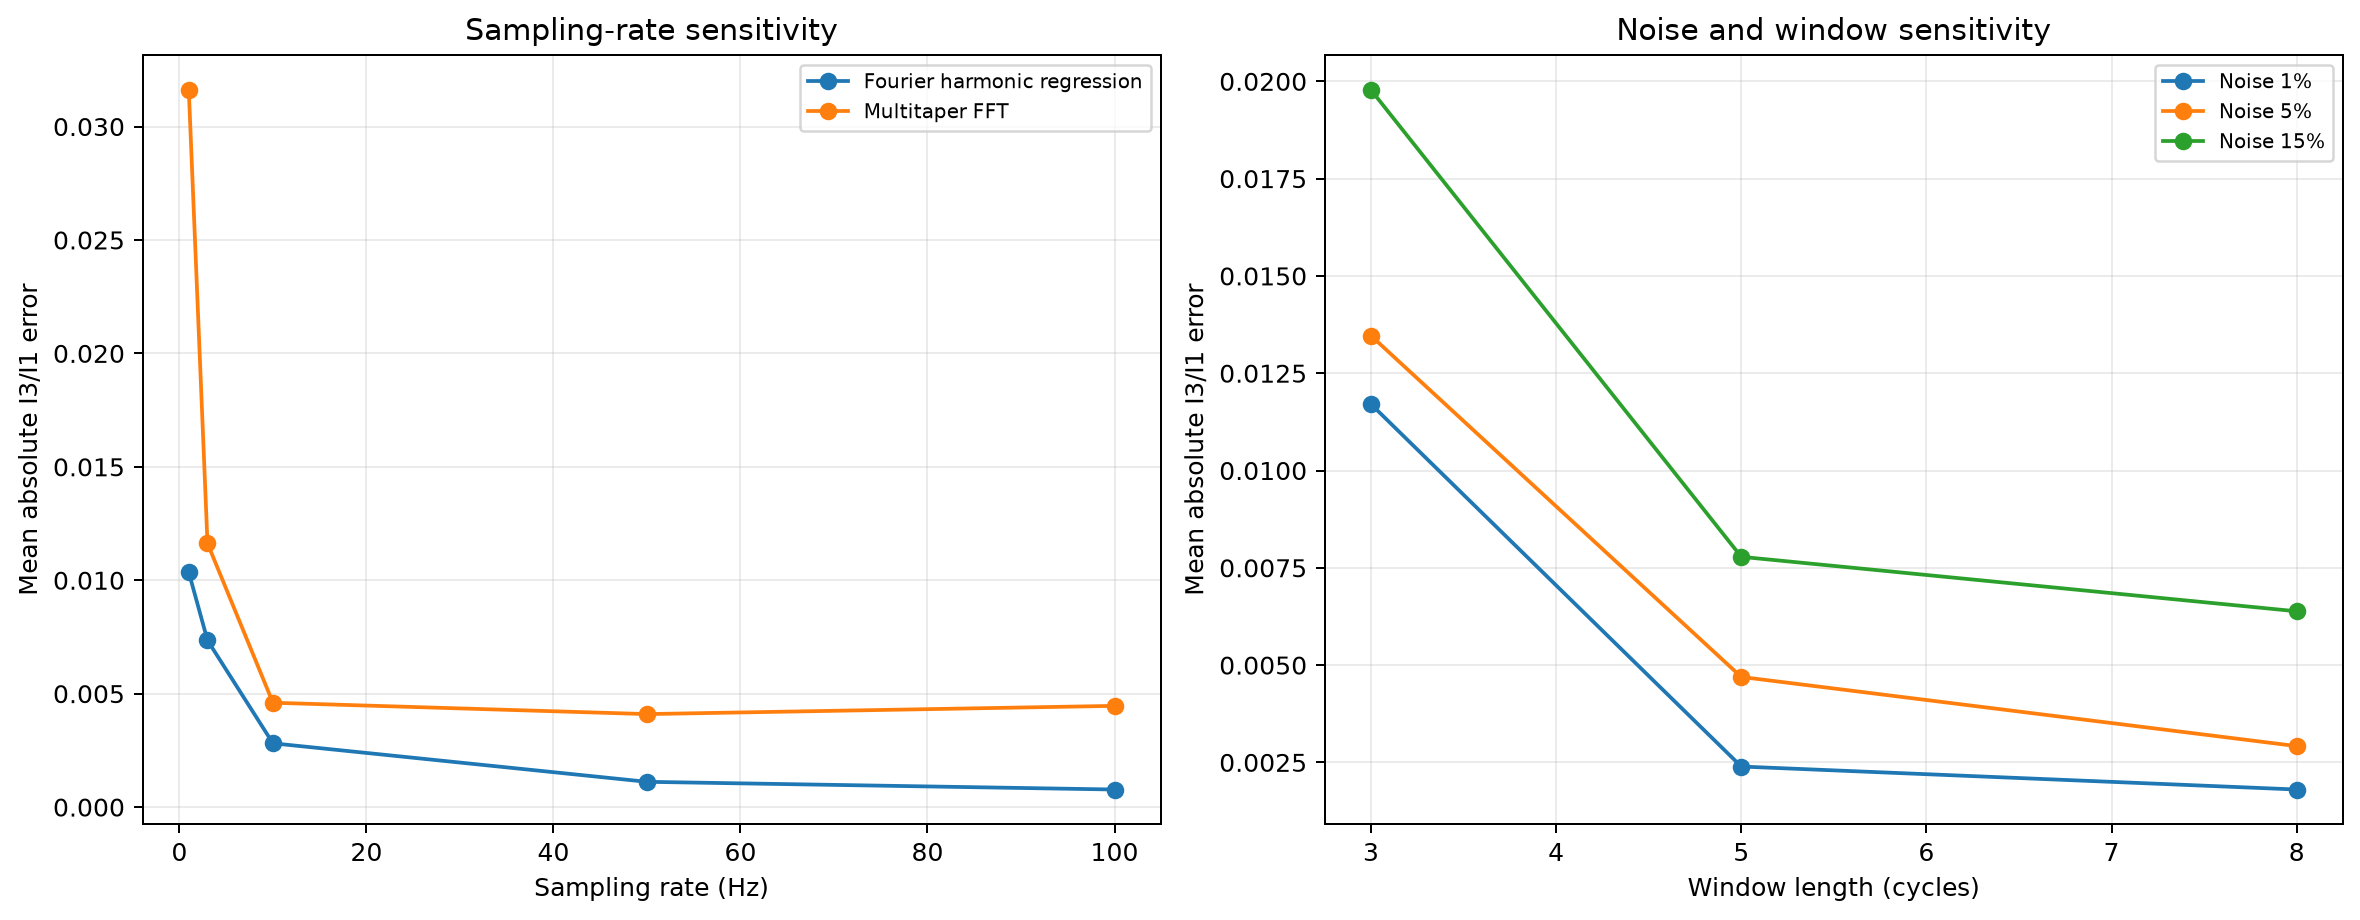

  experiment_id  cwt_full_record_i3_i1  cwt_edge_trimmed_i3_i1  edge_guard_samples  edge_guard_duration_s
0         SYN02                 0.1275                  0.1269                1667                  33.34

In [11]:
def estimate_harmonic_ratio_in_cycles(time_values, stress_values, frequency_hz, cycle_count):
    start_time = time_values[-1] - cycle_count / frequency_hz
    selected_mask = time_values >= start_time
    selected_times = time_values[selected_mask]
    selected_stress = stress_values[selected_mask]
    amplitudes = fit_harmonic_amplitudes(selected_times, selected_stress, frequency_hz, maximum_harmonic=3)
    return float(amplitudes[3] / max(amplitudes[1], 1e-12)), selected_times, selected_stress


sensitivity_configuration = dict(scenario_configurations[1])
sensitivity_records = []
for sampling_hz in [1, 3, 10, 50, 100]:
    sensitivity_configuration["sampling_rate_hz"] = sampling_hz
    sensitivity_times = np.arange(int(sensitivity_configuration["duration_s"] * sampling_hz)) / sampling_hz
    sensitivity_rates = generate_shear_rate(sensitivity_configuration, sensitivity_times)
    latent_stress, _ = simulate_latent_rheology(sensitivity_configuration, sensitivity_times, sensitivity_rates)
    reference_ratio, _, _ = estimate_harmonic_ratio_in_cycles(
        sensitivity_times, latent_stress, sensitivity_configuration["oscillation_frequency_hz"], 8
    )
    for noise_fraction in [0.01, 0.05, 0.15]:
        noise_generator = np.random.default_rng(
            RANDOM_SEED + sampling_hz * 100 + int(noise_fraction * 1000)
        )
        noise_scale = max(np.std(latent_stress) * noise_fraction, 1e-8)
        noisy_stress = latent_stress + noise_generator.normal(0, noise_scale, len(latent_stress))
        for cycle_count in [3, 5, 8]:
            regression_ratio, window_times, window_stress = estimate_harmonic_ratio_in_cycles(
                sensitivity_times, noisy_stress,
                sensitivity_configuration["oscillation_frequency_hz"], cycle_count
            )
            sensitivity_records.append({
                "sampling_rate_hz": sampling_hz, "noise_fraction": noise_fraction,
                "window_cycles": cycle_count, "method": "Fourier harmonic regression",
                "estimate": regression_ratio, "latent_reference": reference_ratio,
                "absolute_error": abs(regression_ratio - reference_ratio),
                "samples_per_cycle": sampling_hz / sensitivity_configuration["oscillation_frequency_hz"],
                "third_harmonic_below_nyquist": 3 * sensitivity_configuration["oscillation_frequency_hz"] < sampling_hz / 2,
            })

            interval_s = 1 / sampling_hz
            detrended_stress = signal.detrend(window_stress, type="linear")
            tapers = signal.windows.dpss(len(detrended_stress), NW=2.5, Kmax=3, sym=False)
            powers = [
                np.abs(np.fft.rfft(detrended_stress * tapers[index])) ** 2
                for index in range(3)
            ]
            frequencies = np.fft.rfftfreq(len(detrended_stress), d=interval_s)
            mean_amplitude = np.sqrt(np.mean(powers, axis=0))
            fundamental_amplitude = nearest_spectral_amplitude(
                frequencies, mean_amplitude, sensitivity_configuration["oscillation_frequency_hz"]
            )
            third_amplitude = nearest_spectral_amplitude(
                frequencies, mean_amplitude, 3 * sensitivity_configuration["oscillation_frequency_hz"]
            )
            multitaper_ratio = third_amplitude / max(fundamental_amplitude, 1e-12)
            sensitivity_records.append({
                "sampling_rate_hz": sampling_hz, "noise_fraction": noise_fraction,
                "window_cycles": cycle_count, "method": "Multitaper FFT",
                "estimate": multitaper_ratio, "latent_reference": reference_ratio,
                "absolute_error": abs(multitaper_ratio - reference_ratio),
                "samples_per_cycle": sampling_hz / sensitivity_configuration["oscillation_frequency_hz"],
                "third_harmonic_below_nyquist": 3 * sensitivity_configuration["oscillation_frequency_hz"] < sampling_hz / 2,
            })

sensitivity_dataframe = pd.DataFrame(sensitivity_records)
sensitivity_dataframe.to_csv(OUTPUT_DIRECTORY / "laos_sampling_noise_window_sensitivity.csv", index=False)
sensitivity_summary = (
    sensitivity_dataframe.groupby(["sampling_rate_hz", "noise_fraction", "window_cycles", "method"], as_index=False)
    .agg(median_absolute_error=("absolute_error", "median"))
)
display(sensitivity_summary.head(18).round(4))

figure, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for method_name, method_data in sensitivity_summary.groupby("method"):
    rate_error = method_data.groupby("sampling_rate_hz")["median_absolute_error"].mean()
    axes[0].plot(rate_error.index, rate_error.values, marker="o", label=method_name)
axes[0].set_xlabel("Sampling rate (Hz)")
axes[0].set_ylabel("Mean absolute I3/I1 error")
axes[0].set_title("Sampling-rate sensitivity")
axes[0].legend(fontsize=8)
for noise_fraction, noise_data in sensitivity_summary.groupby("noise_fraction"):
    window_error = noise_data.groupby("window_cycles")["median_absolute_error"].mean()
    axes[1].plot(window_error.index, window_error.values, marker="o", label=f"Noise {noise_fraction:.0%}")
axes[1].set_xlabel("Window length (cycles)")
axes[1].set_ylabel("Mean absolute I3/I1 error")
axes[1].set_title("Noise and window sensitivity")
axes[1].legend(fontsize=8)
figure.savefig(FIGURE_DIRECTORY / "05_sampling_noise_window_sensitivity.png", bbox_inches="tight")
plt.show()

edge_configuration = scenario_configurations[1]
edge_dataframe = synthetic_experiment_dataframes[1]
edge_times, edge_stress, edge_interval, _ = create_uniform_signal_view(edge_dataframe)
edge_frequency = edge_configuration["oscillation_frequency_hz"]
edge_scales = pywt.frequency2scale(
    "cmor1.5-1.0", np.array([edge_frequency, 3 * edge_frequency]) * edge_interval
)
edge_coefficients, _ = pywt.cwt(
    edge_stress, edge_scales, "cmor1.5-1.0", sampling_period=edge_interval
)
full_power = np.mean(np.abs(edge_coefficients) ** 2, axis=1)
full_record_ratio = np.sqrt(full_power[1] / max(full_power[0], 1e-18))
edge_guard_samples = int(np.ceil(5 * np.max(edge_scales)))
interior_power = np.mean(np.abs(edge_coefficients[:, edge_guard_samples:-edge_guard_samples]) ** 2, axis=1)
interior_record_ratio = np.sqrt(interior_power[1] / max(interior_power[0], 1e-18))
edge_sensitivity_dataframe = pd.DataFrame([{
    "experiment_id": edge_configuration["experiment_id"],
    "cwt_full_record_i3_i1": full_record_ratio,
    "cwt_edge_trimmed_i3_i1": interior_record_ratio,
    "edge_guard_samples": edge_guard_samples,
    "edge_guard_duration_s": edge_guard_samples * edge_interval,
}])
edge_sensitivity_dataframe.to_csv(OUTPUT_DIRECTORY / "cwt_edge_effect_sensitivity.csv", index=False)
display(edge_sensitivity_dataframe.round(4))

## Runtime, feature dictionary, and practical requirements

Runtime is measured on the computer executing this notebook; it is a relative implementation check, not a hardware-independent speed claim. Minimum support and online feasibility are summarized separately.

In [12]:
runtime_records = []
for configuration, experiment_dataframe in zip(scenario_configurations, synthetic_experiment_dataframes):
    if configuration["measurement_type"] == "LAOS":
        start_clock = time.perf_counter()
        compare_laos_methods(experiment_dataframe, configuration)
        runtime_records.append({
            "experiment_id": configuration["experiment_id"],
            "task": "All LAOS harmonic methods",
            "elapsed_milliseconds": (time.perf_counter() - start_clock) * 1000,
            "input_samples": len(experiment_dataframe),
        })
    if configuration["experiment_id"] in step_evaluation_ids:
        start_clock = time.perf_counter()
        calculate_step_local_features(experiment_dataframe, configuration)
        runtime_records.append({
            "experiment_id": configuration["experiment_id"],
            "task": "All step local features",
            "elapsed_milliseconds": (time.perf_counter() - start_clock) * 1000,
            "input_samples": len(experiment_dataframe),
        })
runtime_dataframe = pd.DataFrame(runtime_records)
runtime_dataframe.to_csv(OUTPUT_DIRECTORY / "computation_time_summary.csv", index=False)
display(runtime_dataframe.round(2))

requirements_dataframe = pd.DataFrame([
    ["Fourier regression / global FFT","Several complete cycles","Uniform sampling; Nyquist above target harmonics","High after chosen window","Global spectrum does not localize event time"],
    ["Multitaper FFT","Several cycles and enough points for multiple tapers","Uniform sampling and frequency resolution","High for rolling windows","Taper averaging trades variance against resolution"],
    ["STFT","One configured window; longer improves frequency resolution","Uniform sampling or explicit resampling","High with rolling windows","Window sets time-frequency trade-off"],
    ["CWT","Support long enough for selected scales","Uniform sampling and physical scale conversion","Moderate to high with bounded scales","Wavelet and edge effects influence energy"],
    ["DWT","Dyadic blocks; record length affects boundary handling","Uniform sampling or explicit resampling","High for fixed levels","Octave bands are coarse for narrow harmonics"],
    ["Time-domain derivative","At least two points; stable windows improve interpretation","Uses actual timestamps for derivative scaling","Very high","Noise and timestamp jitter amplify differences"],
], columns=["method","minimum_signal_support","sampling_requirement","online_feasibility","main_limitation"])
display(requirements_dataframe)

feature_dictionary_dataframe = pd.DataFrame([
    ["estimated_i3_i1","Estimated third/fundamental harmonic amplitude ratio","Nonlinear waveform distortion","LAOS"],
    ["transient_window_auc","Within-record ranking against known post-step truth","Transient response versus stable window","Step or multistep"],
    ["feature_score","Local energy fraction or derivative RMS","Local waveform variation","Step or multistep"],
    ["signed_loop_area","Stress integral along shear-rate path","Integrated hysteresis response","Triangle ramp"],
    ["artifact_truth","Injected-fault ground truth","Acquisition abnormality","All cases"],
    ["structure_truth_lambda","Generator state in [0,1]","Latent structural state used only for scoring","Constitutive cases"],
], columns=["feature_name","definition","interpretation_hypothesis","protocol"])
feature_dictionary_dataframe.to_csv(OUTPUT_DIRECTORY / "feature_dictionary.csv", index=False)
display(feature_dictionary_dataframe)

model_parameter_dataframe = pd.DataFrame([
    ["Generalized Maxwell controls", "mode 1", "elastic modulus", 900.0, "Pa"],
    ["Generalized Maxwell controls", "mode 1", "relaxation time", 4.0, "s"],
    ["Generalized Maxwell controls", "mode 2", "elastic modulus", 380.0, "Pa"],
    ["Generalized Maxwell controls", "mode 2", "relaxation time", 24.0, "s"],
    ["Armstrong Eq. 11/13 scalar surrogate", "stress", "elastic modulus", 1800.0, "Pa"],
    ["Armstrong Eq. 11/13 scalar surrogate", "stress", "yield stress", 42.0, "Pa"],
    ["Armstrong Eq. 11/13 scalar surrogate", "stress", "structure viscosity", 520.0, "Pa s"],
    ["Armstrong Eq. 11/13 scalar surrogate", "stress", "infinite-shear viscosity", 8.0, "Pa s"],
    ["Armstrong Eq. 13", "structure", "kinetic rate k_lambda", 0.10, "s^-1"],
    ["Armstrong Eq. 13", "structure", "breakdown coefficient t_r1", 0.16, "model-scaled"],
    ["Armstrong Eq. 13", "structure", "rebuilding coefficient t_r2", 0.75, "model-scaled"],
    ["Reduced Eq. 4 t-ESSTV kinetics", "structure", "breakdown coefficient", 0.65, "model-scaled"],
    ["Reduced Eq. 4 t-ESSTV kinetics", "structure", "aggregation coefficient", 0.22, "model-scaled"],
    ["Reduced Eq. 4 t-ESSTV kinetics", "structure", "aggregation exponent d", 0.55, "dimensionless"],
    ["Reduced Eq. 4 t-ESSTV kinetics", "structure", "structure time scale", 14.0, "s"],
    ["Reduced scalar relaxation", "stress", "elastic modulus", 1200.0, "Pa"],
    ["Reduced scalar relaxation", "stress", "viscous contribution", 1.2, "Pa s"],
    ["All measured channels", "noise", "additive noise floor", 0.35, "Pa"],
], columns=["model_family", "component", "parameter", "value", "unit"])
model_parameter_dataframe.to_csv(OUTPUT_DIRECTORY / "model_parameter_table.csv", index=False)
display(model_parameter_dataframe)

transform_parameter_dataframe = pd.DataFrame([
    ["Fourier harmonic regression", "Final 10 LAOS cycles", "Linear trend plus odd harmonics 1, 3, 5", "Native data if regular; otherwise median-grid interpolation", "Least-squares sine/cosine amplitude"],
    ["Global FFT", "Same final 10 LAOS cycles", "Hann taper; real FFT; nearest ±1 frequency bins", "Uniform samples; report interpolation fraction", "Global spectrum has no event-time localization"],
    ["Multitaper FFT", "Same final 10 LAOS cycles", "Three DPSS tapers; time-bandwidth NW=2.5", "Uniform samples; report interpolation fraction", "Mean taper power; amplitude ratio from square-root power"],
    ["LAOS STFT", "Same final 10-cycle region", "Hann; 5-cycle window; 50% overlap; linear detrending", "Uniform samples; boundary padding disabled", "Mean power within one-bin harmonic bands"],
    ["LAOS CWT", "Same final 10 LAOS cycles", "Complex Morlet cmor1.5-1.0; scales set from f and 3f", "Sampling period used for physical frequency conversion", "Mean ridge power ratio"],
    ["LAOS DWT", "Same final 10 LAOS cycles", "db4; maximum supported level; symmetric boundary", "Uniform samples", "Octave detail bands containing target frequencies"],
    ["Step FFT/STFT/CWT/DWT", "Common 16-second windows; 50% hop", "FFT rectangular; STFT Hann; CWT Mexican hat scales 1-16; DWT db4 and sym4", "Median-interval uniform grid; edge windows excluded from AUC", "Absolute energy and relative high-frequency/detail energy"],
    ["Sensitivity sweep", "3, 5, and 8 cycles", "Sampling 1, 3, 10, 50, 100 Hz; noise 1%, 5%, 15%", "Fixed model and fundamental frequency", "Third harmonic flagged unsupported at/above Nyquist"],
], columns=["method", "analysis_window", "transform_settings", "sampling_and_boundary_handling", "reported_feature"])
transform_parameter_dataframe.to_csv(OUTPUT_DIRECTORY / "transform_parameter_table.csv", index=False)
display(transform_parameter_dataframe)


  experiment_id                       task  elapsed_milliseconds  input_samples
0         SYN01  All LAOS harmonic methods                  2.12          10800
1         SYN02  All LAOS harmonic methods                 15.68          30000
2         SYN03  All LAOS harmonic methods                  3.20          12000
3         SYN04  All LAOS harmonic methods                 37.80          57170
4         SYN05    All step local features                203.93          18000
5         SYN06    All step local features                 88.76          30000
6         SYN08    All step local features                112.20          17365
7         SYN09    All step local features                249.58         180000
8         SYN10    All step local features                 43.33          15000

                            method                                       minimum_signal_support                              sampling_requirement                    online_feasibility                                     main_limitation
0  Fourier regression / global FFT                                      Several complete cycles  Uniform sampling; Nyquist above target harmonics              High after chosen window        Global spectrum does not localize event time
1                   Multitaper FFT         Several cycles and enough points for multiple tapers         Uniform sampling and frequency resolution              High for rolling windows  Taper averaging trades variance against resolution
2                             STFT  One configured window; longer improves frequency resolution           Uniform sampling or explicit resampling             High with rolling windows                Window sets time-frequency trade-off
3                              CWT                      

             feature_name                                            definition                      interpretation_hypothesis            protocol
0         estimated_i3_i1  Estimated third/fundamental harmonic amplitude ratio                  Nonlinear waveform distortion                LAOS
1    transient_window_auc   Within-record ranking against known post-step truth        Transient response versus stable window   Step or multistep
2           feature_score               Local energy fraction or derivative RMS                       Local waveform variation   Step or multistep
3        signed_loop_area                 Stress integral along shear-rate path                 Integrated hysteresis response       Triangle ramp
4          artifact_truth                           Injected-fault ground truth                        Acquisition abnormality           All cases
5  structure_truth_lambda                              Generator state in [0,1]  Latent structural state used only for

                            model_family  component                    parameter    value           unit
0           Generalized Maxwell controls     mode 1              elastic modulus   900.00             Pa
1           Generalized Maxwell controls     mode 1              relaxation time     4.00              s
2           Generalized Maxwell controls     mode 2              elastic modulus   380.00             Pa
3           Generalized Maxwell controls     mode 2              relaxation time    24.00              s
4   Armstrong Eq. 11/13 scalar surrogate     stress              elastic modulus  1800.00             Pa
5   Armstrong Eq. 11/13 scalar surrogate     stress                 yield stress    42.00             Pa
6   Armstrong Eq. 11/13 scalar surrogate     stress          structure viscosity   520.00           Pa s
7   Armstrong Eq. 11/13 scalar surrogate     stress     infinite-shear viscosity     8.00           Pa s
8                       Armstrong Eq. 13  structure    

                        method                    analysis_window                                                         transform_settings                                sampling_and_boundary_handling                                           reported_feature
0  Fourier harmonic regression               Final 10 LAOS cycles                                    Linear trend plus odd harmonics 1, 3, 5   Native data if regular; otherwise median-grid interpolation                        Least-squares sine/cosine amplitude
1                   Global FFT          Same final 10 LAOS cycles                            Hann taper; real FFT; nearest ±1 frequency bins                Uniform samples; report interpolation fraction             Global spectrum has no event-time localization
2               Multitaper FFT          Same final 10 LAOS cycles                                   Three DPSS tapers; time-bandwidth NW=2.5                Uniform samples; report interpolation fraction   Mean tape

## Expanded CWT and DWT method sweep

This section expands the initial Mexican-hat and two-basis DWT screen into a library-level benchmark. It includes every continuous and discrete wavelet name exposed by the installed PyWavelets version, with explicit parameter variants for its parameterized continuous families. It also adds the fast fCWT Morlet implementation, Paul wavelets, generalized Morse wavelets, and DOG orders 1–8. A finite parameter grid is used for families whose bandwidth and center-frequency parameters can take infinitely many values.

The LAOS comparison estimates the known third-to-first stress-harmonic amplitude ratio over the final eight cycles. Each CWT scale is calibrated against a unit-amplitude sinusoid passed through the same transform, which corrects wavelet-specific gain and frequency response. Harmonic regression and a Hann-window spectrum are retained as conventional reference methods.

The step comparison first resamples eligible records to a common 5 Hz grid, then scores local transform features against the saved transient labels. Each CWT scale is normalized by scale and is excluded at times where its 99% energy-support interval touches a record boundary. The DWT uses symmetric extension and a decomposition-depth cap that keeps its approximate temporal support within 120 seconds. SYN10 remains excluded because its pre/post-event context is deliberately insufficient.

The sweep reports task-specific scores, support coverage, runtime, parameter settings, and failures. AUC is an exploratory ranking statistic over autocorrelated time samples; the ten scenarios are engineered controls rather than independent biological replicates. No universal wavelet winner is assumed.

PyWavelets lists built-in families and names through its wavelet API. Its CWT documentation also warns that scale-to-frequency mapping and edge behavior matter. The fCWT implementation is the lower-level Morlet API used in prior project work.

References: [PyWavelets wavelet names](https://pywavelets.readthedocs.io/en/latest/ref/wavelets.html), [PyWavelets CWT](https://pywavelets.readthedocs.io/en/latest/ref/cwt.html), [fCWT](https://github.com/fastlib/fCWT), Torrence and Compo (1998), and Lilly and Olhede (2012).

In [13]:
import ctypes
import math
import platform
from functools import lru_cache
from fractions import Fraction
from scipy.ndimage import uniform_filter1d

WAVELET_SWEEP_EDGE_GUARD_SECONDS = 120.0
WAVELET_SWEEP_FEATURE_SMOOTHING_SECONDS = 10.0
WAVELET_SWEEP_COMMON_STEP_RATE_HZ = 5.0
WAVELET_SWEEP_STEP_FREQUENCIES_HZ = np.geomspace(0.02, 0.80, 24)
WAVELET_SWEEP_CWT_LOW_HIGH_SPLIT_HZ = 0.15
WAVELET_SWEEP_MINIMUM_VALID_CWT_SCALES = 4
WAVELET_SWEEP_MINIMUM_CWT_RECORD_FRACTION = 0.20
WAVELET_SWEEP_MAXIMUM_DWT_SUPPORT_SECONDS = 120.0

FAST_CWT_AVAILABLE = False
FAST_CWT_IMPORT_ERROR = ""
try:
    if platform.system() == "Darwin":
        possible_openmp_libraries = [
            Path("/opt/homebrew/opt/libomp/lib/libomp.dylib"),
            Path("/usr/local/opt/libomp/lib/libomp.dylib"),
        ]
        for openmp_library_path in possible_openmp_libraries:
            if openmp_library_path.exists():
                ctypes.CDLL(str(openmp_library_path), mode=ctypes.RTLD_GLOBAL)
                break
    import fcwt
    FAST_CWT_AVAILABLE = True
except Exception as fast_cwt_exception:
    FAST_CWT_IMPORT_ERROR = repr(fast_cwt_exception)

CWT_METHOD_SPECS = []

def add_pywavelets_cwt_spec(wavelet_name, family_label, parameter_description):
    CWT_METHOD_SPECS.append({
        "method_id": "PyWavelets | " + wavelet_name,
        "engine": "PyWavelets FFT CWT",
        "engine_key": "pywt",
        "wavelet_name": wavelet_name,
        "wavelet_family": family_label,
        "parameters": parameter_description,
    })

continuous_wavelet_names = pywt.wavelist(kind="continuous")
parameterized_family_names = {"cmor", "fbsp", "shan"}
for continuous_wavelet_name in continuous_wavelet_names:
    if continuous_wavelet_name in parameterized_family_names:
        continue
    if continuous_wavelet_name.startswith("gaus"):
        continuous_family_label = "Gaussian derivative / DOG"
    elif continuous_wavelet_name.startswith("cgau"):
        continuous_family_label = "Complex Gaussian derivative"
    elif continuous_wavelet_name == "mexh":
        continuous_family_label = "Mexican hat / DOG2"
    elif continuous_wavelet_name == "morl":
        continuous_family_label = "Real Morlet"
    else:
        continuous_family_label = continuous_wavelet_name
    add_pywavelets_cwt_spec(
        continuous_wavelet_name,
        continuous_family_label,
        "Built-in PyWavelets wavelet",
    )

complex_morlet_variants = [
    "cmor0.5-1.0", "cmor1.5-1.0", "cmor3.0-1.0",
    "cmor1.5-0.5", "cmor1.5-2.0",
]
for complex_morlet_name in complex_morlet_variants:
    add_pywavelets_cwt_spec(
        complex_morlet_name,
        "Complex Morlet",
        "Bandwidth and center-frequency parameter sweep",
    )

shannon_variants = [
    "shan1.0-1.0", "shan1.5-1.0", "shan1.0-0.5", "shan1.0-2.0",
]
for shannon_name in shannon_variants:
    add_pywavelets_cwt_spec(
        shannon_name,
        "Shannon",
        "Bandwidth and center-frequency parameter sweep",
    )

frequency_bspline_variants = [
    "fbsp1-1.5-1.0", "fbsp2-1.5-1.0", "fbsp3-1.5-1.0",
    "fbsp2-1.0-1.0", "fbsp2-1.0-2.0",
]
for frequency_bspline_name in frequency_bspline_variants:
    add_pywavelets_cwt_spec(
        frequency_bspline_name,
        "Frequency B-spline",
        "Order, bandwidth, and center-frequency parameter sweep",
    )

for gaussian_order in range(1, 9):
    CWT_METHOD_SPECS.append({
        "method_id": "Analytic DOG | order " + str(gaussian_order),
        "engine": "Custom Fourier-domain CWT",
        "engine_key": "analytic",
        "analytic_family": "dog",
        "order": gaussian_order,
        "wavelet_family": "Derivative of Gaussian / DOG",
        "parameters": "DOG order " + str(gaussian_order),
    })

for paul_order in [2, 4, 8]:
    CWT_METHOD_SPECS.append({
        "method_id": "Analytic Paul | order " + str(paul_order),
        "engine": "Custom Fourier-domain CWT",
        "engine_key": "analytic",
        "analytic_family": "paul",
        "order": paul_order,
        "wavelet_family": "Paul",
        "parameters": "Paul order " + str(paul_order),
    })

for morse_beta in [1.0, 3.0, 6.0]:
    for morse_gamma in [1.0, 2.0, 3.0]:
        CWT_METHOD_SPECS.append({
            "method_id": "Analytic Morse | beta " + str(morse_beta) + " gamma " + str(morse_gamma),
            "engine": "Custom Fourier-domain CWT",
            "engine_key": "analytic",
            "analytic_family": "morse",
            "beta": morse_beta,
            "gamma": morse_gamma,
            "wavelet_family": "Generalized Morse",
            "parameters": "beta " + str(morse_beta) + ", gamma " + str(morse_gamma),
        })

for fast_morlet_width in [1.0, 2.0, 4.0]:
    CWT_METHOD_SPECS.append({
        "method_id": "fCWT | Morlet width " + str(fast_morlet_width),
        "engine": "fCWT optimized Morlet",
        "engine_key": "fcwt",
        "morlet_width": fast_morlet_width,
        "wavelet_family": "Fast Morlet",
        "parameters": "fCWT Morlet width " + str(fast_morlet_width),
    })

for cwt_method_specification in CWT_METHOD_SPECS:
    cwt_method_specification["available"] = (
        FAST_CWT_AVAILABLE if cwt_method_specification["engine_key"] == "fcwt" else True
    )
    cwt_method_specification["availability_note"] = (
        FAST_CWT_IMPORT_ERROR
        if cwt_method_specification["engine_key"] == "fcwt" and not FAST_CWT_AVAILABLE
        else ""
    )

continuous_method_inventory_dataframe = pd.DataFrame(CWT_METHOD_SPECS)
continuous_method_inventory_dataframe.to_csv(
    OUTPUT_DIRECTORY / "continuous_wavelet_method_inventory.csv", index=False
)

discrete_wavelet_names = pywt.wavelist(kind="discrete")
discrete_wavelet_inventory_records = []
for discrete_wavelet_name in discrete_wavelet_names:
    discrete_wavelet_object = pywt.Wavelet(discrete_wavelet_name)
    discrete_wavelet_inventory_records.append({
        "wavelet_name": discrete_wavelet_name,
        "family_name": discrete_wavelet_object.family_name,
        "short_family_name": discrete_wavelet_object.short_family_name,
        "filter_length": discrete_wavelet_object.dec_len,
        "orthogonal": discrete_wavelet_object.orthogonal,
        "biorthogonal": discrete_wavelet_object.biorthogonal,
        "method": "Decimated multilevel DWT",
    })
discrete_wavelet_inventory_dataframe = pd.DataFrame(discrete_wavelet_inventory_records)
discrete_wavelet_inventory_dataframe.to_csv(
    OUTPUT_DIRECTORY / "discrete_wavelet_method_inventory.csv", index=False
)

@lru_cache(maxsize=None)
def pywavelets_effective_support_factor(wavelet_name):
    continuous_wavelet_object = pywt.ContinuousWavelet(wavelet_name)
    wavelet_values, wavelet_positions = continuous_wavelet_object.wavefun(level=10)
    wavelet_energy = np.abs(wavelet_values) ** 2
    total_wavelet_energy = float(np.sum(wavelet_energy))
    if not np.isfinite(total_wavelet_energy) or total_wavelet_energy <= 0.0:
        return max(abs(float(continuous_wavelet_object.lower_bound)),
                   abs(float(continuous_wavelet_object.upper_bound)))
    cumulative_wavelet_energy = np.cumsum(wavelet_energy) / total_wavelet_energy
    lower_position_index = int(np.searchsorted(cumulative_wavelet_energy, 0.005))
    upper_position_index = int(np.searchsorted(cumulative_wavelet_energy, 0.995))
    return float(max(abs(wavelet_positions[lower_position_index]),
                     abs(wavelet_positions[upper_position_index])))

def analytic_wavelet_response(wavelet_specification, scaled_angular_frequencies):
    scaled_angular_frequencies = np.asarray(scaled_angular_frequencies, dtype=float)
    if wavelet_specification["analytic_family"] in {"paul", "morse"}:
        if wavelet_specification["analytic_family"] == "paul":
            beta_value = float(wavelet_specification["order"])
            gamma_value = 1.0
        else:
            beta_value = float(wavelet_specification["beta"])
            gamma_value = float(wavelet_specification["gamma"])
        positive_frequency_mask = scaled_angular_frequencies > 0.0
        response_values = np.zeros(len(scaled_angular_frequencies), dtype=complex)
        positive_values = scaled_angular_frequencies[positive_frequency_mask]
        integral_value = (
            math.gamma((2.0 * beta_value + 1.0) / gamma_value)
            / (gamma_value * (2.0 ** ((2.0 * beta_value + 1.0) / gamma_value)))
        )
        amplitude_normalization = math.sqrt(2.0 * np.pi / integral_value)
        response_values[positive_frequency_mask] = (
            amplitude_normalization
            * positive_values ** beta_value
            * np.exp(-(positive_values ** gamma_value))
        )
        peak_angular_frequency = (beta_value / gamma_value) ** (1.0 / gamma_value)
        return response_values, peak_angular_frequency
    gaussian_order = int(wavelet_specification["order"])
    integral_value = math.gamma(gaussian_order + 0.5)
    amplitude_normalization = math.sqrt(2.0 * np.pi / integral_value)
    response_values = (
        amplitude_normalization
        * (1j * scaled_angular_frequencies) ** gaussian_order
        * np.exp(-0.5 * scaled_angular_frequencies ** 2)
    )
    peak_angular_frequency = math.sqrt(float(gaussian_order))
    return response_values, peak_angular_frequency

@lru_cache(maxsize=None)
def analytic_wavelet_effective_support_factor(method_id):
    wavelet_specification = next(
        method_specification for method_specification in CWT_METHOD_SPECS
        if method_specification["method_id"] == method_id
    )
    diagnostic_sample_count = 32768
    diagnostic_angular_frequencies = (
        2.0 * np.pi * np.fft.fftfreq(diagnostic_sample_count)
    )
    diagnostic_response, ignored_peak_frequency = analytic_wavelet_response(
        wavelet_specification, diagnostic_angular_frequencies
    )
    diagnostic_wavelet = np.fft.fftshift(np.fft.ifft(diagnostic_response))
    diagnostic_energy = np.abs(diagnostic_wavelet) ** 2
    diagnostic_positions = np.arange(diagnostic_sample_count) - diagnostic_sample_count // 2
    cumulative_energy = np.cumsum(diagnostic_energy) / max(float(np.sum(diagnostic_energy)), 1e-30)
    lower_index = int(np.searchsorted(cumulative_energy, 0.005))
    upper_index = int(np.searchsorted(cumulative_energy, 0.995))
    radius_in_samples = max(
        abs(int(diagnostic_positions[lower_index])),
        abs(int(diagnostic_positions[min(upper_index, diagnostic_sample_count - 1)])),
    )
    return float(max(radius_in_samples, 1))

def calculate_analytic_cwt(signal_values, sampling_rate_hz, target_frequencies_hz, wavelet_specification):
    signal_values = np.asarray(signal_values, dtype=float)
    sample_count = len(signal_values)
    angular_frequency_axis = 2.0 * np.pi * np.fft.fftfreq(
        sample_count, d=1.0 / sampling_rate_hz
    )
    signal_spectrum = np.fft.fft(signal_values)
    coefficient_rows = []
    scale_values = []
    actual_frequency_values = []
    for target_frequency_hz in target_frequencies_hz:
        if wavelet_specification["analytic_family"] == "paul":
            order_value = float(wavelet_specification["order"])
            peak_angular_frequency = order_value
        elif wavelet_specification["analytic_family"] == "morse":
            beta_value = float(wavelet_specification["beta"])
            gamma_value = float(wavelet_specification["gamma"])
            peak_angular_frequency = (beta_value / gamma_value) ** (1.0 / gamma_value)
        else:
            peak_angular_frequency = math.sqrt(float(wavelet_specification["order"]))
        scale_seconds = peak_angular_frequency / (2.0 * np.pi * target_frequency_hz)
        scale_samples = scale_seconds * sampling_rate_hz
        wavelet_response, ignored_peak_frequency = analytic_wavelet_response(
            wavelet_specification, scale_seconds * angular_frequency_axis
        )
        coefficient_values = np.fft.ifft(
            signal_spectrum * wavelet_response * math.sqrt(scale_samples)
        )
        coefficient_rows.append(coefficient_values)
        scale_values.append(scale_samples)
        actual_frequency_values.append(target_frequency_hz)
    return (
        np.asarray(coefficient_rows),
        np.asarray(actual_frequency_values, dtype=float),
        np.asarray(scale_values, dtype=float),
    )

def calculate_fcwt_cwt(signal_values, sampling_rate_hz, target_frequencies_hz,
                       morlet_width, frequency_count=256):
    single_precision_signal = np.asarray(signal_values, dtype=np.float32)
    target_frequencies_hz = np.asarray(target_frequencies_hz, dtype=float)
    coefficient_rows = []
    actual_frequency_values = []
    approximate_scale_values = []

    def transform_one_narrow_target(target_frequency_hz):
        frequency_band_half_width = 0.002 * target_frequency_hz
        minimum_frequency_hz = max(
            0.001, target_frequency_hz - frequency_band_half_width
        )
        maximum_frequency_hz = min(
            target_frequency_hz + frequency_band_half_width,
            float(sampling_rate_hz) * 0.48,
        )
        if maximum_frequency_hz <= minimum_frequency_hz:
            raise ValueError("A requested fCWT target is outside the sampled frequency range.")
        narrow_frequency_count = 2
        morlet_wavelet = fcwt.Morlet(float(morlet_width))
        scale_object = fcwt.Scales(
            morlet_wavelet,
            fcwt.FCWT_LOGSCALES,
            int(round(sampling_rate_hz)),
            minimum_frequency_hz,
            maximum_frequency_hz,
            narrow_frequency_count,
        )
        transform_object = fcwt.FCWT(morlet_wavelet, 1, True, False)
        narrow_coefficient_array = np.zeros(
            (narrow_frequency_count, len(single_precision_signal)),
            dtype=np.complex64,
        )
        narrow_frequency_axis_hz = np.zeros(narrow_frequency_count, dtype=np.float32)
        transform_object.cwt(
            single_precision_signal, scale_object, narrow_coefficient_array
        )
        scale_object.getFrequencies(narrow_frequency_axis_hz)
        nearest_frequency_index = int(
            np.argmin(np.abs(narrow_frequency_axis_hz - target_frequency_hz))
        )
        return (
            narrow_coefficient_array[nearest_frequency_index],
            float(narrow_frequency_axis_hz[nearest_frequency_index]),
        )

    if (
        len(target_frequencies_hz) == 2
        and float(np.max(target_frequencies_hz) / np.min(target_frequencies_hz)) > 2.5
    ):
        for target_frequency_hz in target_frequencies_hz:
            coefficient_row, actual_frequency_hz = transform_one_narrow_target(
                float(target_frequency_hz)
            )
            coefficient_rows.append(coefficient_row)
            actual_frequency_values.append(actual_frequency_hz)
            approximate_scale_values.append(
                sampling_rate_hz / max(actual_frequency_hz, 1e-12)
            )
    else:
        minimum_frequency_hz = max(
            0.001, float(np.min(target_frequencies_hz)) * 0.80
        )
        maximum_frequency_hz = min(
            float(np.max(target_frequencies_hz)) * 1.20,
            float(sampling_rate_hz) * 0.48,
        )
        if maximum_frequency_hz <= minimum_frequency_hz:
            raise ValueError("The requested fCWT band is outside the sampled frequency range.")
        selected_frequency_count = max(
            96, min(int(frequency_count), 4 * len(target_frequencies_hz))
        )
        morlet_wavelet = fcwt.Morlet(float(morlet_width))
        scale_object = fcwt.Scales(
            morlet_wavelet,
            fcwt.FCWT_LOGSCALES,
            int(round(sampling_rate_hz)),
            minimum_frequency_hz,
            maximum_frequency_hz,
            selected_frequency_count,
        )
        transform_object = fcwt.FCWT(morlet_wavelet, 1, True, False)
        full_coefficient_array = np.zeros(
            (selected_frequency_count, len(single_precision_signal)),
            dtype=np.complex64,
        )
        frequency_axis_hz = np.zeros(selected_frequency_count, dtype=np.float32)
        transform_object.cwt(
            single_precision_signal, scale_object, full_coefficient_array
        )
        scale_object.getFrequencies(frequency_axis_hz)
        frequency_axis_hz = np.asarray(frequency_axis_hz, dtype=float)
        for target_frequency_hz in target_frequencies_hz:
            nearest_frequency_index = int(
                np.argmin(np.abs(frequency_axis_hz - target_frequency_hz))
            )
            coefficient_rows.append(full_coefficient_array[nearest_frequency_index])
            actual_frequency_values.append(
                float(frequency_axis_hz[nearest_frequency_index])
            )
            approximate_scale_values.append(
                sampling_rate_hz / max(float(frequency_axis_hz[nearest_frequency_index]), 1e-12)
            )

    return (
        np.asarray(coefficient_rows),
        np.asarray(actual_frequency_values, dtype=float),
        np.asarray(approximate_scale_values, dtype=float),
    )
def calculate_cwt_for_method(signal_values, sampling_rate_hz, target_frequencies_hz,
                             method_specification):
    engine_key = method_specification["engine_key"]
    if engine_key == "pywt":
        sampling_period_s = 1.0 / sampling_rate_hz
        scale_values = (
            pywt.central_frequency(method_specification["wavelet_name"], precision=12)
            / (np.asarray(target_frequencies_hz, dtype=float) * sampling_period_s)
        )
        coefficient_array, actual_frequency_values = pywt.cwt(
            np.asarray(signal_values, dtype=float),
            scale_values,
            method_specification["wavelet_name"],
            sampling_period=sampling_period_s,
            method="fft",
            precision=12,
        )
        return (
            coefficient_array,
            np.asarray(actual_frequency_values, dtype=float),
            np.asarray(scale_values, dtype=float),
        )
    if engine_key == "analytic":
        return calculate_analytic_cwt(
            signal_values, sampling_rate_hz, target_frequencies_hz, method_specification
        )
    if engine_key == "fcwt":
        return calculate_fcwt_cwt(
            signal_values,
            sampling_rate_hz,
            target_frequencies_hz,
            method_specification["morlet_width"],
        )
    raise ValueError("Unknown CWT implementation engine: " + str(engine_key))

def calculate_cwt_support_radii_samples(method_specification, scales):
    if method_specification["engine_key"] == "pywt":
        support_factor = pywavelets_effective_support_factor(
            method_specification["wavelet_name"]
        )
    elif method_specification["engine_key"] == "analytic":
        support_factor = analytic_wavelet_effective_support_factor(
            method_specification["method_id"]
        )
    else:
        support_factor = 4.0 * float(method_specification["morlet_width"])
    return np.asarray(scales, dtype=float) * support_factor

print("Continuous wavelet inventory entries:", len(CWT_METHOD_SPECS))
print("PyWavelets built-in CWT names:", len(continuous_wavelet_names),
      "(including parameterized families)")
print("CWT variants in the explicit sweep:", len(CWT_METHOD_SPECS))
print("PyWavelets built-in DWT bases:", len(discrete_wavelet_names))
print("fCWT available:", FAST_CWT_AVAILABLE)
if not FAST_CWT_AVAILABLE:
    print("fCWT availability detail:", FAST_CWT_IMPORT_ERROR)
display(continuous_method_inventory_dataframe[
    ["method_id", "engine", "wavelet_family", "parameters", "available"]
].head(15))
print("The complete CWT and DWT inventories are saved in the outputs folder.")

Continuous wavelet inventory entries: 55
PyWavelets built-in CWT names: 21 (including parameterized families)
CWT variants in the explicit sweep: 55
PyWavelets built-in DWT bases: 106
fCWT available: True
The complete CWT and DWT inventories are saved in the outputs folder.


             method_id              engine               wavelet_family                   parameters  available
0   PyWavelets | cgau1  PyWavelets FFT CWT  Complex Gaussian derivative  Built-in PyWavelets wavelet       True
1   PyWavelets | cgau2  PyWavelets FFT CWT  Complex Gaussian derivative  Built-in PyWavelets wavelet       True
2   PyWavelets | cgau3  PyWavelets FFT CWT  Complex Gaussian derivative  Built-in PyWavelets wavelet       True
3   PyWavelets | cgau4  PyWavelets FFT CWT  Complex Gaussian derivative  Built-in PyWavelets wavelet       True
4   PyWavelets | cgau5  PyWavelets FFT CWT  Complex Gaussian derivative  Built-in PyWavelets wavelet       True
5   PyWavelets | cgau6  PyWavelets FFT CWT  Complex Gaussian derivative  Built-in PyWavelets wavelet       True
6   PyWavelets | cgau7  PyWavelets FFT CWT  Complex Gaussian derivative  Built-in PyWavelets wavelet       True
7   PyWavelets | cgau8  PyWavelets FFT CWT  Complex Gaussian derivative  Built-in PyWavelets wavelet    

### LAOS: calibrated harmonic recovery

The conventional regression and Hann FFT are evaluated on the same final eight cycles as every CWT variant. The CWT comparison uses two target scales for the fundamental and third harmonic. It passes calibrated sine and cosine basis signals through the identical transform and solves a joint least-squares system, reducing bias when a wavelet responds to both harmonics. This keeps the transform’s phase and frequency response in the calibration.

In [14]:
laos_wavelet_sweep_records = []
laos_wavelet_runtime_records = []
laos_method_comparison_records = []

for experiment_configuration, experiment_dataframe in zip(
    scenario_configurations, synthetic_experiment_dataframes
):
    if experiment_configuration["measurement_type"] != "LAOS":
        continue

    experiment_identifier = experiment_configuration["experiment_id"]
    fundamental_frequency_hz = float(experiment_configuration["oscillation_frequency_hz"])
    third_harmonic_frequency_hz = 3.0 * fundamental_frequency_hz
    uniform_time_values, measured_uniform_stress, sample_interval_s, interpolation_fraction = (
        create_uniform_signal_view(experiment_dataframe)
    )
    sampling_rate_hz = 1.0 / sample_interval_s
    nyquist_frequency_hz = sampling_rate_hz / 2.0
    if third_harmonic_frequency_hz >= nyquist_frequency_hz:
        continue

    analysis_start_time_s = max(
        float(uniform_time_values[0]),
        float(uniform_time_values[-1] - 8.0 / fundamental_frequency_hz),
    )
    analysis_mask = uniform_time_values >= analysis_start_time_s
    analysis_time_values = uniform_time_values[analysis_mask]
    analysis_stress_values = measured_uniform_stress[analysis_mask]
    centered_full_stress = measured_uniform_stress - float(np.median(measured_uniform_stress))
    centered_window_stress = analysis_stress_values - float(np.median(analysis_stress_values))

    original_time_values = experiment_dataframe["time_s"].to_numpy(dtype=float)
    truth_window_mask = original_time_values >= analysis_start_time_s
    truth_time_values = original_time_values[truth_window_mask]
    truth_stress_values = experiment_dataframe.loc[
        truth_window_mask, "stress_truth_pa"
    ].to_numpy(dtype=float)
    truth_harmonic_amplitudes = fit_harmonic_amplitudes(
        truth_time_values,
        truth_stress_values,
        fundamental_frequency_hz,
        maximum_harmonic=3,
    )
    truth_harmonic_ratio = float(
        truth_harmonic_amplitudes[3] / max(truth_harmonic_amplitudes[1], 1e-12)
    )

    regression_harmonic_amplitudes = fit_harmonic_amplitudes(
        analysis_time_values,
        analysis_stress_values,
        fundamental_frequency_hz,
        maximum_harmonic=3,
    )
    regression_harmonic_ratio = float(
        regression_harmonic_amplitudes[3]
        / max(regression_harmonic_amplitudes[1], 1e-12)
    )
    laos_method_comparison_records.append({
        "experiment_id": experiment_identifier,
        "method_id": "Fourier harmonic regression",
        "engine": "Conventional Fourier baseline",
        "wavelet_family": "Fourier regression",
        "truth_i3_i1": truth_harmonic_ratio,
        "estimated_i3_i1": regression_harmonic_ratio,
        "absolute_error": abs(regression_harmonic_ratio - truth_harmonic_ratio),
        "relative_error": abs(regression_harmonic_ratio - truth_harmonic_ratio)
        / max(abs(truth_harmonic_ratio), 1e-9),
        "sampling_rate_hz": sampling_rate_hz,
        "analysis_cycles": 8,
        "elapsed_seconds": np.nan,
        "interpolated_fraction": interpolation_fraction,
        "available": True,
        "error_message": "",
    })

    hann_window_values = signal.windows.hann(len(centered_window_stress), sym=False)
    hann_spectrum_values = np.fft.rfft(centered_window_stress * hann_window_values)
    hann_frequency_values = np.fft.rfftfreq(
        len(centered_window_stress), d=sample_interval_s
    )
    hann_amplitude_values = 2.0 * np.abs(hann_spectrum_values) / max(
        float(np.sum(hann_window_values)), 1e-12
    )
    hann_fundamental_amplitude = nearest_spectral_amplitude(
        hann_frequency_values, hann_amplitude_values, fundamental_frequency_hz
    )
    hann_third_amplitude = nearest_spectral_amplitude(
        hann_frequency_values, hann_amplitude_values, third_harmonic_frequency_hz
    )
    hann_fft_ratio = float(
        hann_third_amplitude / max(hann_fundamental_amplitude, 1e-12)
    )
    laos_method_comparison_records.append({
        "experiment_id": experiment_identifier,
        "method_id": "Hann global FFT",
        "engine": "Conventional Fourier baseline",
        "wavelet_family": "Global FFT",
        "truth_i3_i1": truth_harmonic_ratio,
        "estimated_i3_i1": hann_fft_ratio,
        "absolute_error": abs(hann_fft_ratio - truth_harmonic_ratio),
        "relative_error": abs(hann_fft_ratio - truth_harmonic_ratio)
        / max(abs(truth_harmonic_ratio), 1e-9),
        "sampling_rate_hz": sampling_rate_hz,
        "analysis_cycles": 8,
        "elapsed_seconds": np.nan,
        "interpolated_fraction": interpolation_fraction,
        "available": True,
        "error_message": "",
    })

    for method_specification in CWT_METHOD_SPECS:
        if not method_specification["available"]:
            laos_wavelet_sweep_records.append({
                "experiment_id": experiment_identifier,
                "method_id": method_specification["method_id"],
                "engine": method_specification["engine"],
                "wavelet_family": method_specification["wavelet_family"],
                "truth_i3_i1": truth_harmonic_ratio,
                "estimated_i3_i1": np.nan,
                "absolute_error": np.nan,
                "relative_error": np.nan,
                "sampling_rate_hz": sampling_rate_hz,
                "analysis_cycles": 8,
                "elapsed_seconds": np.nan,
                "interpolated_fraction": interpolation_fraction,
                "available": False,
                "error_message": method_specification["availability_note"],
            })
            continue

        transform_start_time = time.perf_counter()
        try:
            target_frequency_values = np.asarray(
                [fundamental_frequency_hz, third_harmonic_frequency_hz], dtype=float
            )
            observed_coefficients, actual_frequency_values, ignored_scales = (
                calculate_cwt_for_method(
                    centered_full_stress,
                    sampling_rate_hz,
                    target_frequency_values,
                    method_specification,
                )
            )
            paired_basis_coefficient_arrays = []
            for target_frequency_hz in actual_frequency_values:
                sine_calibration_signal = np.sin(
                    2.0 * np.pi * float(target_frequency_hz) * uniform_time_values
                )
                cosine_calibration_signal = np.cos(
                    2.0 * np.pi * float(target_frequency_hz) * uniform_time_values
                )
                sine_basis_coefficients, ignored_sine_frequencies, ignored_sine_scales = (
                    calculate_cwt_for_method(
                        sine_calibration_signal,
                        sampling_rate_hz,
                        target_frequency_values,
                        method_specification,
                    )
                )
                cosine_basis_coefficients, ignored_cosine_frequencies, ignored_cosine_scales = (
                    calculate_cwt_for_method(
                        cosine_calibration_signal,
                        sampling_rate_hz,
                        target_frequency_values,
                        method_specification,
                    )
                )
                paired_basis_coefficient_arrays.append(sine_basis_coefficients)
                paired_basis_coefficient_arrays.append(cosine_basis_coefficients)

            selected_observed_coefficients = observed_coefficients[:, analysis_mask].reshape(-1)
            paired_design_columns = []
            for basis_coefficient_array in paired_basis_coefficient_arrays:
                paired_design_columns.append(
                    basis_coefficient_array[:, analysis_mask].reshape(-1)
                )
            complex_design_matrix = np.column_stack(paired_design_columns)

            per_frequency_response_strength = np.sqrt(np.mean(
                np.abs(np.asarray(paired_basis_coefficient_arrays)) ** 2,
                axis=(0, 2),
            ))
            per_frequency_row_weights = 1.0 / np.maximum(
                per_frequency_response_strength, 1e-12
            )
            repeated_row_weights = np.repeat(
                per_frequency_row_weights, int(np.sum(analysis_mask))
            )
            weighted_complex_design_matrix = (
                complex_design_matrix * repeated_row_weights[:, None]
            )
            weighted_complex_observed_coefficients = (
                selected_observed_coefficients * repeated_row_weights
            )
            real_valued_design_matrix = np.vstack([
                weighted_complex_design_matrix.real,
                weighted_complex_design_matrix.imag,
            ])
            real_valued_observed_coefficients = np.concatenate([
                weighted_complex_observed_coefficients.real,
                weighted_complex_observed_coefficients.imag,
            ])
            fitted_sine_cosine_coefficients = np.linalg.lstsq(
                real_valued_design_matrix,
                real_valued_observed_coefficients,
                rcond=None,
            )[0]
            recovered_fundamental_amplitude = float(np.hypot(
                fitted_sine_cosine_coefficients[0],
                fitted_sine_cosine_coefficients[1],
            ))
            recovered_third_harmonic_amplitude = float(np.hypot(
                fitted_sine_cosine_coefficients[2],
                fitted_sine_cosine_coefficients[3],
            ))
            estimated_harmonic_ratio = float(
                recovered_third_harmonic_amplitude
                / max(recovered_fundamental_amplitude, 1e-12)
            )
            elapsed_seconds = time.perf_counter() - transform_start_time
            laos_wavelet_sweep_records.append({
                "experiment_id": experiment_identifier,
                "method_id": method_specification["method_id"],
                "engine": method_specification["engine"],
                "wavelet_family": method_specification["wavelet_family"],
                "truth_i3_i1": truth_harmonic_ratio,
                "estimated_i3_i1": estimated_harmonic_ratio,
                "absolute_error": abs(estimated_harmonic_ratio - truth_harmonic_ratio),
                "relative_error": abs(estimated_harmonic_ratio - truth_harmonic_ratio)
                / max(abs(truth_harmonic_ratio), 1e-9),
                "sampling_rate_hz": sampling_rate_hz,
                "analysis_cycles": 8,
                "elapsed_seconds": elapsed_seconds,
                "interpolated_fraction": interpolation_fraction,
                "available": True,
                "error_message": "",
            })
            laos_method_comparison_records.append({
                "experiment_id": experiment_identifier,
                "method_id": method_specification["method_id"],
                "engine": method_specification["engine"],
                "wavelet_family": method_specification["wavelet_family"],
                "truth_i3_i1": truth_harmonic_ratio,
                "estimated_i3_i1": estimated_harmonic_ratio,
                "absolute_error": abs(estimated_harmonic_ratio - truth_harmonic_ratio),
                "relative_error": abs(estimated_harmonic_ratio - truth_harmonic_ratio)
                / max(abs(truth_harmonic_ratio), 1e-9),
                "sampling_rate_hz": sampling_rate_hz,
                "analysis_cycles": 8,
                "elapsed_seconds": elapsed_seconds,
                "interpolated_fraction": interpolation_fraction,
                "available": True,
                "error_message": "",
            })
            laos_wavelet_runtime_records.append({
                "experiment_id": experiment_identifier,
                "method_id": method_specification["method_id"],
                "engine": method_specification["engine"],
                "input_samples": len(uniform_time_values),
                "elapsed_seconds": elapsed_seconds,
                "samples_per_second": len(uniform_time_values) / max(elapsed_seconds, 1e-9),
            })
        except Exception as wavelet_exception:
            elapsed_seconds = time.perf_counter() - transform_start_time
            laos_wavelet_sweep_records.append({
                "experiment_id": experiment_identifier,
                "method_id": method_specification["method_id"],
                "engine": method_specification["engine"],
                "wavelet_family": method_specification["wavelet_family"],
                "truth_i3_i1": truth_harmonic_ratio,
                "estimated_i3_i1": np.nan,
                "absolute_error": np.nan,
                "relative_error": np.nan,
                "sampling_rate_hz": sampling_rate_hz,
                "analysis_cycles": 8,
                "elapsed_seconds": elapsed_seconds,
                "interpolated_fraction": interpolation_fraction,
                "available": False,
                "error_message": repr(wavelet_exception),
            })

laos_wavelet_results_dataframe = pd.DataFrame(laos_wavelet_sweep_records)
laos_method_comparison_dataframe = pd.DataFrame(laos_method_comparison_records)
laos_wavelet_runtime_dataframe = pd.DataFrame(laos_wavelet_runtime_records)
laos_wavelet_results_dataframe.to_csv(
    OUTPUT_DIRECTORY / "laos_full_cwt_family_sweep.csv", index=False
)
laos_method_comparison_dataframe.to_csv(
    OUTPUT_DIRECTORY / "laos_fourier_and_cwt_method_comparison.csv", index=False
)
print("LAOS methods evaluated:", len(laos_method_comparison_dataframe))
print("CWT sweep rows, including unavailable methods:", len(laos_wavelet_results_dataframe))
print("Successful CWT results:", int(laos_wavelet_results_dataframe["available"].sum()))
display(
    laos_method_comparison_dataframe
    .groupby(["engine", "wavelet_family"], as_index=False)
    .agg(
        median_absolute_error=("absolute_error", "median"),
        median_relative_error=("relative_error", "median"),
        successful_case_count=("absolute_error", "count"),
    )
    .sort_values("median_absolute_error")
    .head(20)
    .round(5)
)

LAOS methods evaluated: 228
CWT sweep rows, including unavailable methods: 220
Successful CWT results: 220


                           engine                wavelet_family  median_absolute_error  median_relative_error  successful_case_count
2       Custom Fourier-domain CWT  Derivative of Gaussian / DOG                0.00058                0.00698                     32
12          fCWT optimized Morlet                   Fast Morlet                0.00059                0.02376                     12
3       Custom Fourier-domain CWT             Generalized Morse                0.00062                0.00830                     36
4       Custom Fourier-domain CWT                          Paul                0.00063                0.01273                     12
11             PyWavelets FFT CWT                       Shannon                0.00081                0.01908                     16
7              PyWavelets FFT CWT            Frequency B-spline                0.00085                0.02323                     20
8              PyWavelets FFT CWT     Gaussian derivative / DOG      

### Step protocols: continuous-wavelet features

All eligible step records are resampled to 5 Hz after interpolation from their recorded timestamps. The transient labels remain tied to the saved ground truth. CWT outputs are converted into four local features: scale-normalized total energy, low-frequency energy, high-to-low energy ratio, and scale entropy. Edge samples lacking a full 99%-energy wavelet support are omitted per scale; the common evaluation region also removes the first and last 120 seconds.

In [15]:
def prepare_uniform_step_feature_record(experiment_dataframe):
    observed_time_values = experiment_dataframe["time_s"].to_numpy(dtype=float)
    observed_stress_values = experiment_dataframe["stress_measured_value"].to_numpy(dtype=float)
    observed_truth_labels = experiment_dataframe["transient_truth"].to_numpy(dtype=bool)
    observed_intervals = np.diff(observed_time_values)
    native_interval_s = float(np.median(observed_intervals[observed_intervals > 0.0]))
    native_sampling_rate_hz = 1.0 / native_interval_s
    native_uniform_time_values = np.arange(
        observed_time_values[0],
        observed_time_values[-1] + 0.25 * native_interval_s,
        native_interval_s,
    )
    native_uniform_stress_values = np.interp(
        native_uniform_time_values, observed_time_values, observed_stress_values
    )
    target_sampling_rate_hz = min(
        WAVELET_SWEEP_COMMON_STEP_RATE_HZ, native_sampling_rate_hz
    )
    if native_sampling_rate_hz > target_sampling_rate_hz * 1.001:
        resampling_fraction = Fraction(
            target_sampling_rate_hz / native_sampling_rate_hz
        ).limit_denominator(1000)
        resampled_stress_values = signal.resample_poly(
            native_uniform_stress_values,
            resampling_fraction.numerator,
            resampling_fraction.denominator,
        )
    else:
        resampled_stress_values = native_uniform_stress_values.copy()
    analysis_time_values = (
        native_uniform_time_values[0]
        + np.arange(len(resampled_stress_values)) / target_sampling_rate_hz
    )
    analysis_truth_values = (
        np.interp(
            analysis_time_values,
            observed_time_values,
            observed_truth_labels.astype(float),
        )
        >= 0.5
    )
    robust_center = float(np.median(resampled_stress_values))
    robust_scale = float(
        1.4826 * np.median(np.abs(resampled_stress_values - robust_center))
    )
    if robust_scale <= 1e-12:
        robust_scale = float(np.std(resampled_stress_values))
    normalized_stress_values = (
        resampled_stress_values - robust_center
    ) / max(robust_scale, 1e-12)
    common_evaluation_mask = (
        (analysis_time_values >= analysis_time_values[0] + WAVELET_SWEEP_EDGE_GUARD_SECONDS)
        & (analysis_time_values <= analysis_time_values[-1] - WAVELET_SWEEP_EDGE_GUARD_SECONDS)
    )
    return {
        "time_values": analysis_time_values,
        "stress_values": normalized_stress_values,
        "truth_labels": analysis_truth_values,
        "sampling_rate_hz": target_sampling_rate_hz,
        "native_sampling_rate_hz": native_sampling_rate_hz,
        "common_evaluation_mask": common_evaluation_mask,
        "robust_scale_pa": robust_scale,
    }

def calculate_cwt_local_step_features(
    normalized_stress_values,
    time_values,
    truth_labels,
    sampling_rate_hz,
    common_evaluation_mask,
    method_specification,
):
    target_frequency_values = WAVELET_SWEEP_STEP_FREQUENCIES_HZ[
        WAVELET_SWEEP_STEP_FREQUENCIES_HZ < 0.45 * sampling_rate_hz
    ]
    coefficients, actual_frequencies_hz, scale_values = calculate_cwt_for_method(
        normalized_stress_values,
        sampling_rate_hz,
        target_frequency_values,
        method_specification,
    )
    support_radii_samples = calculate_cwt_support_radii_samples(
        method_specification, scale_values
    )
    record_length = len(normalized_stress_values)
    eligible_scale_mask = (
        (support_radii_samples < record_length * WAVELET_SWEEP_MINIMUM_CWT_RECORD_FRACTION)
        & np.isfinite(actual_frequencies_hz)
    )
    if int(np.sum(eligible_scale_mask)) < WAVELET_SWEEP_MINIMUM_VALID_CWT_SCALES:
        raise ValueError(
            "Too few frequencies have adequate record support for a local CWT feature."
        )
    coefficients = coefficients[eligible_scale_mask, :]
    actual_frequencies_hz = actual_frequencies_hz[eligible_scale_mask]
    scale_values = scale_values[eligible_scale_mask]
    support_radii_samples = support_radii_samples[eligible_scale_mask]

    normalized_power = np.abs(coefficients) ** 2 / np.maximum(
        scale_values[:, None], 1e-12
    )
    smoothing_sample_count = max(
        3,
        int(round(WAVELET_SWEEP_FEATURE_SMOOTHING_SECONDS * sampling_rate_hz)),
    )
    smoothed_power = uniform_filter1d(
        normalized_power, size=smoothing_sample_count, axis=1, mode="nearest"
    )
    time_sample_indices = np.arange(record_length)
    scale_time_support_mask = (
        (time_sample_indices[None, :] >= np.ceil(support_radii_samples[:, None]))
        & (
            time_sample_indices[None, :]
            <= record_length - 1 - np.ceil(support_radii_samples[:, None])
        )
    )
    scale_time_support_mask = (
        scale_time_support_mask & common_evaluation_mask[None, :]
    )
    masked_power = np.where(scale_time_support_mask, smoothed_power, np.nan)
    valid_scale_count = np.sum(np.isfinite(masked_power), axis=0)
    valid_time_mask = (
        common_evaluation_mask
        & (valid_scale_count >= WAVELET_SWEEP_MINIMUM_VALID_CWT_SCALES)
    )
    finite_power = np.nan_to_num(masked_power, nan=0.0, posinf=0.0, neginf=0.0)
    total_power = np.sum(finite_power, axis=0)
    total_feature = total_power / np.maximum(valid_scale_count, 1)

    low_band_mask = actual_frequencies_hz < WAVELET_SWEEP_CWT_LOW_HIGH_SPLIT_HZ
    high_band_mask = ~low_band_mask
    low_band_power = np.sum(finite_power[low_band_mask, :], axis=0)
    high_band_power = np.sum(finite_power[high_band_mask, :], axis=0)
    low_band_count = np.sum(
        np.isfinite(masked_power[low_band_mask, :]), axis=0
    )
    high_band_count = np.sum(
        np.isfinite(masked_power[high_band_mask, :]), axis=0
    )
    low_band_feature = low_band_power / np.maximum(low_band_count, 1)
    high_band_feature = high_band_power / np.maximum(high_band_count, 1)
    high_low_ratio_feature = high_band_feature / np.maximum(low_band_feature, 1e-12)

    normalized_scale_power = finite_power / np.maximum(total_power[None, :], 1e-12)
    entropy_terms = np.zeros_like(normalized_scale_power)
    positive_probability_mask = normalized_scale_power > 0.0
    entropy_terms[positive_probability_mask] = (
        -normalized_scale_power[positive_probability_mask]
        * np.log(normalized_scale_power[positive_probability_mask])
    )
    entropy_feature = np.sum(entropy_terms, axis=0) / np.log(
        np.maximum(valid_scale_count, 2)
    )

    feature_values = {
        "CWT total scale-normalized energy": total_feature,
        "CWT low-band energy": low_band_feature,
        "CWT high-to-low energy ratio": high_low_ratio_feature,
        "CWT scale entropy": entropy_feature,
    }
    feature_records = []
    for feature_name, feature_values_for_method in feature_values.items():
        auc_value = calculate_auc(
            truth_labels[valid_time_mask],
            feature_values_for_method[valid_time_mask],
        )
        feature_records.append({
            "feature_name": feature_name,
            "auc": auc_value,
            "valid_time_sample_count": int(np.sum(valid_time_mask)),
            "transient_sample_count": int(np.sum(truth_labels[valid_time_mask])),
            "stable_sample_count": int(np.sum(~truth_labels[valid_time_mask])),
            "supported_scale_count": int(len(actual_frequencies_hz)),
            "minimum_frequency_hz": float(np.min(actual_frequencies_hz)),
            "maximum_frequency_hz": float(np.max(actual_frequencies_hz)),
        })
    return feature_records

step_wavelet_cwt_feature_records = []
step_wavelet_cwt_runtime_records = []
step_wavelet_evaluation_ids = [
    experiment_identifier
    for experiment_identifier in step_evaluation_ids
    if experiment_identifier != "SYN10"
]

for experiment_configuration, experiment_dataframe in zip(
    scenario_configurations, synthetic_experiment_dataframes
):
    experiment_identifier = experiment_configuration["experiment_id"]
    if experiment_identifier not in step_wavelet_evaluation_ids:
        continue
    step_feature_record = prepare_uniform_step_feature_record(experiment_dataframe)
    for method_specification in CWT_METHOD_SPECS:
        if not method_specification["available"]:
            continue
        transform_start_time = time.perf_counter()
        try:
            feature_records = calculate_cwt_local_step_features(
                step_feature_record["stress_values"],
                step_feature_record["time_values"],
                step_feature_record["truth_labels"],
                step_feature_record["sampling_rate_hz"],
                step_feature_record["common_evaluation_mask"],
                method_specification,
            )
            elapsed_seconds = time.perf_counter() - transform_start_time
            for feature_record in feature_records:
                step_wavelet_cwt_feature_records.append({
                    "experiment_id": experiment_identifier,
                    "method_id": method_specification["method_id"],
                    "engine": method_specification["engine"],
                    "wavelet_family": method_specification["wavelet_family"],
                    "feature_name": feature_record["feature_name"],
                    "auc": feature_record["auc"],
                    "native_sampling_rate_hz": step_feature_record["native_sampling_rate_hz"],
                    "analysis_sampling_rate_hz": step_feature_record["sampling_rate_hz"],
                    "valid_time_sample_count": feature_record["valid_time_sample_count"],
                    "transient_sample_count": feature_record["transient_sample_count"],
                    "stable_sample_count": feature_record["stable_sample_count"],
                    "supported_scale_count": feature_record["supported_scale_count"],
                    "minimum_frequency_hz": feature_record["minimum_frequency_hz"],
                    "maximum_frequency_hz": feature_record["maximum_frequency_hz"],
                    "elapsed_seconds": elapsed_seconds,
                    "available": True,
                    "error_message": "",
                })
            step_wavelet_cwt_runtime_records.append({
                "experiment_id": experiment_identifier,
                "method_id": method_specification["method_id"],
                "engine": method_specification["engine"],
                "input_samples": len(step_feature_record["stress_values"]),
                "elapsed_seconds": elapsed_seconds,
                "samples_per_second": len(step_feature_record["stress_values"])
                / max(elapsed_seconds, 1e-9),
            })
        except Exception as wavelet_exception:
            elapsed_seconds = time.perf_counter() - transform_start_time
            step_wavelet_cwt_feature_records.append({
                "experiment_id": experiment_identifier,
                "method_id": method_specification["method_id"],
                "engine": method_specification["engine"],
                "wavelet_family": method_specification["wavelet_family"],
                "feature_name": "CWT unavailable",
                "auc": np.nan,
                "native_sampling_rate_hz": step_feature_record["native_sampling_rate_hz"],
                "analysis_sampling_rate_hz": step_feature_record["sampling_rate_hz"],
                "valid_time_sample_count": 0,
                "transient_sample_count": 0,
                "stable_sample_count": 0,
                "supported_scale_count": 0,
                "minimum_frequency_hz": np.nan,
                "maximum_frequency_hz": np.nan,
                "elapsed_seconds": elapsed_seconds,
                "available": False,
                "error_message": repr(wavelet_exception),
            })

step_wavelet_cwt_results_dataframe = pd.DataFrame(step_wavelet_cwt_feature_records)
step_wavelet_cwt_results_dataframe.to_csv(
    OUTPUT_DIRECTORY / "step_full_cwt_family_feature_comparison.csv", index=False
)
print("Step CWT variants attempted:", len(CWT_METHOD_SPECS))
print("Step CWT result rows:", len(step_wavelet_cwt_results_dataframe))
print("Successful step CWT result rows:",
      int(step_wavelet_cwt_results_dataframe["available"].sum()))
display(
    step_wavelet_cwt_results_dataframe[
        (step_wavelet_cwt_results_dataframe["feature_name"]
         == "CWT total scale-normalized energy")
        & step_wavelet_cwt_results_dataframe["available"]
    ]
    .groupby(["engine", "wavelet_family"], as_index=False)
    .agg(
        median_auc=("auc", "median"),
        minimum_auc=("auc", "min"),
        maximum_auc=("auc", "max"),
        successful_record_count=("auc", "count"),
    )
    .sort_values("median_auc", ascending=False)
    .head(20)
    .round(4)
)

Step CWT variants attempted: 55
Step CWT result rows: 877
Successful step CWT result rows: 876


                       engine                wavelet_family  median_auc  minimum_auc  maximum_auc  successful_record_count
5          PyWavelets FFT CWT            Frequency B-spline      0.9559       0.8350       0.9912                       20
8          PyWavelets FFT CWT                   Real Morlet      0.9497       0.9230       0.9725                        4
4          PyWavelets FFT CWT                Complex Morlet      0.9342       0.7235       0.9913                       20
7          PyWavelets FFT CWT            Mexican hat / DOG2      0.9239       0.8758       0.9822                        4
1   Custom Fourier-domain CWT             Generalized Morse      0.9190       0.3228       0.9939                       36
3          PyWavelets FFT CWT   Complex Gaussian derivative      0.9187       0.7792       0.9919                       32
9          PyWavelets FFT CWT                       Shannon      0.9177       0.6780       0.9731                       16
6          PyWav

### Step protocols: matched STFT and time-domain baselines

The same 5 Hz data, transient labels, and 120-second common evaluation mask are also scored with a 51.2-second Hann STFT and a smoothed time-domain derivative. STFT total band energy, high-to-low spectral energy ratio, and spectral entropy provide conventional local-frequency baselines. This makes the expanded CWT/DWT AUC values directly comparable on the same records and sample locations.

In [16]:
step_conventional_feature_records = []
step_conventional_runtime_records = []
for experiment_configuration, experiment_dataframe in zip(
    scenario_configurations, synthetic_experiment_dataframes
):
    experiment_identifier = experiment_configuration["experiment_id"]
    if experiment_identifier not in step_wavelet_evaluation_ids:
        continue
    step_feature_record = prepare_uniform_step_feature_record(experiment_dataframe)
    stress_values = step_feature_record["stress_values"]
    time_values = step_feature_record["time_values"]
    truth_labels = step_feature_record["truth_labels"]
    sampling_rate_hz = step_feature_record["sampling_rate_hz"]
    common_evaluation_mask = step_feature_record["common_evaluation_mask"]
    transform_start_time = time.perf_counter()

    stft_window_samples = min(256, len(stress_values))
    stft_hop_samples = max(1, int(round(4.0 * sampling_rate_hz)))
    stft_overlap_samples = max(0, stft_window_samples - stft_hop_samples)
    stft_frequency_values, stft_frame_times, stft_coefficients = signal.stft(
        stress_values,
        fs=sampling_rate_hz,
        window="hann",
        nperseg=stft_window_samples,
        noverlap=stft_overlap_samples,
        boundary=None,
        padded=False,
    )
    stft_power_values = np.abs(stft_coefficients) ** 2
    low_frequency_mask = (
        (stft_frequency_values >= 0.02)
        & (stft_frequency_values < WAVELET_SWEEP_CWT_LOW_HIGH_SPLIT_HZ)
    )
    high_frequency_mask = (
        (stft_frequency_values >= WAVELET_SWEEP_CWT_LOW_HIGH_SPLIT_HZ)
        & (stft_frequency_values <= 0.80)
    )
    supported_frequency_mask = low_frequency_mask | high_frequency_mask
    supported_spectral_power = stft_power_values[supported_frequency_mask, :]
    supported_spectral_power_sum = np.sum(supported_spectral_power, axis=0)
    stft_low_energy = np.sum(stft_power_values[low_frequency_mask, :], axis=0)
    stft_high_energy = np.sum(stft_power_values[high_frequency_mask, :], axis=0)
    stft_high_to_low_ratio = stft_high_energy / np.maximum(stft_low_energy, 1e-12)
    stft_probabilities = supported_spectral_power / np.maximum(
        supported_spectral_power_sum[None, :], 1e-12
    )
    stft_entropy_terms = np.zeros_like(stft_probabilities)
    stft_positive_probability_mask = stft_probabilities > 0.0
    stft_entropy_terms[stft_positive_probability_mask] = (
        -stft_probabilities[stft_positive_probability_mask]
        * np.log(stft_probabilities[stft_positive_probability_mask])
    )
    stft_spectral_entropy = np.sum(stft_entropy_terms, axis=0) / np.log(
        max(2, len(supported_frequency_mask))
    )

    stft_frame_feature_values = {
        "STFT total band energy": supported_spectral_power_sum,
        "STFT high-to-low spectral energy ratio": stft_high_to_low_ratio,
        "STFT spectral entropy": stft_spectral_entropy,
    }
    for feature_name, frame_feature_values in stft_frame_feature_values.items():
        sample_aligned_feature_values = np.interp(
            time_values,
            stft_frame_times,
            frame_feature_values,
            left=np.nan,
            right=np.nan,
        )
        valid_time_mask = (
            common_evaluation_mask & np.isfinite(sample_aligned_feature_values)
        )
        step_conventional_feature_records.append({
            "experiment_id": experiment_identifier,
            "method_id": "STFT Hann, 51.2-second window",
            "engine": "SciPy STFT",
            "wavelet_family": "Conventional STFT",
            "feature_name": feature_name,
            "auc": calculate_auc(
                truth_labels[valid_time_mask],
                sample_aligned_feature_values[valid_time_mask],
            ),
            "native_sampling_rate_hz": step_feature_record["native_sampling_rate_hz"],
            "analysis_sampling_rate_hz": sampling_rate_hz,
            "valid_time_sample_count": int(np.sum(valid_time_mask)),
            "transient_sample_count": int(np.sum(truth_labels[valid_time_mask])),
            "stable_sample_count": int(np.sum(~truth_labels[valid_time_mask])),
            "window_seconds": stft_window_samples / sampling_rate_hz,
            "elapsed_seconds": np.nan,
            "available": True,
            "error_message": "",
        })

    derivative_values = np.gradient(stress_values, 1.0 / sampling_rate_hz)
    derivative_energy_values = uniform_filter1d(
        derivative_values ** 2,
        size=max(
            3,
            int(round(WAVELET_SWEEP_FEATURE_SMOOTHING_SECONDS * sampling_rate_hz)),
        ),
        mode="nearest",
    )
    derivative_rms_values = np.sqrt(np.maximum(derivative_energy_values, 0.0))
    step_conventional_feature_records.append({
        "experiment_id": experiment_identifier,
        "method_id": "Smoothed time-domain derivative",
        "engine": "Time-domain baseline",
        "wavelet_family": "Conventional time-domain",
        "feature_name": "Time-domain derivative RMS",
        "auc": calculate_auc(
            truth_labels[common_evaluation_mask],
            derivative_rms_values[common_evaluation_mask],
        ),
        "native_sampling_rate_hz": step_feature_record["native_sampling_rate_hz"],
        "analysis_sampling_rate_hz": sampling_rate_hz,
        "valid_time_sample_count": int(np.sum(common_evaluation_mask)),
        "transient_sample_count": int(
            np.sum(truth_labels[common_evaluation_mask])
        ),
        "stable_sample_count": int(
            np.sum(~truth_labels[common_evaluation_mask])
        ),
        "window_seconds": WAVELET_SWEEP_FEATURE_SMOOTHING_SECONDS,
        "elapsed_seconds": np.nan,
        "available": True,
        "error_message": "",
    })
    elapsed_seconds = time.perf_counter() - transform_start_time
    step_conventional_runtime_records.append({
        "experiment_id": experiment_identifier,
        "method_id": "Matched STFT and time-domain baselines",
        "engine": "SciPy STFT / time-domain",
        "input_samples": len(stress_values),
        "elapsed_seconds": elapsed_seconds,
        "samples_per_second": len(stress_values) / max(elapsed_seconds, 1e-9),
    })

step_conventional_results_dataframe = pd.DataFrame(
    step_conventional_feature_records
)
step_conventional_results_dataframe.to_csv(
    OUTPUT_DIRECTORY / "step_conventional_baseline_feature_comparison.csv",
    index=False,
)
print("Matched step-baseline feature rows:",
      len(step_conventional_results_dataframe))
display(
    step_conventional_results_dataframe
    .groupby(["method_id", "feature_name"], as_index=False)
    .agg(
        median_auc=("auc", "median"),
        minimum_auc=("auc", "min"),
        maximum_auc=("auc", "max"),
        scored_record_count=("auc", "count"),
    )
    .sort_values("median_auc", ascending=False)
    .round(4)
)

Matched step-baseline feature rows: 16


                         method_id                            feature_name  median_auc  minimum_auc  maximum_auc  scored_record_count
2    STFT Hann, 51.2-second window                  STFT total band energy      0.7902       0.7760       0.8666                    4
3  Smoothed time-domain derivative              Time-domain derivative RMS      0.5325       0.3211       0.6812                    4
1    STFT Hann, 51.2-second window                   STFT spectral entropy      0.1838       0.0890       0.3173                    4
0    STFT Hann, 51.2-second window  STFT high-to-low spectral energy ratio      0.1301       0.0393       0.2909                    4

### Step protocols: every built-in discrete-wavelet basis

The full PyWavelets discrete-wavelet name list is evaluated. For each basis, the notebook reconstructs each retained detail band and calculates local energy, high- and low-detail fractions, and scale entropy. Symmetric boundary extension is used. Decomposition depth is limited by both the record length and an approximate 120-second support cap, so long filters do not claim unsupported slow-time resolution.

In [17]:
def calculate_dwt_local_step_features(
    normalized_stress_values,
    sampling_rate_hz,
    time_values,
    truth_labels,
    common_evaluation_mask,
    discrete_wavelet_name,
):
    discrete_wavelet_object = pywt.Wavelet(discrete_wavelet_name)
    maximum_available_level = pywt.dwt_max_level(
        len(normalized_stress_values), discrete_wavelet_object.dec_len
    )
    support_limited_level = 0
    selected_level_support_seconds = 0.0
    for candidate_level in range(1, maximum_available_level + 1):
        approximate_support_seconds = (
            (discrete_wavelet_object.dec_len - 1)
            * (2 ** candidate_level - 1)
            / (2.0 * sampling_rate_hz)
        )
        if approximate_support_seconds <= WAVELET_SWEEP_MAXIMUM_DWT_SUPPORT_SECONDS:
            support_limited_level = candidate_level
            selected_level_support_seconds = approximate_support_seconds
        else:
            break
    if support_limited_level < 1:
        raise ValueError("No DWT level fits the 120-second support limit.")

    decomposition_coefficients = pywt.wavedec(
        normalized_stress_values,
        discrete_wavelet_name,
        mode="symmetric",
        level=support_limited_level,
    )
    detail_power_by_level = []
    detail_level_numbers = []
    smoothing_sample_count = max(
        3,
        int(round(WAVELET_SWEEP_FEATURE_SMOOTHING_SECONDS * sampling_rate_hz)),
    )
    for detail_level in range(1, support_limited_level + 1):
        isolated_coefficients = [
            np.zeros_like(coefficient_values)
            for coefficient_values in decomposition_coefficients
        ]
        coefficient_position = len(decomposition_coefficients) - detail_level
        isolated_coefficients[coefficient_position] = decomposition_coefficients[
            coefficient_position
        ]
        reconstructed_detail_values = pywt.waverec(
            isolated_coefficients,
            discrete_wavelet_name,
            mode="symmetric",
        )[:len(normalized_stress_values)]
        detail_power_values = uniform_filter1d(
            reconstructed_detail_values ** 2,
            size=smoothing_sample_count,
            mode="nearest",
        )
        detail_power_by_level.append(detail_power_values)
        detail_level_numbers.append(detail_level)

    detail_power_matrix = np.asarray(detail_power_by_level, dtype=float)
    detail_band_centers_hz = np.asarray([
        sampling_rate_hz / (2.0 ** (detail_level + 0.5))
        for detail_level in detail_level_numbers
    ])
    total_detail_energy = np.sum(detail_power_matrix, axis=0)
    high_detail_mask = detail_band_centers_hz >= WAVELET_SWEEP_CWT_LOW_HIGH_SPLIT_HZ
    low_detail_mask = ~high_detail_mask
    high_detail_energy = np.sum(detail_power_matrix[high_detail_mask, :], axis=0)
    low_detail_energy = np.sum(detail_power_matrix[low_detail_mask, :], axis=0)
    high_detail_fraction = high_detail_energy / np.maximum(total_detail_energy, 1e-12)
    low_detail_fraction = low_detail_energy / np.maximum(total_detail_energy, 1e-12)
    detail_probabilities = detail_power_matrix / np.maximum(
        total_detail_energy[None, :], 1e-12
    )
    entropy_terms = np.zeros_like(detail_probabilities)
    positive_probability_mask = detail_probabilities > 0.0
    entropy_terms[positive_probability_mask] = (
        -detail_probabilities[positive_probability_mask]
        * np.log(detail_probabilities[positive_probability_mask])
    )
    level_entropy = np.sum(entropy_terms, axis=0) / np.log(
        max(2, support_limited_level)
    )

    feature_values = {
        "DWT local detail energy": total_detail_energy,
        "DWT high-detail energy fraction": high_detail_fraction,
        "DWT low-detail energy fraction": low_detail_fraction,
        "DWT scale entropy": level_entropy,
    }
    feature_records = []
    for feature_name, feature_values_for_method in feature_values.items():
        feature_records.append({
            "feature_name": feature_name,
            "auc": calculate_auc(
                truth_labels[common_evaluation_mask],
                feature_values_for_method[common_evaluation_mask],
            ),
            "valid_time_sample_count": int(np.sum(common_evaluation_mask)),
            "transient_sample_count": int(np.sum(truth_labels[common_evaluation_mask])),
            "stable_sample_count": int(np.sum(~truth_labels[common_evaluation_mask])),
            "decomposition_level": support_limited_level,
            "approximate_support_seconds": selected_level_support_seconds,
            "lowest_detail_center_hz": float(np.min(detail_band_centers_hz)),
            "highest_detail_center_hz": float(np.max(detail_band_centers_hz)),
        })
    return feature_records

step_wavelet_dwt_feature_records = []
step_wavelet_dwt_runtime_records = []
for experiment_configuration, experiment_dataframe in zip(
    scenario_configurations, synthetic_experiment_dataframes
):
    experiment_identifier = experiment_configuration["experiment_id"]
    if experiment_identifier not in step_wavelet_evaluation_ids:
        continue
    step_feature_record = prepare_uniform_step_feature_record(experiment_dataframe)
    for discrete_wavelet_name in discrete_wavelet_names:
        discrete_wavelet_object = pywt.Wavelet(discrete_wavelet_name)
        method_identifier = "DWT | " + discrete_wavelet_name
        transform_start_time = time.perf_counter()
        try:
            feature_records = calculate_dwt_local_step_features(
                step_feature_record["stress_values"],
                step_feature_record["sampling_rate_hz"],
                step_feature_record["time_values"],
                step_feature_record["truth_labels"],
                step_feature_record["common_evaluation_mask"],
                discrete_wavelet_name,
            )
            elapsed_seconds = time.perf_counter() - transform_start_time
            for feature_record in feature_records:
                step_wavelet_dwt_feature_records.append({
                    "experiment_id": experiment_identifier,
                    "method_id": method_identifier,
                    "engine": "PyWavelets decimated multilevel DWT",
                    "wavelet_family": discrete_wavelet_object.family_name,
                    "wavelet_name": discrete_wavelet_name,
                    "feature_name": feature_record["feature_name"],
                    "auc": feature_record["auc"],
                    "native_sampling_rate_hz": step_feature_record["native_sampling_rate_hz"],
                    "analysis_sampling_rate_hz": step_feature_record["sampling_rate_hz"],
                    "valid_time_sample_count": feature_record["valid_time_sample_count"],
                    "transient_sample_count": feature_record["transient_sample_count"],
                    "stable_sample_count": feature_record["stable_sample_count"],
                    "decomposition_level": feature_record["decomposition_level"],
                    "approximate_support_seconds": feature_record["approximate_support_seconds"],
                    "lowest_detail_center_hz": feature_record["lowest_detail_center_hz"],
                    "highest_detail_center_hz": feature_record["highest_detail_center_hz"],
                    "elapsed_seconds": elapsed_seconds,
                    "available": True,
                    "error_message": "",
                })
            step_wavelet_dwt_runtime_records.append({
                "experiment_id": experiment_identifier,
                "method_id": method_identifier,
                "engine": "PyWavelets decimated multilevel DWT",
                "input_samples": len(step_feature_record["stress_values"]),
                "elapsed_seconds": elapsed_seconds,
                "samples_per_second": len(step_feature_record["stress_values"])
                / max(elapsed_seconds, 1e-9),
            })
        except Exception as wavelet_exception:
            elapsed_seconds = time.perf_counter() - transform_start_time
            step_wavelet_dwt_feature_records.append({
                "experiment_id": experiment_identifier,
                "method_id": method_identifier,
                "engine": "PyWavelets decimated multilevel DWT",
                "wavelet_family": discrete_wavelet_object.family_name,
                "wavelet_name": discrete_wavelet_name,
                "feature_name": "DWT unavailable",
                "auc": np.nan,
                "native_sampling_rate_hz": step_feature_record["native_sampling_rate_hz"],
                "analysis_sampling_rate_hz": step_feature_record["sampling_rate_hz"],
                "valid_time_sample_count": 0,
                "transient_sample_count": 0,
                "stable_sample_count": 0,
                "decomposition_level": 0,
                "approximate_support_seconds": np.nan,
                "lowest_detail_center_hz": np.nan,
                "highest_detail_center_hz": np.nan,
                "elapsed_seconds": elapsed_seconds,
                "available": False,
                "error_message": repr(wavelet_exception),
            })

step_wavelet_dwt_results_dataframe = pd.DataFrame(step_wavelet_dwt_feature_records)
step_wavelet_dwt_results_dataframe.to_csv(
    OUTPUT_DIRECTORY / "step_all_builtin_dwt_feature_comparison.csv", index=False
)
print("Discrete DWT bases attempted:", len(discrete_wavelet_names))
print("Step DWT result rows:", len(step_wavelet_dwt_results_dataframe))
print("Successful step DWT result rows:",
      int(step_wavelet_dwt_results_dataframe["available"].sum()))
display(
    step_wavelet_dwt_results_dataframe[
        (step_wavelet_dwt_results_dataframe["feature_name"] == "DWT local detail energy")
        & step_wavelet_dwt_results_dataframe["available"]
    ]
    .groupby(["wavelet_family", "wavelet_name"], as_index=False)
    .agg(
        median_auc=("auc", "median"),
        minimum_auc=("auc", "min"),
        maximum_auc=("auc", "max"),
        successful_record_count=("auc", "count"),
        median_level=("decomposition_level", "median"),
    )
    .sort_values("median_auc", ascending=False)
    .head(20)
    .round(4)
)

Discrete DWT bases attempted: 106
Step DWT result rows: 1696
Successful step DWT result rows: 1696


           wavelet_family wavelet_name  median_auc  minimum_auc  maximum_auc  successful_record_count  median_level
79   Reverse biorthogonal      rbio3.1      0.9581       0.9326       0.9938                        4           8.0
80   Reverse biorthogonal      rbio3.3      0.9560       0.8640       0.9896                        4           7.0
97                Symlets         sym2      0.9500       0.9364       0.9911                        4           8.0
43             Daubechies          db2      0.9500       0.9364       0.9911                        4           8.0
32             Daubechies          db1      0.9401       0.8181       0.9951                        4          10.0
71                   Haar         haar      0.9401       0.8181       0.9951                        4          10.0
72   Reverse biorthogonal      rbio1.1      0.9401       0.8181       0.9951                        4          10.0
0            Biorthogonal      bior1.1      0.9401       0.8181       0.

### Cross-family results, figures, and computational cost

The following tables compare task-specific errors and AUC values, then produce compact plots for leading methods and observed runtime. CSV files preserve every evaluated variant and all per-record results, including support coverage and unavailable cases. Runtime is measured on this machine and should be treated as an implementation-specific benchmark. The methods also process different numbers of scales, so samples per second is a rough throughput measure rather than a strict equal-work speed test. In this run fCWT reported that its saved optimization schemes were unavailable and used its fallback path; its timing here does not represent a tuned fCWT installation.

Matched STFT and time-domain step baselines
Common-window step comparison across conventional, CWT, and DWT features
Expanded LAOS comparison by method family
Leading CWT variants for the primary step energy feature
Leading DWT bases for the primary step detail-energy feature
Transform throughput by implementation


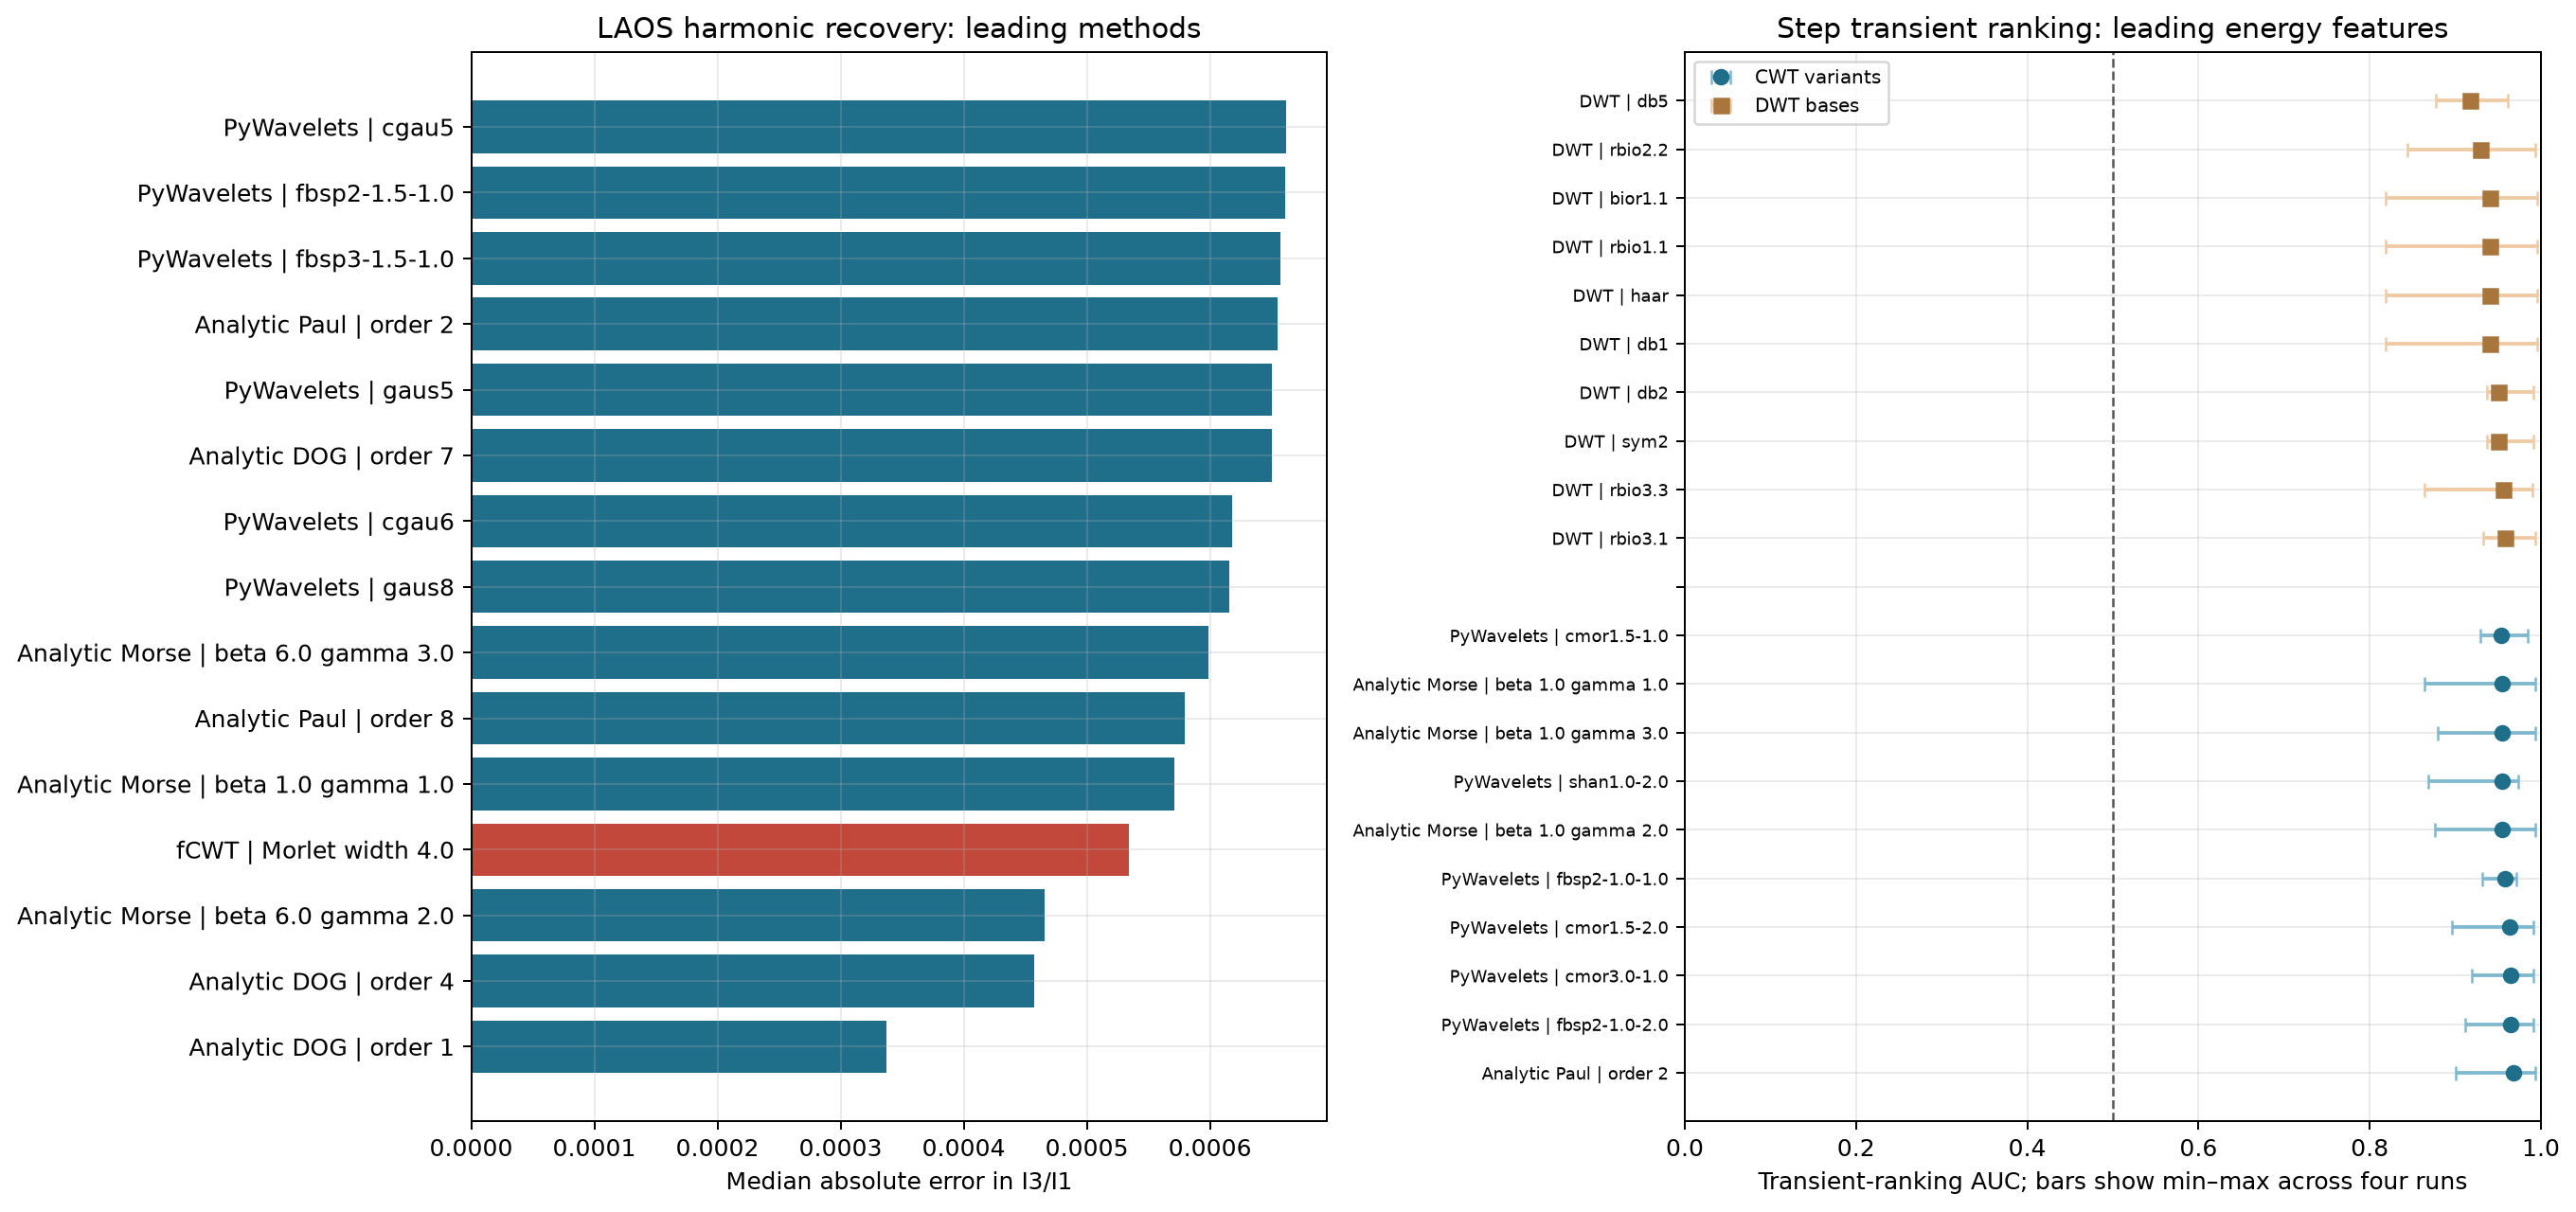

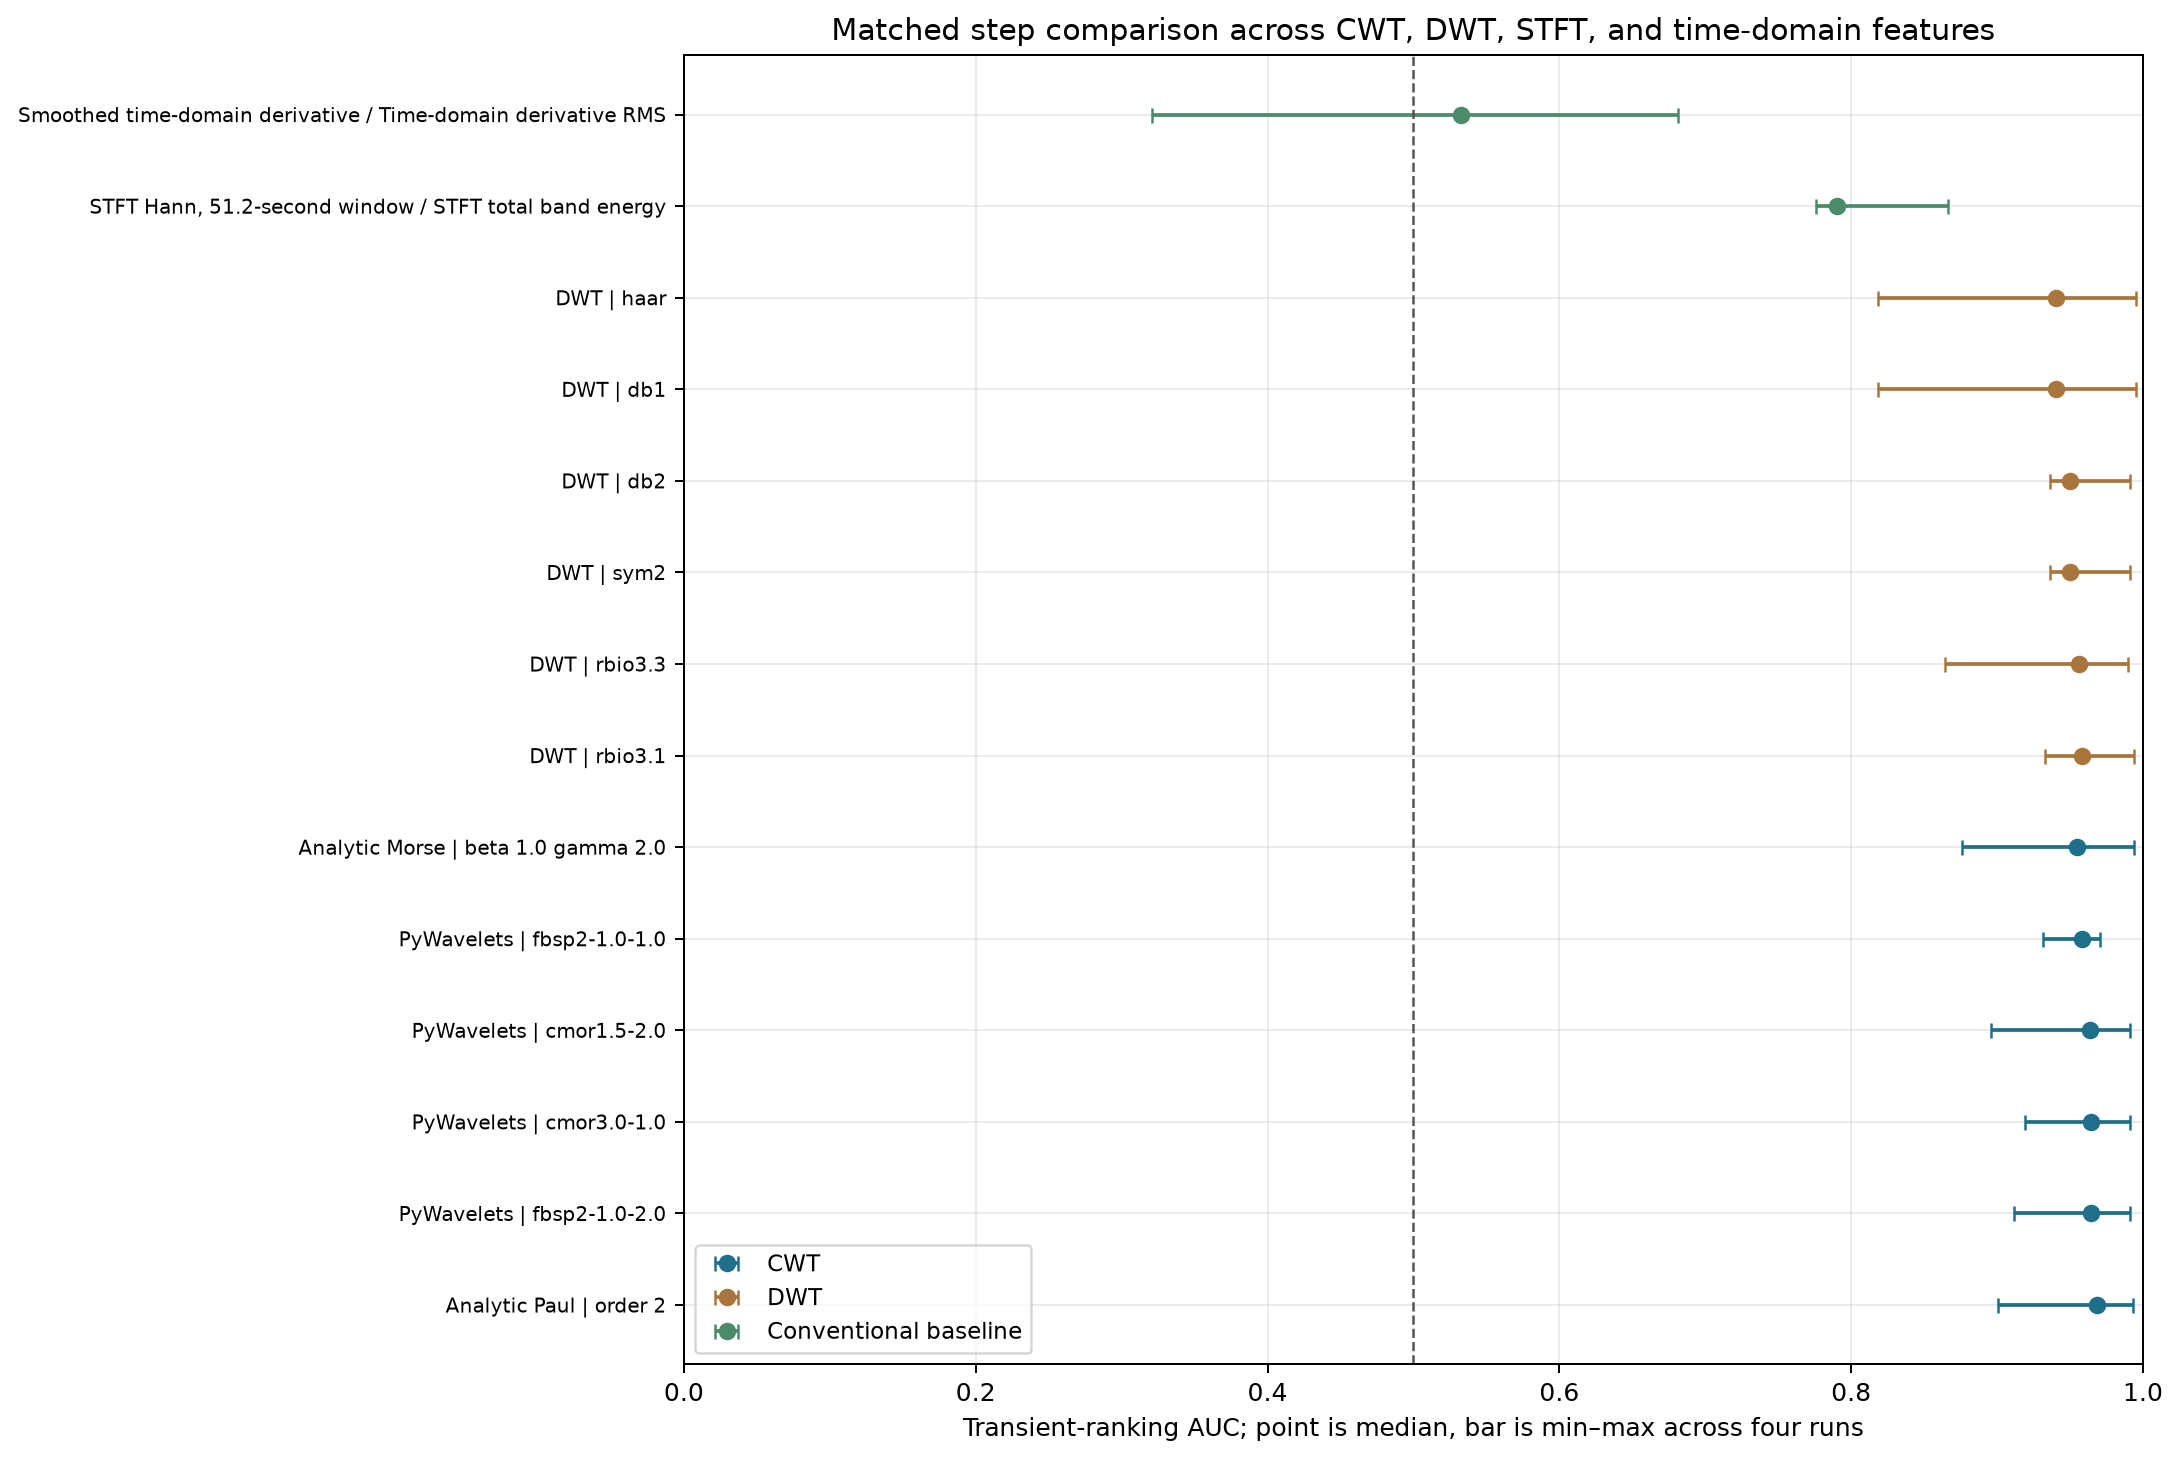

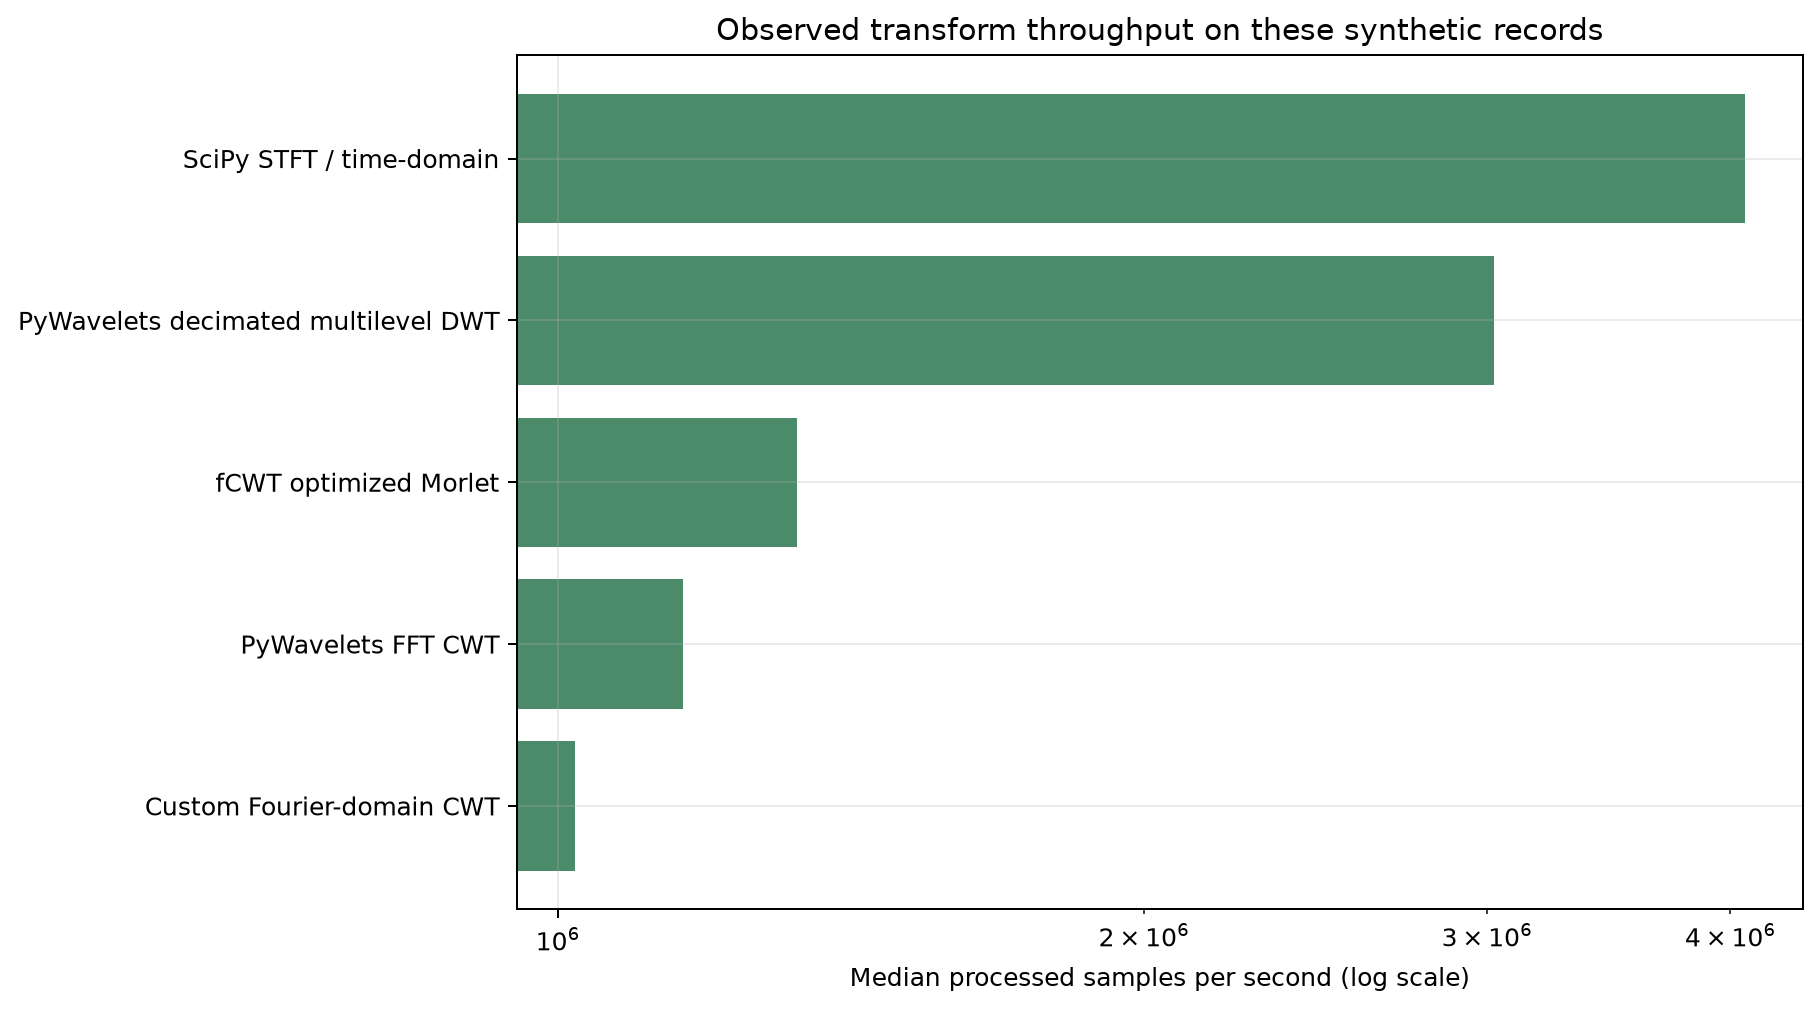

                         method_id                engine                            feature_name  median_auc  minimum_auc  maximum_auc  successful_record_count
2    STFT Hann, 51.2-second window            SciPy STFT                  STFT total band energy      0.7902       0.7760       0.8666                        4
3  Smoothed time-domain derivative  Time-domain baseline              Time-domain derivative RMS      0.5325       0.3211       0.6812                        4
1    STFT Hann, 51.2-second window            SciPy STFT                   STFT spectral entropy      0.1838       0.0890       0.3173                        4
0    STFT Hann, 51.2-second window            SciPy STFT  STFT high-to-low spectral energy ratio      0.1301       0.0393       0.2909                        4

         transform_class                               engine  median_auc  minimum_auc  maximum_auc  scored_rows
1                    CWT                   PyWavelets FFT CWT      0.9268       0.6780       0.9919          128
0                    CWT            Custom Fourier-domain CWT      0.8977       0.3152       0.9954           79
2                    CWT                fCWT optimized Morlet      0.8753       0.6161       0.9677           12
5                    DWT  PyWavelets decimated multilevel DWT      0.7460       0.2548       0.9951          424
4  Conventional baseline                 Time-domain baseline      0.5325       0.3211       0.6812            4
3  Conventional baseline                           SciPy STFT      0.2524       0.0393       0.8666           12

                           engine                wavelet_family  median_absolute_error  minimum_absolute_error  maximum_absolute_error  median_relative_error  successful_case_count
2       Custom Fourier-domain CWT  Derivative of Gaussian / DOG                0.00058                 0.00025                 0.00353                0.00698                     32
12          fCWT optimized Morlet                   Fast Morlet                0.00059                 0.00001                 0.01200                0.02376                     12
3       Custom Fourier-domain CWT             Generalized Morse                0.00062                 0.00001                 0.00342                0.00830                     36
4       Custom Fourier-domain CWT                          Paul                0.00063                 0.00037                 0.00386                0.01273                     12
11             PyWavelets FFT CWT                       Shannon                0.00081         

                              method_id                     engine               wavelet_family  median_auc  minimum_auc  maximum_auc  successful_record_count  median_runtime_seconds
17              Analytic Paul | order 2  Custom Fourier-domain CWT                         Paul      0.9684       0.9008       0.9930                        4                  0.0132
35           PyWavelets | fbsp2-1.0-2.0         PyWavelets FFT CWT           Frequency B-spline      0.9641       0.9115       0.9912                        4                  0.0171
32             PyWavelets | cmor3.0-1.0         PyWavelets FFT CWT               Complex Morlet      0.9641       0.9195       0.9909                        4                  0.0145
31             PyWavelets | cmor1.5-2.0         PyWavelets FFT CWT               Complex Morlet      0.9639       0.8962       0.9913                        4                  0.0145
34           PyWavelets | fbsp2-1.0-1.0         PyWavelets FFT CWT           Frequenc

          wavelet_family wavelet_name  median_auc  minimum_auc  maximum_auc  successful_record_count  median_runtime_seconds  median_decomposition_level
79  Reverse biorthogonal      rbio3.1      0.9581       0.9326       0.9938                        4                  0.0029                         8.0
80  Reverse biorthogonal      rbio3.3      0.9560       0.8640       0.9896                        4                  0.0029                         7.0
97               Symlets         sym2      0.9500       0.9364       0.9911                        4                  0.0027                         8.0
43            Daubechies          db2      0.9500       0.9364       0.9911                        4                  0.0028                         8.0
32            Daubechies          db1      0.9401       0.8181       0.9951                        4                  0.0029                        10.0
71                  Haar         haar      0.9401       0.8181       0.9951       

                                engine  median_samples_per_second  minimum_samples_per_second  maximum_samples_per_second  method_run_count
3             SciPy STFT / time-domain                 4067237.83                  3847730.76                  4500686.77                 4
2  PyWavelets decimated multilevel DWT                 3026249.69                   409828.29                  3898788.30               424
4                fCWT optimized Morlet                 1327694.08                   731985.03                  4376474.23                24
1                   PyWavelets FFT CWT                 1159617.86                    96579.57                  5018855.84               256
0            Custom Fourier-domain CWT                 1021109.92                   448950.99                  4134247.85               159

In [18]:
laos_wavelet_family_summary_dataframe = (
    laos_method_comparison_dataframe
    .groupby(["engine", "wavelet_family"], as_index=False)
    .agg(
        median_absolute_error=("absolute_error", "median"),
        minimum_absolute_error=("absolute_error", "min"),
        maximum_absolute_error=("absolute_error", "max"),
        median_relative_error=("relative_error", "median"),
        successful_case_count=("absolute_error", "count"),
    )
    .sort_values("median_absolute_error")
)
step_cwt_primary_records = step_wavelet_cwt_results_dataframe[
    (step_wavelet_cwt_results_dataframe["feature_name"]
     == "CWT total scale-normalized energy")
    & step_wavelet_cwt_results_dataframe["available"]
].copy()
step_dwt_primary_records = step_wavelet_dwt_results_dataframe[
    (step_wavelet_dwt_results_dataframe["feature_name"] == "DWT local detail energy")
    & step_wavelet_dwt_results_dataframe["available"]
].copy()
step_cwt_method_summary_dataframe = (
    step_cwt_primary_records.groupby(
        ["method_id", "engine", "wavelet_family"], as_index=False
    )
    .agg(
        median_auc=("auc", "median"),
        minimum_auc=("auc", "min"),
        maximum_auc=("auc", "max"),
        successful_record_count=("auc", "count"),
        median_runtime_seconds=("elapsed_seconds", "median"),
    )
    .sort_values("median_auc", ascending=False)
)
step_dwt_family_summary_dataframe = (
    step_dwt_primary_records.groupby(
        ["wavelet_family", "wavelet_name"], as_index=False
    )
    .agg(
        median_auc=("auc", "median"),
        minimum_auc=("auc", "min"),
        maximum_auc=("auc", "max"),
        successful_record_count=("auc", "count"),
        median_runtime_seconds=("elapsed_seconds", "median"),
        median_decomposition_level=("decomposition_level", "median"),
    )
    .sort_values("median_auc", ascending=False)
)

step_conventional_summary_dataframe = (
    step_conventional_results_dataframe.groupby(
        ["method_id", "engine", "feature_name"], as_index=False
    )
    .agg(
        median_auc=("auc", "median"),
        minimum_auc=("auc", "min"),
        maximum_auc=("auc", "max"),
        successful_record_count=("auc", "count"),
    )
    .sort_values("median_auc", ascending=False)
)
step_primary_method_comparison_dataframe = pd.concat([
    step_cwt_primary_records.assign(
        transform_class="CWT",
        comparison_feature="CWT total scale-normalized energy",
    ),
    step_dwt_primary_records.assign(
        transform_class="DWT",
        comparison_feature="DWT local detail energy",
    ),
    step_conventional_results_dataframe.assign(
        transform_class="Conventional baseline",
        comparison_feature=step_conventional_results_dataframe["feature_name"],
    ),
], ignore_index=True, sort=False)
step_primary_method_comparison_dataframe.to_csv(
    OUTPUT_DIRECTORY / "step_common_window_cwt_dwt_stft_comparison.csv",
    index=False,
)
step_conventional_summary_dataframe.to_csv(
    OUTPUT_DIRECTORY / "step_conventional_baseline_performance_summary.csv",
    index=False,
)

step_feature_family_summary_dataframe = (
    pd.concat([
        step_wavelet_cwt_results_dataframe.assign(transform_class="CWT"),
        step_wavelet_dwt_results_dataframe.assign(transform_class="DWT"),
        step_conventional_results_dataframe.assign(transform_class="Conventional baseline"),
    ], ignore_index=True, sort=False)
    .groupby(["transform_class", "engine", "feature_name"], as_index=False)
    .agg(
        median_auc=("auc", "median"),
        minimum_auc=("auc", "min"),
        maximum_auc=("auc", "max"),
        scored_record_count=("auc", "count"),
    )
)

laos_wavelet_family_summary_dataframe.to_csv(
    OUTPUT_DIRECTORY / "laos_cwt_family_performance_summary.csv", index=False
)
step_cwt_method_summary_dataframe.to_csv(
    OUTPUT_DIRECTORY / "step_cwt_variant_performance_summary.csv", index=False
)
step_dwt_family_summary_dataframe.to_csv(
    OUTPUT_DIRECTORY / "step_dwt_basis_performance_summary.csv", index=False
)
step_feature_family_summary_dataframe.to_csv(
    OUTPUT_DIRECTORY / "step_cwt_dwt_feature_summary.csv", index=False
)

wavelet_runtime_records = (laos_wavelet_runtime_records
                          + step_wavelet_cwt_runtime_records
                          + step_wavelet_dwt_runtime_records
                          + step_conventional_runtime_records)
wavelet_runtime_dataframe = pd.DataFrame(wavelet_runtime_records)
wavelet_runtime_dataframe.to_csv(
    OUTPUT_DIRECTORY / "expanded_wavelet_computation_times.csv", index=False
)

wavelet_feature_dictionary_records = [
    {
        "feature_name": "CWT total scale-normalized energy",
        "definition": "10-second moving mean of coefficient power divided by scale, averaged over supported frequencies",
        "interpretation": "Local oscillatory/transient activity across supported CWT frequencies",
        "caveat": "Wavelet frequency coverage varies with mother-wavelet support and record length",
    },
    {
        "feature_name": "CWT low-band energy",
        "definition": "Mean scale-normalized CWT energy below 0.15 Hz",
        "interpretation": "Slow response and long-timescale structure changes",
        "caveat": "Only frequencies with adequate finite-record support contribute",
    },
    {
        "feature_name": "CWT high-to-low energy ratio",
        "definition": "Mean scale-normalized energy at or above 0.15 Hz divided by energy below 0.15 Hz",
        "interpretation": "Balance between faster changes and slow relaxation",
        "caveat": "A high value is not inherently a material abnormality",
    },
    {
        "feature_name": "CWT scale entropy",
        "definition": "Normalized Shannon entropy of scale-normalized coefficient power across supported scales",
        "interpretation": "Spread of local signal energy across scales",
        "caveat": "Entropy depends on the selected frequency grid and support mask",
    },
    {
        "feature_name": "DWT local detail energy",
        "definition": "10-second moving mean of the sum of reconstructed detail-band energies",
        "interpretation": "Local deviation from smooth approximation across retained dyadic bands",
        "caveat": "DWT is shift-sensitive and level support is capped at 120 seconds",
    },
    {
        "feature_name": "DWT high-detail energy fraction",
        "definition": "Reconstructed detail energy with band center at or above 0.15 Hz divided by total detail energy",
        "interpretation": "Relative faster fluctuation content",
        "caveat": "Dyadic frequency bands are broad and basis-dependent",
    },
    {
        "feature_name": "DWT low-detail energy fraction",
        "definition": "Reconstructed detail energy with band center below 0.15 Hz divided by total detail energy",
        "interpretation": "Relative slower response content",
        "caveat": "The coarsest retained detail band depends on basis length and record support",
    },
    {
        "feature_name": "STFT total band energy",
        "definition": "51.2-second Hann STFT power summed from 0.02 to 0.80 Hz",
        "interpretation": "Local spectral activity over the configured frequency band",
        "caveat": "Frequency resolution depends on the fixed window length",
    },
    {
        "feature_name": "STFT high-to-low spectral energy ratio",
        "definition": "STFT energy at or above 0.15 Hz divided by energy from 0.02 to 0.15 Hz",
        "interpretation": "Relative faster versus slower oscillatory content",
        "caveat": "A high ratio is not inherently a material abnormality",
    },
    {
        "feature_name": "STFT spectral entropy",
        "definition": "Normalized Shannon entropy of STFT power across 0.02 to 0.80 Hz",
        "interpretation": "Spread of spectral energy over the analyzed band",
        "caveat": "Entropy depends on the selected frequency band and window",
    },
    {
        "feature_name": "Time-domain derivative RMS",
        "definition": "10-second moving RMS of the first derivative using actual resampled time spacing",
        "interpretation": "Local rate of stress change",
        "caveat": "Derivative features amplify measurement noise",
    },
    {
        "feature_name": "DWT scale entropy",
        "definition": "Normalized Shannon entropy of local reconstructed detail energy across decomposition levels",
        "interpretation": "Spread of local detail energy over dyadic scales",
        "caveat": "Entropy depends on decomposition depth and wavelet basis",
    },
]
wavelet_feature_dictionary_dataframe = pd.DataFrame(wavelet_feature_dictionary_records)
wavelet_feature_dictionary_dataframe.to_csv(
    OUTPUT_DIRECTORY / "expanded_wavelet_feature_dictionary.csv", index=False
)

figure, axes = plt.subplots(1, 2, figsize=(15, 7), constrained_layout=True)
top_laos_method_rows = (
    laos_method_comparison_dataframe[
        laos_method_comparison_dataframe["available"]
    ]
    .groupby(["method_id", "engine", "wavelet_family"], as_index=False)
    .agg(median_absolute_error=("absolute_error", "median"))
    .sort_values("median_absolute_error")
    .head(15)
    .sort_values("median_absolute_error", ascending=True)
)
axes[0].barh(
    top_laos_method_rows["method_id"],
    top_laos_method_rows["median_absolute_error"],
    color=[
        "#C1483B" if engine_text.startswith("fCWT")
        else "#1F6F8B" if "Wavelet" in engine_text or "CWT" in engine_text
        else "#A8763D"
        for engine_text in top_laos_method_rows["engine"]
    ],
)
axes[0].set_xlabel("Median absolute error in I3/I1")
axes[0].set_title("LAOS harmonic recovery: leading methods")
axes[0].grid(axis="x", alpha=0.25)

top_step_cwt_rows = step_cwt_method_summary_dataframe.head(10).copy()
top_step_dwt_rows = step_dwt_family_summary_dataframe.head(10).copy()
axes[1].errorbar(
    top_step_cwt_rows["median_auc"],
    np.arange(len(top_step_cwt_rows)),
    xerr=[
        top_step_cwt_rows["median_auc"] - top_step_cwt_rows["minimum_auc"],
        top_step_cwt_rows["maximum_auc"] - top_step_cwt_rows["median_auc"],
    ],
    fmt="o",
    color="#1F6F8B",
    ecolor="#7FB8CE",
    capsize=3,
    label="CWT variants",
)
axes[1].errorbar(
    top_step_dwt_rows["median_auc"],
    np.arange(len(top_step_dwt_rows)) + len(top_step_cwt_rows) + 1,
    xerr=[
        top_step_dwt_rows["median_auc"] - top_step_dwt_rows["minimum_auc"],
        top_step_dwt_rows["maximum_auc"] - top_step_dwt_rows["median_auc"],
    ],
    fmt="s",
    color="#A8763D",
    ecolor="#EFC9A2",
    capsize=3,
    label="DWT bases",
)
step_axis_labels = (
    top_step_cwt_rows["method_id"].tolist()
    + [""] 
    + [
        "DWT | " + wavelet_name
        for wavelet_name in top_step_dwt_rows["wavelet_name"].tolist()
    ]
)
axes[1].set_yticks(np.arange(len(step_axis_labels)))
axes[1].set_yticklabels(step_axis_labels, fontsize=7)
axes[1].axvline(0.5, color="#555555", linestyle="--", linewidth=1)
axes[1].set_xlim(0.0, 1.0)
axes[1].set_xlabel("Transient-ranking AUC; bars show min–max across four runs")
axes[1].set_title("Step transient ranking: leading energy features")
axes[1].legend(fontsize=8, loc="upper left")
axes[1].grid(axis="x", alpha=0.25)
figure.savefig(
    FIGURE_DIRECTORY / "06_expanded_cwt_dwt_method_comparison.png",
    bbox_inches="tight",
)
plt.show()


step_conventional_best_features = (
    step_conventional_summary_dataframe
    .sort_values("median_auc", ascending=False)
    .groupby("method_id", as_index=False)
    .first()
)
step_conventional_best_features["transform_class"] = "Conventional baseline"
step_conventional_best_features["plot_label"] = (
    step_conventional_best_features["method_id"]
    + " / "
    + step_conventional_best_features["feature_name"]
)
step_cwt_plot_records = step_cwt_method_summary_dataframe.head(6).copy()
step_cwt_plot_records["transform_class"] = "CWT"
step_cwt_plot_records["plot_label"] = step_cwt_plot_records["method_id"]
step_dwt_plot_records = step_dwt_family_summary_dataframe.head(6).copy()
step_dwt_plot_records["transform_class"] = "DWT"
step_dwt_plot_records["plot_label"] = (
    "DWT | " + step_dwt_plot_records["wavelet_name"]
)
step_common_window_plot_dataframe = pd.concat([
    step_cwt_plot_records[
        ["plot_label", "transform_class", "median_auc", "minimum_auc", "maximum_auc"]
    ],
    step_dwt_plot_records[
        ["plot_label", "transform_class", "median_auc", "minimum_auc", "maximum_auc"]
    ],
    step_conventional_best_features[
        ["plot_label", "transform_class", "median_auc", "minimum_auc", "maximum_auc"]
    ],
], ignore_index=True)
figure, axis = plt.subplots(
    figsize=(12, 8),
    constrained_layout=True,
)
transform_class_colours = {
    "CWT": "#1F6F8B",
    "DWT": "#A8763D",
    "Conventional baseline": "#4C8B6A",
}
for transform_class, class_dataframe in step_common_window_plot_dataframe.groupby(
    "transform_class", sort=False
):
    y_positions = [
        step_common_window_plot_dataframe.index.get_loc(row_index)
        for row_index in class_dataframe.index
    ]
    axis.errorbar(
        class_dataframe["median_auc"],
        y_positions,
        xerr=[
            class_dataframe["median_auc"] - class_dataframe["minimum_auc"],
            class_dataframe["maximum_auc"] - class_dataframe["median_auc"],
        ],
        fmt="o",
        color=transform_class_colours[transform_class],
        ecolor=transform_class_colours[transform_class],
        capsize=3,
        label=transform_class,
    )
axis.set_yticks(np.arange(len(step_common_window_plot_dataframe)))
axis.set_yticklabels(step_common_window_plot_dataframe["plot_label"], fontsize=8)
axis.axvline(0.5, color="#555555", linestyle="--", linewidth=1)
axis.set_xlim(0.0, 1.0)
axis.set_xlabel("Transient-ranking AUC; point is median, bar is min–max across four runs")
axis.set_title("Matched step comparison across CWT, DWT, STFT, and time-domain features")
axis.legend(fontsize=9, loc="lower left")
axis.grid(axis="x", alpha=0.25)
figure.savefig(
    FIGURE_DIRECTORY / "08_step_common_window_method_comparison.png",
    bbox_inches="tight",
)
plt.show()

runtime_by_engine_dataframe = (
    wavelet_runtime_dataframe.groupby("engine", as_index=False)
    .agg(
        median_samples_per_second=("samples_per_second", "median"),
        minimum_samples_per_second=("samples_per_second", "min"),
        maximum_samples_per_second=("samples_per_second", "max"),
        method_run_count=("samples_per_second", "count"),
    )
    .sort_values("median_samples_per_second", ascending=False)
)
runtime_by_engine_dataframe.to_csv(
    OUTPUT_DIRECTORY / "expanded_wavelet_runtime_by_engine.csv", index=False
)
figure, axis = plt.subplots(figsize=(10, 5.5), constrained_layout=True)
runtime_plot_dataframe = runtime_by_engine_dataframe.sort_values(
    "median_samples_per_second", ascending=True
)
axis.barh(
    runtime_plot_dataframe["engine"],
    runtime_plot_dataframe["median_samples_per_second"],
    color="#4C8B6A",
)
axis.set_xscale("log")
axis.set_xlabel("Median processed samples per second (log scale)")
axis.set_title("Observed transform throughput on these synthetic records")
axis.grid(axis="x", alpha=0.25)
figure.savefig(
    FIGURE_DIRECTORY / "07_expanded_wavelet_runtime_comparison.png",
    bbox_inches="tight",
)
plt.show()

print("Matched STFT and time-domain step baselines")
display(step_conventional_summary_dataframe.round(4))
print("Common-window step comparison across conventional, CWT, and DWT features")
display(step_primary_method_comparison_dataframe.groupby(["transform_class", "engine"], as_index=False).agg(median_auc=("auc", "median"), minimum_auc=("auc", "min"), maximum_auc=("auc", "max"), scored_rows=("auc", "count")).sort_values("median_auc", ascending=False).round(4))
print("Expanded LAOS comparison by method family")
display(laos_wavelet_family_summary_dataframe.head(18).round(5))
print("Leading CWT variants for the primary step energy feature")
display(step_cwt_method_summary_dataframe.head(15).round(4))
print("Leading DWT bases for the primary step detail-energy feature")
display(step_dwt_family_summary_dataframe.head(15).round(4))
print("Transform throughput by implementation")
display(runtime_by_engine_dataframe.round(2))

## Interpretation and limitations

The expanded tables and figures above are the current results for this notebook. The earlier Mexican-hat-only step score and the first CWT comparison are retained as a baseline audit, not as the final family-wide conclusion. Use the exported tables to discuss performance by task: harmonic recovery and transient ranking measure different objectives.

The fCWT result is reported as a measured implementation/runtime comparison; no universal speedup is assumed. In this run the library reported missing saved optimization schemes and fell back to its non-optimized path. Its Morlet width convention differs from PyWavelets, so interpret agreement after frequency calibration and compare speed on the same input machine. The custom Paul, DOG, and generalized Morse transforms use normalized Fourier-domain mother-wavelet responses and are identified explicitly in the method inventory.

The continuous-wavelet family coverage is exhaustive for the installed PyWavelets built-in names, with a stated finite parameter grid for cmor, fbsp, and shan. The DWT basis inventory covers every built-in discrete PyWavelets name. Other libraries can define additional bases, and continuous parameter values are infinite; the sweep is therefore broad and reproducible rather than literally every wavelet ever defined.

AUC is computed from autocorrelated samples and should not be presented as an independent-sample significance test. There are only four context-valid step experiments, and each is synthetic. The wavelet support mask and 120-second DWT support cap trade frequency coverage for interpretable timing. Results do not establish a blood-specific advantage or prove that wavelets outperform Fourier methods. Report errors, coverage, quality status, computational cost, and each method's task together.

## References

1. Armstrong et al. (2021), “A simple approach for adding thixotropy to an elasto-visco-plastic rheological model,” *JNNFM* 290, 104503. [doi:10.1016/j.jnnfm.2021.104503](https://doi.org/10.1016/j.jnnfm.2021.104503)
2. Pincot et al. (2023), “Characterizing blood hysteresis via tensorial thixo-elasto-viscoplastic modeling,” *Physics of Fluids* 35, 113104. [doi:10.1063/5.0169051](https://doi.org/10.1063/5.0169051)
3. Pincot & Armstrong (2021), “Novel tensorial thixo-visco-plastic framework for rheological characterization of human blood,” *Scientific Reports* 11, 22004. [doi:10.1038/s41598-021-01362-8](https://doi.org/10.1038/s41598-021-01362-8)
4. Armstrong & Pincot (2021), “Integration of thixotropy into Giesekus model for characterization of human blood,” *AIP Advances* 11, 035029. [doi:10.1063/5.0045578](https://doi.org/10.1063/5.0045578)
5. Armstrong et al. (2022), “Recent advances in understanding and predicting complex behavior of human blood with thixo-elasto-visco-plastic models,” *Frontiers in Physics* 10, 889065. [doi:10.3389/fphy.2022.889065](https://doi.org/10.3389/fphy.2022.889065)
6. Project literature inventory: [literature_review_and_method_inventory.md](/Users/riamishra/Desktop/Haemograph_Project/00_Project_Admin/Foundational_Review/literature_review_and_method_inventory.md).

7. Torrence and Compo (1998), “A Practical Guide to Wavelet Analysis,” *Bulletin of the American Meteorological Society* 79(1), 61–78. [doi:10.1175/1520-0477(1998)079<0061:APGTWA>2.0.CO;2](https://doi.org/10.1175/1520-0477(1998)079%3C0061%3AAPGTWA%3E2.0.CO;2)
8. Lilly and Olhede (2012), “Generalized Morse Wavelets as a Class of Exact Analytic Wavelets,” *IEEE Transactions on Signal Processing* 60(11), 6036–6041. [doi:10.1109/TSP.2012.2210890](https://doi.org/10.1109/TSP.2012.2210890)
9. PyWavelets documentation: [continuous and discrete wavelet names](https://pywavelets.readthedocs.io/en/latest/ref/wavelets.html), [CWT scale/frequency and edge behavior](https://pywavelets.readthedocs.io/en/latest/ref/cwt.html).
10. fCWT project source and interface: [fastlib/fCWT](https://github.com/fastlib/fCWT).
